# JEPA-VLM · object hallucination · GPU controls: corrupted-image DLA cache (step 3) + component ablations (step 4) + attribution patching (step 5)

Same model and DLA machinery as the main notebook (`best.pt` projector + Vicuna-7B, 4-bit, T4 x2, Internet On).
Add as input: `jepa-projector-fixed-ckpts`, `vlm-questions`, COCO val2014, and **`dla-output`** (the analysis notebook's output dataset: `candidates.json`, `step1c_answer_vs_truth.csv`, ...). If `dla-output` is missing, paste component names into `MANUAL_COMPONENTS`.

**Step 3, corrupted-image control.** Re-caches the DLA components for the same 3000 questions with the image destroyed (`CONTROL_MODE`):
- `noise`: Gaussian noise with std 3x the sample's own visual-token std is added to the projected image tokens (the corruption used in the dual-pathway paper).
- `shuffle`: each question gets the image of a different COCO image (in distribution, wrong content).
- `none`: the 784 image tokens are removed; the prompt is `[BOS][text]` only. This is the purest language prior, but the text moves from positions ~785+ to 0+, so part of any difference can come from the position shift and not from the missing image. Run all three modes if you can: findings that agree across them are robust, and disagreements show which part of the 'image-driven' signal is a corruption artefact.

Output has exactly the same format as `dla-jepa-vicuna` (dataset `dla-jepa-vicuna-<mode>`), so the analysis notebook can subtract clean minus corrupted to isolate the image-driven part of every component.

**Step 4, ablations.** Components are scaled (default 0 = removed) at the **final token position only**. The image + prompt prefix is run once and cached (KV cache); each ablation then costs one token. Consequence: the test captures a component's direct effect plus everything it changes downstream *at the last position*; effects routed through other positions are not covered. Candidates are chosen on questions whose image id is even and evaluated on questions whose image id is odd only, so selection and evaluation never share questions.

**Step 5, attribution patching.** One gradient per question estimates what patching every head/MLP output at the final token from the corrupted run into the clean run would do to the Yes-No logit. It includes indirect effects that DLA misses; it is a first-order approximation, so cell 5b validates it against exact patching first.

Run order: config -> models -> prompting -> questions -> DLA machinery -> upload helpers -> step 3 cells -> step 4a (needed by step 5) -> step 4 cells -> step 5 cells. Steps 3, 4, 5, 6, 7 are gated by `RUN_STEP3` / `RUN_STEP4` / `RUN_STEP5` / `RUN_STEP6` / `RUN_STEP7`; the defining cells (3a, 4a, 4b, 5a, 5b, 6a) always run. Steps 6 and 7 are described in the section after step 5. Step 5 uses `CONTROL_MODE` as its corrupted run.

In [1]:
# 0. INSTALL (run once, then restart the session and skip this cell)
!pip install -q transformers==5.16.1 accelerate==1.14.0 bitsandbytes==0.50.2 pillow==12.3.0 sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 48.3 MB/s eta 0:00:00:00:0100:01


In [2]:
# 1. CONFIG
import os, re, json, glob, math, time, random, shutil, subprocess
from collections import Counter

USERNAME      = "ponishbhatia2"
CKPT_DIR      = f"/kaggle/input/datasets/{USERNAME}/jepa-projector-fixed-ckpts"
CKPT_NAME     = "best.pt"                     # best.pt = val 1.8704 (final.pt is overfit: 1.8942)
LLM_PATH      = "lmsys/vicuna-7b-v1.5"
VIT_ID        = "facebook/ijepa_vith16_1k"

QUESTIONS_JSON = f"/kaggle/input/datasets/{USERNAME}/vlm-questions/all_questions.json"   # same file Rohan used (17492 questions, version 2)
IMG_DIR        = "/kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014"             # POPE images (object questions are all POPE)

HALLUC_TYPE   = "object"                      # filter: hallucination_type == "object" and answer_format == "yes_no" (3000 questions, as in Rohan's run)
MAX_SAMPLES   = None                          # None = all; or an int for a smaller test run
SEED          = 0

PROMPT_KEY    = "vicuna"                      # one of PROMPTS below; compare in section 4 and change if another is better
PROMPTS = {
    "vicuna": "A chat between a curious human and an artificial intelligence assistant. USER: {q} Answer with Yes or No. ASSISTANT:",
    "plain":  "Question: {q} Answer with yes or no.\nAnswer:",
    "bare":   "{q} Please answer yes or no.\nAnswer:",
}

N_GALLERY     = 12
N_QUICK_EVAL  = 200

# DLA caching: same layout as Rohan's dla-llava dataset ({type}_batch_{i}.pt, 200 entries per file, dla_meta.json)
BATCH_SAVE_SIZE   = 200
DLA_DIR           = "/kaggle/working/dla_jepa_ctrl"   # overwritten below with the mode name
DATASET_SLUG      = "dla-jepa-vicuna"                          # his is dla-llava; rename if you prefer
UPLOAD            = True
UPLOAD_EVERY      = 5                                          # batches between Kaggle dataset versions (a final upload always happens)
FORCE_FRESH       = False                                      # True: ignore batches already in DLA_DIR / the mounted dataset

random.seed(SEED)
os.makedirs(DLA_DIR, exist_ok=True)

# ---------------- controls-specific settings ----------------
RUN_STEP3     = True
RUN_STEP4     = True
RUN_STEP5     = True
RUN_STEP6     = True                # mean-ablation + AUROC
RUN_STEP7     = True                # patching sweeps (last position, K/V)
DLA_OUT_SLUG  = "dla-output"         # dataset with the analysis notebook's outputs (candidates.json, step1c_answer_vs_truth.csv, ...)
N_AP          = 600                # step 5: questions (balanced yes/no) for attribution patching, ~2 s each
CONTROL_MODE  = "noise"            # "noise" (paper), "shuffle" or "none" (no image tokens); run the notebook once per mode
SOFT_FAIL     = True               # True: a failing compute/result cell prints its traceback and the notebook carries on; False: stop at the first error
NOISE_MULT    = 0.5                # noise std = NOISE_MULT x std of the clean projected visual tokens
DLA_DIR       = f"/kaggle/working/dla_jepa_{CONTROL_MODE}"
DATASET_SLUG  = f"dla-jepa-vicuna-{CONTROL_MODE}"
os.makedirs(DLA_DIR, exist_ok=True)

# step 4
N_ABL         = 1000               # evaluation questions (balanced yes/no, odd question numbers only)
SCALES        = [0.0, 0.5]         # 0 = remove the component output, 0.5 = halve it
K_GROUPS      = [3, 5, 10]         # group sizes for the hallucination-pathway / grounding-pathway ablations
N_RANDOM      = 3                  # random matched-size control sets per group
MANUAL_COMPONENTS = []             # e.g. ["L26H3", "L20.mlp"]; used when no candidates.json is attached
DEFAULT_SINGLES = ["L26H3", "L16H0", "L17H16", "L24H8", "L19H10", "L20.mlp", "L28.mlp", "L18.mlp"]   # from the clean-cache DLA plots

In [3]:
# 2. LOAD MODELS
import numpy as np, torch, torch.nn as nn
from PIL import Image
import transformers, bitsandbytes
from transformers import LlamaTokenizer, AutoModel, AutoImageProcessor, AutoModelForCausalLM, BitsAndBytesConfig

print("transformers", transformers.__version__, "| bitsandbytes", bitsandbytes.__version__, "| torch", torch.__version__)
assert torch.cuda.is_available(), "No GPU: set Accelerator to T4 x2"
device = "cuda:0"

tokenizer = LlamaTokenizer.from_pretrained(LLM_PATH)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
toks = tokenizer.convert_ids_to_tokens(tokenizer("A yellow clock that is on the floor.").input_ids)
EXPECT = ["<s>", "▁A", "▁yellow", "▁clock", "▁that", "▁is", "▁on", "▁the", "▁floor", "."]
assert toks == EXPECT, f"TOKENIZER BROKEN: {toks}"
print(type(tokenizer).__name__, "OK")

# projector checkpoint
ck_path = f"{CKPT_DIR}/{CKPT_NAME}"
if not os.path.exists(ck_path):
    alt = sorted(glob.glob(f"/kaggle/input/**/jepa-projector-fixed-ckpts/{CKPT_NAME}", recursive=True))
    assert alt, f"checkpoint not found: {ck_path}"
    ck_path = alt[-1]
ck = torch.load(ck_path, map_location="cpu", weights_only=False)
assert ck.get("meta", {}).get("tokenizer") == "LlamaTokenizer", "checkpoint was not trained with the fixed tokenizer"
print(f"loaded {ck_path} | step {ck['step']} | best val {ck.get('best')}")

image_processor = AutoImageProcessor.from_pretrained(VIT_ID)
vit = AutoModel.from_pretrained(VIT_ID).to(device).eval()
for p in vit.parameters(): p.requires_grad_(False)
vit_dtype = next(vit.parameters()).dtype

llm = AutoModelForCausalLM.from_pretrained(
    LLM_PATH, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map={"": 0}, low_cpu_mem_usage=True).eval()
for p in llm.parameters(): p.requires_grad_(False)
LLM_DTYPE = next(llm.parameters()).dtype
H = llm.config.hidden_size
N_LAYERS = llm.config.num_hidden_layers
N_HEADS = llm.config.num_attention_heads
HEAD_DIM = H // N_HEADS
assert LLM_DTYPE == torch.float16

class MLPProjector(nn.Module):
    def __init__(self, v, l):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(v, l), nn.GELU(), nn.Linear(l, l))
    def forward(self, x): return self.proj(x)

P = MLPProjector(1280, H).to(device)
P.load_state_dict(ck["projector"]); P.eval()
for p in P.parameters(): p.requires_grad_(False)
print("vit", vit_dtype, "| llm", LLM_DTYPE, "| hidden", H, "| layers", N_LAYERS, "| heads", N_HEADS)

transformers 5.16.1 | bitsandbytes 0.50.2 | torch 2.11.0+cu128


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/438 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


vit torch.float32 | llm torch.float16 | hidden 4096 | layers 32 | heads 32


In [4]:
# 3. PROMPTING + YES/NO SCORING
def toks_to_ids(cands):
    out = []
    for t in cands:
        i = tokenizer.convert_tokens_to_ids(t)
        if i is not None and i != tokenizer.unk_token_id and i not in out: out.append(i)
    return out
YES_IDS = toks_to_ids(["▁Yes", "Yes", "▁yes", "yes"])
NO_IDS  = toks_to_ids(["▁No", "No", "▁no", "no"])
YES_ID, NO_ID = YES_IDS[0], NO_IDS[0]            # "▁Yes" / "▁No": same ids Rohan used for LLaVA (shared Llama vocabulary)
assert (YES_ID, NO_ID) == (3869, 1939), (YES_ID, NO_ID)
assert tokenizer.convert_ids_to_tokens(YES_ID) == "▁Yes" and tokenizer.convert_ids_to_tokens(NO_ID) == "▁No"
print("yes ids", dict(zip(tokenizer.convert_ids_to_tokens(YES_IDS), YES_IDS)), "| no ids", dict(zip(tokenizer.convert_ids_to_tokens(NO_IDS), NO_IDS)))

def load_img(path): return Image.open(path).convert("RGB")

@torch.no_grad()
def encode_image(path):
    pv = image_processor(load_img(path), return_tensors="pt")["pixel_values"].to(device, dtype=vit_dtype)
    feats = vit(pixel_values=pv).last_hidden_state            # (1, 784, 1280)
    proj = P(feats.float())                                  # (1, 784, 4096)
    return feats, proj

@torch.no_grad()
def build_embeds(proj, question, prompt_key=None):
    # layout identical to training: [image tokens][BOS][text]
    text = PROMPTS[prompt_key or PROMPT_KEY].format(q=question.strip())
    ids = torch.tensor([tokenizer(text).input_ids], device=device)         # starts with BOS
    te = llm.get_input_embeddings()(ids).float()
    return torch.cat([proj, te], 1).to(LLM_DTYPE), ids

def score_from_logits(lg):
    lg = lg.float()
    y = torch.logsumexp(lg[YES_IDS], 0).item(); n = torch.logsumexp(lg[NO_IDS], 0).item()
    return y, n, ("yes" if y > n else "no"), 1 / (1 + math.exp(-(y - n)))

@torch.no_grad()
def answer(path, question, prompt_key=None):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question, prompt_key)
    lg = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1]
    return score_from_logits(lg)

@torch.no_grad()
def generate_text(path, question, max_new=6):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question)
    out = llm.generate(inputs_embeds=emb, attention_mask=torch.ones(emb.shape[:2], dtype=torch.long, device=device),
                       max_new_tokens=max_new, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()

yes ids {'▁Yes': 3869, 'Yes': 8241, '▁yes': 4874, 'yes': 3582} | no ids {'▁No': 1939, 'No': 3782, '▁no': 694, 'no': 1217}


In [5]:
# 4. LOAD OBJECT-HALLUCINATION YES/NO QUESTIONS
with open(QUESTIONS_JSON) as f: all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2 (17492 questions)"
print(len(all_questions), "questions | types:", dict(Counter(q["hallucination_type"] for q in all_questions)))
recs = [dict(q, gt=str(q["ground_truth_answer"]).strip().lower(), path=os.path.join(IMG_DIR, f"{q['image_id']}.jpg"))
        for q in all_questions if q["hallucination_type"] == HALLUC_TYPE and q["answer_format"] == "yes_no"]
missing = [r for r in recs if not os.path.exists(r["path"])]
print(f"{HALLUC_TYPE}: {len(recs)} yes/no questions | missing images: {len(missing)} | gt: {dict(Counter(r['gt'] for r in recs))}")
assert recs and not missing, "check IMG_DIR / question file"
if MAX_SAMPLES: recs = recs[:MAX_SAMPLES]

17492 questions | types: {'object': 3000, 'attribute': 7628, 'relation': 6864}
object: 3000 yes/no questions | missing images: 0 | gt: {'yes': 1500, 'no': 1500}


In [6]:
# 7. DLA MACHINERY (same math and hook points as Rohan's collect_llava.ipynb)
# u = ln_f.weight * (W_U[yes] - W_U[no]). embed / attn[layer, head] / mlp[layer] / resid_dot are RAW projections onto u;
# divide by rms to get logit units.  embed + sum(attn) + sum(mlp) = resid_dot,  resid_dot / rms = logit_diff.
lm_head, ln_f, layers = llm.lm_head, llm.model.norm, llm.model.layers
n_layer, n_head, head_dim = N_LAYERS, N_HEADS, HEAD_DIM
u = (ln_f.weight.float() * (lm_head.weight[YES_ID] - lm_head.weight[NO_ID]).float()).to(device)

# head_proj[l] = W_O^T.view(n_head, head_dim, hidden) @ u.  The 4-bit o_proj weight is packed, so get W_O^T by applying o_proj to the identity.
eye = torch.eye(H, dtype=LLM_DTYPE, device=device)
with torch.no_grad():
    head_proj = [(layers[l].self_attn.o_proj(eye).float() @ u).view(n_head, head_dim) for l in range(n_layer)]
del eye; torch.cuda.empty_cache()

_dla_cache = {}
def _make_attn_hook(l):
    def hook(module, args):
        z = args[0][0, -1].float().reshape(n_head, head_dim)
        _dla_cache[f"attn_{l}"] = (z * head_proj[l]).sum(-1)
    return hook
def _make_mlp_hook(l):
    def hook(module, args, output):
        o = output[0] if isinstance(output, tuple) else output
        _dla_cache[f"mlp_{l}"] = o[0, -1].float() @ u
    return hook
def _final_norm_hook(module, args):
    h = args[0][0, -1].float()
    _dla_cache["resid_dot"] = h @ u
    _dla_cache["rms"] = torch.sqrt(h.pow(2).mean() + ln_f.variance_epsilon)

_hook_handles = []
for l, layer in enumerate(layers):
    _hook_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_make_attn_hook(l)))
    _hook_handles.append(layer.mlp.register_forward_hook(_make_mlp_hook(l)))
_hook_handles.append(ln_f.register_forward_pre_hook(_final_norm_hook))
print(len(_hook_handles), "hooks registered")

@torch.no_grad()
def dla_question(image_path, question_text):
    feats, proj = encode_image(image_path)
    emb, ids = build_embeds(proj, question_text)
    _dla_cache.clear()
    last_logits = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(last_logits)
    entry = {
        "embed": (emb[0, -1].float() @ u).cpu(),                     # embedding of the last prompt token = layer-0 residual input
        "attn": torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]),   # [layer, head]
        "mlp": torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]),     # [layer]
        "resid_dot": _dla_cache["resid_dot"].cpu(),
        "rms": _dla_cache["rms"].cpu(),
        "logit_diff": (last_logits[YES_ID] - last_logits[NO_ID]).cpu(),
        "answer_text": tokenizer.decode(last_logits.argmax().item()).strip(),
        # extras beyond Rohan's format (ignored by his analysis code)
        "pred": pred, "p_yes": py, "yesno_score": y - n,
    }
    return entry

# sanity check on 6 samples: components must add up to the final residual and to the real logit difference
for r in recs[:6]:
    e = dla_question(r["path"], r["question_text"])
    total = e["embed"] + e["attn"].sum() + e["mlp"].sum()
    scale = e["embed"].abs() + e["attn"].abs().sum() + e["mlp"].abs().sum()
    rel = ((total - e["resid_dot"]).abs() / scale).item(); err = (total / e["rms"] - e["logit_diff"]).abs().item()
    print(f"logit diff {e['logit_diff']:+.3f} | sum of components {(total / e['rms']):+.3f} | rel err resid {rel:.5f} | abs err {err:.4f} | argmax token {e['answer_text']!r}")
    assert rel < 0.05 and err < 0.5, "DLA decomposition does not match the model: do not cache until fixed"
print("DLA decomposition OK")

65 hooks registered
logit diff +0.688 | sum of components +0.678 | rel err resid 0.00003 | abs err 0.0093 | argmax token 'Yes'
logit diff -0.703 | sum of components -0.700 | rel err resid 0.00005 | abs err 0.0027 | argmax token 'No'
logit diff +0.250 | sum of components +0.254 | rel err resid 0.00002 | abs err 0.0041 | argmax token 'Yes'
logit diff -0.375 | sum of components -0.380 | rel err resid 0.00006 | abs err 0.0048 | argmax token 'No'
logit diff -0.328 | sum of components -0.331 | rel err resid 0.00002 | abs err 0.0029 | argmax token 'No'
logit diff -0.484 | sum of components -0.480 | rel err resid 0.00004 | abs err 0.0048 | argmax token 'No'
DLA decomposition OK


In [32]:
# SIGMA SWEEP: pick NOISE_MULT before the long run. Needs the model, encode_image, build_embeds, score_from_logits and recs from the notebook (run after the DLA-machinery cell).
import numpy as np, torch, random
from scipy.stats import rankdata
N_PER_CLASS = 60                                   # 120 questions in total, about 8-15 min
MULTS = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0]             # 0.0 = clean reference
PER_DIM = False                                    # True: noise std per embedding dimension instead of one global std

rs = random.Random(123)
qy = [r for r in recs if r["gt"] == "yes"]; qn = [r for r in recs if r["gt"] == "no"]
Q = rs.sample(qy, N_PER_CLASS) + rs.sample(qn, N_PER_CLASS); rs.shuffle(Q)      # shuffled so the running accuracy is meaningful while it works
gt_yes = np.array([r["gt"] == "yes" for r in Q])

def _auroc(x, pos):
    r = rankdata(x); n1 = pos.sum(); n0 = len(pos) - n1
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

@torch.no_grad()
def delta_of(proj, q):
    emb, _ = build_embeds(proj, q)
    lg = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(lg); return y - n

# text-token embedding norm, the scale the LLM is used to
Wemb = llm.get_input_embeddings().weight
txt_norm = Wemb[torch.randint(0, Wemb.shape[0], (2000,))].float().norm(dim=-1).mean().item()

import time
T0 = time.time()
projs = []
for i, r in enumerate(Q):
    projs.append(encode_image(r["path"])[1])
    if (i + 1) % 20 == 0: print(f"encoding images {i + 1}/{len(Q)} | {time.time() - T0:.0f}s", flush=True)
norm_clean = float(np.mean([p.float().norm(dim=-1).mean().item() for p in projs]))
print(f"mean token norm: image {norm_clean:.1f}, text-embedding {txt_norm:.1f}\n", flush=True)

D = {}; NORM = {}
HDR = f"{'setting':>9} {'acc':>6} {'yes-rate':>8} {'AUROC(gt)':>9} {'corr w/ clean':>13} {'flip vs clean':>13} {'tok norm / clean':>16}"
def row(m):
    d = D[m]; clean = D[0.0]; nr = "" if isinstance(m, str) else f"{NORM[m] / norm_clean:.2f}"
    return f"{str(m):>9} {((d > 0) == gt_yes).mean():6.3f} {(d > 0).mean():8.3f} {_auroc(d, gt_yes):9.3f} {np.corrcoef(d, clean)[0, 1] if np.std(d) > 0 else float('nan'):13.3f} {((d > 0) != (clean > 0)).mean():13.3f} {nr:>16}"

SETTINGS = MULTS + ["shuffle", "none"]
for si, m in enumerate(SETTINGS):
    out = []; nrm = []; t_set = time.time()
    for i, (r, p) in enumerate(zip(Q, projs)):
        if m == "none":
            emb, _ = build_embeds(p[:, :0], r["question_text"]); lg = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float(); y, n, _, _ = score_from_logits(lg); out.append(y - n)
        elif m == "shuffle":
            j = (i + 7) % len(Q); j = j if Q[j]["image_id"] != r["image_id"] else (i + 13) % len(Q); out.append(delta_of(projs[j], r["question_text"]))
        else:
            g = torch.Generator(device=p.device).manual_seed(1000 + i)
            s_ = p.float().std(dim=(0, 1), keepdim=True) if PER_DIM else p.float().std()
            pn = p + (m * s_ * torch.randn(p.shape, generator=g, device=p.device, dtype=torch.float32)).to(p.dtype); nrm.append(pn.float().norm(dim=-1).mean().item())
            out.append(delta_of(pn, r["question_text"]))
        if (i + 1) % 20 == 0:
            o = np.array(out); gy = gt_yes[:len(o)]; el = time.time() - t_set; left_set = el / (i + 1) * (len(Q) - i - 1); left_rest = (len(SETTINGS) - si - 1) * el / (i + 1) * len(Q)
            print(f"  [{si + 1}/{len(SETTINGS)}] {str(m):>7} {i + 1:>3}/{len(Q)} | running acc {((o > 0) == gy).mean():.2f}, yes-rate {(o > 0).mean():.2f} | ETA this setting {left_set:.0f}s, all {(left_set + left_rest) / 60:.1f} min", flush=True)
    D[m] = np.array(out); NORM[m] = float(np.mean(nrm)) if nrm else float("nan")
    if m == 0.0:
        clean = D[0.0]; print(f"\nclean reference: acc {((clean > 0) == gt_yes).mean():.3f}, yes-rate {(clean > 0).mean():.3f}\n{HDR}", flush=True)
    print(row(m), flush=True)

print("\n" + HDR)
for m in SETTINGS: print(row(m))
print("""
How to read: pick the SMALLEST multiplier where
  - AUROC(gt) is about 0.5 (the corrupted run no longer knows the truth; compare with 'none'/'shuffle'), and
  - corr with clean has dropped to about 0 (no image information left), and
  - yes-rate has not collapsed to 0 or 1 (collapse = the model is off-distribution rather than uninformed).
If AUROC is already ~0.5 at 1.0 or 2.0, use that: larger values only add out-of-distribution artefacts.""")

encoding images 20/120 | 11s
encoding images 40/120 | 21s
encoding images 60/120 | 30s
encoding images 80/120 | 40s
encoding images 100/120 | 49s
encoding images 120/120 | 59s
mean token norm: image 74.5, text-embedding 1.1

  [1/8]     0.0  20/120 | running acc 0.80, yes-rate 0.55 | ETA this setting 85s, all 13.2 min
  [1/8]     0.0  40/120 | running acc 0.75, yes-rate 0.42 | ETA this setting 70s, all 13.3 min
  [1/8]     0.0  60/120 | running acc 0.80, yes-rate 0.43 | ETA this setting 52s, all 13.1 min
  [1/8]     0.0  80/120 | running acc 0.79, yes-rate 0.44 | ETA this setting 35s, all 12.7 min
  [1/8]     0.0 100/120 | running acc 0.78, yes-rate 0.45 | ETA this setting 17s, all 12.4 min
  [1/8]     0.0 120/120 | running acc 0.75, yes-rate 0.43 | ETA this setting 0s, all 12.1 min

clean reference: acc 0.750, yes-rate 0.433
  setting    acc yes-rate AUROC(gt) corr w/ clean flip vs clean tok norm / clean
      0.0  0.750    0.433     0.845         1.000         0.000             1.00


KeyboardInterrupt: 

encoding images 20/120 | 8s
encoding images 40/120 | 16s
encoding images 60/120 | 24s
encoding images 80/120 | 32s
encoding images 100/120 | 41s
encoding images 120/120 | 49s
mean token norm: image 74.5, text-embedding 1.1

  [1/8]     0.0  20/120 | running acc 0.80, yes-rate 0.55 | ETA this setting 88s, all 13.8 min
  [1/8]     0.0  40/120 | running acc 0.75, yes-rate 0.42 | ETA this setting 71s, all 13.6 min
  [1/8]     0.0  60/120 | running acc 0.80, yes-rate 0.43 | ETA this setting 55s, all 13.7 min
  [1/8]     0.0  80/120 | running acc 0.79, yes-rate 0.44 | ETA this setting 37s, all 13.6 min
  [1/8]     0.0 100/120 | running acc 0.78, yes-rate 0.45 | ETA this setting 18s, all 13.3 min
  [1/8]     0.0 120/120 | running acc 0.75, yes-rate 0.43 | ETA this setting 0s, all 12.9 min

clean reference: acc 0.750, yes-rate 0.433
  setting    acc yes-rate AUROC(gt) corr w/ clean flip vs clean tok norm / clean
      0.0  0.750    0.433     0.845         1.000         0.000             1.00
  [2/8]     0.5  20/120 | running acc 0.70, yes-rate 0.65 | ETA this setting 92s, all 12.6 min
  [2/8]     0.5  40/120 | running acc 0.65, yes-rate 0.57 | ETA this setting 75s, all 12.5 min
  [2/8]     0.5  60/120 | running acc 0.50, yes-rate 0.60 | ETA this setting 56s, all 12.2 min
  [2/8]     0.5  80/120 | running acc 0.54, yes-rate 0.61 | ETA this setting 37s, all 11.8 min
  [2/8]     0.5 100/120 | running acc 0.55, yes-rate 0.60 | ETA this setting 19s, all 11.5 min
  [2/8]     0.5 120/120 | running acc 0.53, yes-rate 0.62 | ETA this setting 0s, all 11.2 min
      0.5  0.533    0.617     0.558         0.047         0.517             1.21
  [3/8]     1.0  20/120 | running acc 0.50, yes-rate 0.75 | ETA this setting 93s, all 10.9 min
  [3/8]     1.0  40/120 | running acc 0.50, yes-rate 0.82 | ETA this setting 74s, all 10.5 min
  [3/8]     1.0  60/120 | running acc 0.50, yes-rate 0.83 | ETA this setting 56s, all 10.2 min
  [3/8]     1.0  80/120 | running acc 0.54, yes-rate 0.84 | ETA this setting 37s, all 9.9 min
  [3/8]     1.0 100/120 | running acc 0.52, yes-rate 0.77 | ETA this setting 19s, all 9.6 min
  [3/8]     1.0 120/120 | running acc 0.53, yes-rate 0.77 | ETA this setting 0s, all 9.3 min
      1.0  0.533    0.767     0.536        -0.011         0.517             1.62
  [4/8]     2.0  20/120 | running acc 0.50, yes-rate 0.05 | ETA this setting 94s, all 9.1 min
  [4/8]     2.0  40/120 | running acc 0.53, yes-rate 0.05 | ETA this setting 75s, all 8.8 min
  [4/8]     2.0  60/120 | running acc 0.58, yes-rate 0.05 | ETA this setting 56s, all 8.4 min
  [4/8]     2.0  80/120 | running acc 0.57, yes-rate 0.05 | ETA this setting 37s, all 8.1 min
  [4/8]     2.0 100/120 | running acc 0.55, yes-rate 0.04 | ETA this setting 19s, all 7.8 min
  [4/8]     2.0 120/120 | running acc 0.52, yes-rate 0.03 | ETA this setting 0s, all 7.5 min
      2.0  0.517    0.033       nan           nan         0.417             2.62
  [5/8]     3.0  20/120 | running acc 0.45, yes-rate 0.20 | ETA this setting 93s, all 7.1 min
  [5/8]     3.0  40/120 | running acc 0.45, yes-rate 0.17 | ETA this setting 74s, all 6.8 min
  [5/8]     3.0  60/120 | running acc 0.50, yes-rate 0.20 | ETA this setting 56s, all 6.5 min
  [5/8]     3.0  80/120 | running acc 0.47, yes-rate 0.17 | ETA this setting 37s, all 6.2 min
  [5/8]     3.0 100/120 | running acc 0.50, yes-rate 0.17 | ETA this setting 19s, all 5.9 min
  [5/8]     3.0 120/120 | running acc 0.48, yes-rate 0.15 | ETA this setting 0s, all 5.6 min
      3.0  0.483    0.150       nan           nan         0.450             3.71
  [6/8]     5.0  20/120 | running acc 0.45, yes-rate 0.70 | ETA this setting 94s, all 5.3 min
  [6/8]     5.0  40/120 | running acc 0.42, yes-rate 0.70 | ETA this setting 75s, all 5.0 min
  [6/8]     5.0  60/120 | running acc 0.35, yes-rate 0.68 | ETA this setting 56s, all 4.7 min
  [6/8]     5.0  80/120 | running acc 0.35, yes-rate 0.70 | ETA this setting 38s, all 4.4 min
  [6/8]     5.0 100/120 | running acc 0.40, yes-rate 0.67 | ETA this setting 19s, all 4.1 min
  [6/8]     5.0 120/120 | running acc 0.42, yes-rate 0.69 | ETA this setting 0s, all 3.8 min
      5.0  0.425    0.692       nan           nan         0.575             5.99
  [7/8] shuffle  20/120 | running acc 0.45, yes-rate 0.30 | ETA this setting 93s, all 3.4 min
  [7/8] shuffle  40/120 | running acc 0.47, yes-rate 0.40 | ETA this setting 74s, all 3.1 min
  [7/8] shuffle  60/120 | running acc 0.58, yes-rate 0.38 | ETA this setting 56s, all 2.8 min
  [7/8] shuffle  80/120 | running acc 0.60, yes-rate 0.38 | ETA this setting 37s, all 2.5 min
  [7/8] shuffle 100/120 | running acc 0.59, yes-rate 0.32 | ETA this setting 19s, all 2.2 min
  [7/8] shuffle 120/120 | running acc 0.57, yes-rate 0.30 | ETA this setting 0s, all 1.9 min
  shuffle  0.567    0.300     0.692         0.485         0.383                 
  [8/8]    none  20/120 | running acc 0.55, yes-rate 1.00 | ETA this setting 12s, all 0.2 min
  [8/8]    none  40/120 | running acc 0.50, yes-rate 0.97 | ETA this setting 10s, all 0.2 min
  [8/8]    none  60/120 | running acc 0.45, yes-rate 0.98 | ETA this setting 7s, all 0.1 min
  [8/8]    none  80/120 | running acc 0.46, yes-rate 0.99 | ETA this setting 5s, all 0.1 min
  [8/8]    none 100/120 | running acc 0.48, yes-rate 0.99 | ETA this setting 2s, all 0.0 min
  [8/8]    none 120/120 | running acc 0.53, yes-rate 0.97 | ETA this setting 0s, all 0.0 min
     none  0.525    0.975     0.695         0.359         0.542                 

  setting    acc yes-rate AUROC(gt) corr w/ clean flip vs clean tok norm / clean
      0.0  0.750    0.433     0.845         1.000         0.000             1.00
      0.5  0.533    0.617     0.558         0.047         0.517             1.21
      1.0  0.533    0.767     0.536        -0.011         0.517             1.62
      2.0  0.517    0.033       nan           nan         0.417             2.62
      3.0  0.483    0.150       nan           nan         0.450             3.71
      5.0  0.425    0.692       nan           nan         0.575             5.99
  shuffle  0.567    0.300     0.692         0.485         0.383                 
     none  0.525    0.975     0.695         0.359         0.542                 

How to read: pick the SMALLEST multiplier where
  - AUROC(gt) is about 0.5 (the corrupted run no longer knows the truth; compare with 'none'/'shuffle'), and
  - corr with clean has dropped to about 0 (no image information left), and
  - yes-rate has not collapsed to 0 or 1 (collapse = the model is off-distribution rather than uninformed).
If AUROC is already ~0.5 at 1.0 or 2.0, use that: larger values only add out-of-distribution artefacts.

## Choice of noise scale for the corrupted-image control

**Setup.** The corrupted-image control replaces the image evidence with noise at the projector output:

$$\tilde{v}_i = v_i + k\,\sigma\,\varepsilon_i,\qquad \varepsilon_i\sim\mathcal N(0,I),$$

where $v_i$ are the projected visual tokens, $\sigma$ is the standard deviation of the clean projected tokens, and $k$ is the noise multiplier. The default of $k=3$ comes from the causal-tracing literature, where it was developed for text-token embeddings in language models. It was not designed for a trained projector feeding a 4-bit LLM, so we calibrated $k$ empirically.

**Selection criteria.** We swept $k\in\{0,0.5,1,2,3,5\}$ on 120 balanced POPE questions (60 with ground truth "yes", 60 with "no"), alongside the `shuffle` and `none` controls. A good corruption should satisfy three conditions:

1. It removes image information. The yes–no logit difference $\Delta$ should no longer predict the ground truth ($\mathrm{AUROC}\approx 0.5$) and should be uncorrelated with the clean run's $\Delta$.
2. It stays near the model's input distribution. The answer rate should not collapse towards all-yes or all-no, and the corrupted tokens' norm should not grow far beyond the clean tokens' norm.
3. It produces finite, usable outputs.

**Results.**

| $k$ | Accuracy | Yes-rate | AUROC($\Delta$, truth) | corr($\Delta$, $\Delta_{\text{clean}}$) | Token norm / clean |
|---|---|---|---|---|---|
| 0 (clean) | 0.750 | 0.433 | 0.845 | 1.00 | 1.00 |
| 0.5 | 0.533 | 0.617 | 0.558 | 0.047 | 1.21 |
| 1.0 | 0.533 | 0.767 | 0.536 | −0.011 | 1.62 |
| 2.0 | 0.517 | 0.033 | undefined | undefined | 2.62 |
| 3.0 | 0.483 | 0.150 | undefined | undefined | 3.71 |
| 5.0 | 0.425 | 0.692 | undefined | undefined | 5.99 |
| shuffle | 0.567 | 0.300 | 0.692 | 0.485 | n/a |
| none | 0.525 | 0.975 | 0.695 | 0.359 | n/a |

**Findings.**

- **Image information is already removed at $k=0.5$.** The AUROC drops from 0.845 to 0.558, which is within sampling error of 0.5 at $n=120$. The correlation with the clean $\Delta$ is 0.05, and 52% of answers flip. Larger $k$ removes nothing further.
- **Larger $k$ shifts the model out of distribution.** The yes-rate rises with $k$: 0.43 clean, 0.62 at $k=0.5$ and 0.77 at $k=1$. That is a bias towards "yes" unrelated to the question.
- **For $k\ge 2$ the outputs are unusable.** AUROC and correlation are undefined, and the yes-rate is erratic (0.03, 0.15, 0.69). [VERIFY, then keep or delete: this is consistent with non-finite logits caused by fp16 overflow. Clean image tokens already have a mean norm of 74.5 versus 1.1 for text embeddings, and $k=3$ scales them to about 3.7× that norm.] The default $k=3$ would therefore have produced unreliable controls.
- **The noise also perturbs the language prior.** Question-only controls (`none`, `shuffle`) retain some signal about the answer (AUROC about 0.69), while $k=0.5$ gives 0.56. So noise removes slightly more than the image evidence. This is a mild out-of-distribution cost, and is one reason we run all three control modes.

**Decision.** We use $k=0.5$, the smallest multiplier that satisfies condition 1 with the smallest distribution shift. Any conclusion that depends on the noise control is checked against `shuffle` and `none`, which do not share this artefact.

**Limitations.** The sweep uses 120 questions, so the AUROC has a standard error of roughly 0.05–0.07. The choice of $k$ relies on the threshold-free summaries above, not on a formal test. A finer grid between 0.25 and 1.0 was not run. The fp16 explanation for $k\ge2$ is a hypothesis unless confirmed by a NaN check.

## Step 3: corrupted-image DLA cache

In [19]:
# 8. KAGGLE UPLOAD HELPERS + RESUME
def sh(cmd, timeout=3000):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    return r.returncode, (r.stdout + r.stderr).strip()

DS_ID = f"{USERNAME}/{DATASET_SLUG}"
if UPLOAD:
    from kaggle_secrets import UserSecretsClient
    _s = UserSecretsClient()
    os.environ["KAGGLE_USERNAME"] = _s.get_secret("KAGGLE_USERNAME"); os.environ["KAGGLE_KEY"] = _s.get_secret("KAGGLE_KEY")
    with open(f"{DLA_DIR}/dataset-metadata.json", "w") as f:
        json.dump({"title": DATASET_SLUG, "id": DS_ID,
                   "subtitle": "Direct logit attribution components for JEPA-Vicuna yes/no questions",
                   "description": "Per-question direct logit attribution for the I-JEPA ViT-H/16 -> MLP projector (best.pt) -> Vicuna-7B-v1.5 VLM. "
                                  "Same layout as dla-llava: embed, attn [layer, head], mlp [layer] and resid_dot are raw projections onto the Yes minus No "
                                  "direction with the final norm gain folded in. Divide by rms to get logit units. logit_diff is the model's own Yes minus No logit.",
                   "licenses": [{"name": "CC0-1.0"}]}, f)
with open(f"{DLA_DIR}/dla_meta.json", "w") as f:
    json.dump({"model": "I-JEPA ViT-H/16 + MLP projector + Vicuna-7B-v1.5 (4-bit)", "projector_ckpt": os.path.basename(ck_path), "ckpt_step": int(ck["step"]),
               "prompt_key": PROMPT_KEY, "prompt": PROMPTS[PROMPT_KEY], "yes_id": YES_ID, "no_id": NO_ID,
               "n_layer": N_LAYERS, "n_head": N_HEADS}, f)

# resume: bring in batches from an earlier version of this dataset if it is attached as an input
if not FORCE_FRESH:
    for pd_ in sorted(set(glob.glob(f"/kaggle/input/**/{DATASET_SLUG}", recursive=True))):
        for fn in glob.glob(f"{pd_}/{HALLUC_TYPE}_batch_*.pt"):
            dst = f"{DLA_DIR}/{os.path.basename(fn)}"
            if not os.path.exists(dst): shutil.copy(fn, dst)

def push(note):
    if not UPLOAD: return
    rc, out = sh(["kaggle", "datasets", "status", DS_ID], 120)
    cmd = ["kaggle", "datasets", "create", "-p", DLA_DIR] if rc != 0 else ["kaggle", "datasets", "version", "-p", DLA_DIR, "-m", note]
    rc, out = sh(cmd + ["--dir-mode", "zip"])
    print(f"[push] {'OK' if rc == 0 else 'FAILED'} ({note}): {out[-200:]}")

In [20]:
# CHECKPOINT HELPERS: long loops save partial results every few rows, push them to the output dataset, and resume after a crash
import hashlib
CKPT_PUSH_EVERY = 4                                   # push to Kaggle every 4th checkpoint (set UPLOAD = False at the top to disable pushes)

def restore_from_input():
    # Copy back anything an earlier session pushed to the dataset DATASET_SLUG (attach it as an input) that is not in DLA_DIR yet: checkpoints, result files, caches.
    # (The earlier resume cell only brings in the cache batches, so checkpoints would otherwise be missed.)
    os.makedirs(DLA_DIR, exist_ok=True)
    srcs = [d for d in glob.glob(f"/kaggle/input/**/{DATASET_SLUG}", recursive=True) if os.path.isdir(d)]
    if not srcs: print(f"no earlier copy of {DATASET_SLUG} attached; starting from scratch"); return
    n = 0
    for f in glob.glob(srcs[0] + "/**/*", recursive=True):
        dest = os.path.join(DLA_DIR, os.path.basename(f))
        if os.path.isfile(f) and f.endswith((".pt", ".npz", ".csv", ".json", ".png")) and not os.path.exists(dest): shutil.copy(f, dest); n += 1
    print(f"restored {n} missing files from {srcs[0]} | now in working dir: {len(glob.glob(DLA_DIR + '/*_batch_*.pt'))} cache batches, {len(glob.glob(DLA_DIR + '/ckpt_*.npz'))} checkpoints")
restore_from_input()

def _ckpt_key(labels, qids): return hashlib.md5(("|".join(map(str, labels)) + "#" + "|".join(map(str, qids))).encode()).hexdigest()
def ckpt_load(name, key, arrays):
    p = f"{DLA_DIR}/ckpt_{name}.npz"
    if not os.path.exists(p): return 0
    try:
        z = np.load(p, allow_pickle=False)
        if str(z["key"]) != key or any(z[k].shape != a.shape for k, a in arrays.items()): print(f"[{name}] checkpoint does not match this configuration; starting from row 0"); return 0
        for k, a in arrays.items(): a[...] = z[k]
        print(f"[{name}] resuming from row {int(z['done'])}"); return int(z["done"])
    except Exception as ex: print(f"[{name}] checkpoint unreadable ({ex}); starting from row 0"); return 0
_ckpt_count = {}
def ckpt_save(name, key, done, arrays):
    p = f"{DLA_DIR}/ckpt_{name}.npz"; tmp = p[:-4] + "_tmp.npz"
    for k_, a_ in arrays.items():                       # NaN/inf warning (K/V patch results are NaN by design in 'none' mode)
        if k_ != "KV" and a_[:done].size and not np.isfinite(a_[:done]).all(): print(f"WARNING [{name}]: {int((~np.isfinite(a_[:done])).sum())} non-finite values in {k_} (fp16 overflow? check NOISE_MULT)")
    np.savez(tmp, done=done, key=key, **arrays); os.replace(tmp, p)
    _ckpt_count[name] = _ckpt_count.get(name, 0) + 1
    if _ckpt_count[name] % CKPT_PUSH_EVERY == 0: push(f"{name} checkpoint at row {done}")

restored 1 missing files from /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise | now in working dir: 15 cache batches, 1 checkpoints


In [21]:
# STEP 3a. corrupted-image DLA (same output format as the clean cache)
from scipy.stats import rankdata
def auroc(ld, is_yes):
    ld, is_yes = np.asarray(ld, float), np.asarray(is_yes, bool); n1, n0 = is_yes.sum(), (~is_yes).sum()
    return float((rankdata(ld)[is_yes].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 and n0 else float('nan')

REC_IDX = {r["question_id"]: j for j, r in enumerate(recs)}
IMG_PATH = {}
for r in recs: IMG_PATH.setdefault(r["image_id"], r["path"])
UNIQ_IMG = sorted(IMG_PATH)
def partner_path(r):
    pos = UNIQ_IMG.index(r["image_id"]); other = UNIQ_IMG[(pos + len(UNIQ_IMG) // 2) % len(UNIQ_IMG)]
    assert other != r["image_id"]; return other, IMG_PATH[other]

@torch.no_grad()
def corrupted_proj(r):
    if CONTROL_MODE == "none":
        return torch.zeros(1, 0, H, dtype=torch.float32, device=device), None        # no image tokens at all
    feats, proj = encode_image(r["path"])
    if CONTROL_MODE == "noise":
        g = torch.Generator(device=proj.device).manual_seed(SEED * 100003 + REC_IDX[r["question_id"]])
        sigma = proj.float().std()
        return proj + (NOISE_MULT * sigma * torch.randn(proj.shape, generator=g, device=proj.device, dtype=torch.float32)).to(proj.dtype), None
    other, p = partner_path(r)
    return encode_image(p)[1], other

@torch.no_grad()
def dla_from_proj(proj, question_text):
    emb, ids = build_embeds(proj, question_text)
    _dla_cache.clear()
    last_logits = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(last_logits)
    return {
        "embed": (emb[0, -1].float() @ u).cpu(),
        "attn": torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]),
        "mlp": torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]),
        "resid_dot": _dla_cache["resid_dot"].cpu(), "rms": _dla_cache["rms"].cpu(),
        "logit_diff": (last_logits[YES_ID] - last_logits[NO_ID]).cpu(),
        "answer_text": tokenizer.decode(last_logits.argmax().item()).strip(),
        "pred": pred, "p_yes": py, "yesno_score": y - n}

def control_question(r):
    proj, other = corrupted_proj(r)
    e = dla_from_proj(proj, r["question_text"]); e["control"] = CONTROL_MODE
    if other is not None: e["src_image_id"] = other
    return e

In [22]:
if RUN_STEP3:
    # STEP 3b. CACHING LOOP (corrupted images) (resumable: finished question ids are skipped, same logic as Rohan's collect())
    n_bad = 0
    worst = {"rel_err_resid": 0.0, "err_logit": 0.0}
    paths = sorted(glob.glob(os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_*.pt")))
    done_ids = set()
    if FORCE_FRESH:
        for p_ in paths: os.remove(p_)
        paths = []
    for p_ in paths: done_ids.update(e["question_id"] for e in torch.load(p_, weights_only=False))
    todo = [r for r in recs if r["question_id"] not in done_ids]
    print(f"{HALLUC_TYPE}: {len(recs)} questions, {len(done_ids)} already done, {len(todo)} to run")

    batch_entries, batch_index, n_saved, t_start = [], len(paths), 0, time.time()
    def flush():
        global batch_entries, batch_index, n_saved
        torch.save(batch_entries, os.path.join(DLA_DIR, f"{HALLUC_TYPE}_batch_{batch_index}.pt"))
        batch_entries, batch_index, n_saved = [], batch_index + 1, n_saved + 1
        if UPLOAD and n_saved % UPLOAD_EVERY == 0: push(f"{HALLUC_TYPE} up to batch {batch_index - 1}")

    for i, r in enumerate(todo):
        e = control_question(r)
        if not all(bool(torch.isfinite(torch.as_tensor(e[k]).float()).all()) for k in ("embed", "attn", "mlp", "logit_diff", "rms")):   # NaN/inf guard (fp16 overflow): never cache non-finite entries
            n_bad = globals().get("n_bad", 0) + 1; globals()["n_bad"] = n_bad
            if n_bad <= 3: print(f"WARNING: non-finite DLA entry for {r['question_id']} (skipped; it will be retried on resume)")
            if n_bad >= 10 and n_bad > 0.03 * (i + 1): raise RuntimeError(f"{n_bad} of {i + 1} control questions gave NaN/inf. NOISE_MULT={NOISE_MULT} is too large for fp16: lower it, and delete the cache folder before rerunning.")
            continue
        total = e["embed"] + e["attn"].sum() + e["mlp"].sum()
        scale = e["embed"].abs() + e["attn"].abs().sum() + e["mlp"].abs().sum()
        worst["rel_err_resid"] = max(worst["rel_err_resid"], ((total - e["resid_dot"]).abs() / scale).item())
        worst["err_logit"] = max(worst["err_logit"], (total / e["rms"] - e["logit_diff"]).abs().item())
        e.update({k: r[k] for k in ("image_id", "question_id", "ground_truth_answer", "answer_format", "hallucination_type")})
        e["correct"] = (e["pred"] == r["gt"])
        batch_entries.append(e)
        if len(batch_entries) >= BATCH_SAVE_SIZE: flush()
        if i % 100 == 0 and i > 0:
            el = time.time() - t_start
            print(f"[{i + 1}/{len(todo)}] {r['question_id']}: {e['answer_text']!r} ({el / (i + 1):.2f}s/question, ETA {el / (i + 1) * (len(todo) - i - 1) / 60:.1f} min)")
    if batch_entries: flush()
    print(f"done | worst rel err resid {worst['rel_err_resid']:.5f} | worst err logit {worst['err_logit']:.4f} | {(time.time() - t_start) / 60:.1f} min")
    push("final")

object: 3000 questions, 3000 already done, 0 to run
done | worst rel err resid 0.00000 | worst err logit 0.0000 | 0.0 min
[push] OK (final): MB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 826kB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.16MB/s]


In [23]:
try:
    # STEP 3c. quick look at the control cache
    if RUN_STEP3:
        allc = [e for f in glob.glob(f"{DLA_DIR}/{HALLUC_TYPE}_batch_*.pt") for e in torch.load(f, weights_only=False)]
        gtm = {r["question_id"]: r["gt"] for r in recs}
        acc = np.mean([("yes" if float(e["logit_diff"]) > 0 else "no") == gtm[e["question_id"]] for e in allc])
        yr = np.mean([float(e["logit_diff"]) > 0 for e in allc])
        print(f"{CONTROL_MODE}: AUROC of the corrupted-input logit difference vs the ground truth = {auroc([float(e['logit_diff']) for e in allc], [gtm[e['question_id']] == 'yes' for e in allc]):.3f} (0.5 = no information about the object; the clean run was about 0.8)")
        print(f"{CONTROL_MODE}: {len(allc)} entries | accuracy {acc:.3f} | yes-rate {yr:.3f} | mean logit diff {np.mean([float(e['logit_diff']) for e in allc]):+.3f}")
        print("(near-chance accuracy means the corruption removed the visual information; the clean run was 0.733)")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


noise: AUROC of the corrupted-input logit difference vs the ground truth = 0.521 (0.5 = no information about the object; the clean run was about 0.8)
noise: 3000 entries | accuracy 0.523 | yes-rate 0.635 | mean logit diff +0.173
(near-chance accuracy means the corruption removed the visual information; the clean run was 0.733)


## Step 4: ablations at the final token (KV-cached prefix)

In [24]:
# STEP 4a. components, ablation hooks, prefix-cache runner
def parse_comp(name):
    m = re.fullmatch(r"L(\d+)H(\d+)", name)
    if m: return ("head", int(m.group(1)), int(m.group(2)))
    m = re.fullmatch(r"L(\d+)\.mlp", name)
    if m: return ("mlp", int(m.group(1)), None)
    raise ValueError(name)

ABL = {"heads": {}, "mlps": set(), "scale": 1.0}
def _abl_pre(l):
    def hook(module, args):
        hs = ABL["heads"].get(l)
        if not hs: return None
        x = args[0].clone(); xv = x.view(*x.shape[:-1], n_head, head_dim); xv[..., hs, :] *= ABL["scale"]
        return (x,) + tuple(args[1:])
    return hook
def _abl_mlp(l):
    def hook(module, args, output):
        if l in ABL["mlps"]: return output * ABL["scale"]
    return hook
_abl_handles = []
for l, layer in enumerate(layers):
    _abl_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_abl_pre(l)))
    _abl_handles.append(layer.mlp.register_forward_hook(_abl_mlp(l)))

def set_abl(names, scale):
    ABL["heads"], ABL["mlps"], ABL["scale"] = {}, set(), float(scale)
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": ABL["heads"].setdefault(l, []).append(h)
        else: ABL["mlps"].add(l)
def clear_abl(): ABL["heads"], ABL["mlps"], ABL["scale"] = {}, set(), 1.0

@torch.no_grad()
def prefix_cache(emb):
    out = llm(inputs_embeds=emb[:, :-1], use_cache=True, logits_to_keep=1)
    return out.past_key_values

@torch.no_grad()
def last_token(emb, cache):
    out = llm(inputs_embeds=emb[:, -1:], past_key_values=cache, use_cache=True, logits_to_keep=1)
    cache.crop(-1)                                   # drop the entry just appended, so the prefix cache can be reused
    lg = out.logits[0, -1].float()
    return float(lg[YES_ID] - lg[NO_ID])

# validation 1: the cached last-token path must reproduce the full forward pass (no ablation)
clear_abl()
for r in recs[:3]:
    feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"])
    full = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    d_full = float(full[YES_ID] - full[NO_ID]); d_cache = last_token(emb, prefix_cache(emb))
    print(f"full forward {d_full:+.4f} | cached last-token {d_cache:+.4f} | diff {abs(d_full - d_cache):.4f}")
    assert abs(d_full - d_cache) < 0.15, "cached path does not reproduce the full forward"

# validation 2: ablating the strongest head must change the logit difference, and the change should be close to -(its DLA contribution)
r = recs[0]; feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb)
clear_abl(); base = last_token(emb, pc)
rms0 = float(_dla_cache["rms"]); c_head = float(_dla_cache["attn_26"][3]) / rms0
set_abl(["L26H3"], 0.0); abl = last_token(emb, pc); clear_abl()
print(f"L26H3 zeroed: logit diff {base:+.3f} -> {abl:+.3f} (change {abl - base:+.3f}) | direct-effect prediction {-c_head:+.3f}")

full forward +0.6875 | cached last-token +0.6719 | diff 0.0156
full forward -0.7031 | cached last-token -0.7031 | diff 0.0000
full forward +0.2500 | cached last-token +0.2500 | diff 0.0000
L26H3 zeroed: logit diff +0.672 -> +0.703 (change +0.031) | direct-effect prediction -1.370


In [25]:
try:
    # STEP 4b. choose components (discovery half) and build the ablation configs; evaluation uses the odd-numbered half
    def find_out(fname):
        for pat in (f"/kaggle/input/**/{DLA_OUT_SLUG}/**/{fname}", f"/kaggle/input/**/{fname}"):
            h = glob.glob(pat, recursive=True)
            if h: return h[0]
        return None
    cj = find_out("candidates.json")
    CANDS = json.load(open(cj)) if cj else []
    print("candidates file:", cj if cj else f"none found (attach the dataset {DLA_OUT_SLUG})", "| components in it:", len(CANDS))
    by_abs = sorted(CANDS, key=lambda c: -abs(c.get("gap", c["d"])))      # ranked by effect size in logits (falls back to d for older candidates.json files)
    HALL = [c["name"] for c in by_abs if c["pathway"] == "hallucination"]
    GROUND = [c["name"] for c in by_abs if c["pathway"] == "grounding"]
    SINGLES = list(dict.fromkeys(DEFAULT_SINGLES + MANUAL_COMPONENTS + [c["name"] for c in by_abs[:6]]))
    print("hallucination-pathway candidates:", HALL[:10], "| grounding candidates:", GROUND[:10])

    all_heads = [f"L{l}H{h}" for l in range(n_layer) for h in range(n_head)]; all_mlps = [f"L{l}.mlp" for l in range(n_layer)]
    def random_like(names, seed):
        rng = random.Random(seed); nh = sum(parse_comp(n)[0] == "head" for n in names); nm = len(names) - nh
        pool_h = [x for x in all_heads if x not in names]; pool_m = [x for x in all_mlps if x not in names]
        return rng.sample(pool_h, nh) + rng.sample(pool_m, nm)

    CONFIGS = [dict(label="baseline", names=[], scale=1.0, group="baseline")]
    for nm in SINGLES:
        for s in SCALES: CONFIGS.append(dict(label=f"{nm} x{s}", names=[nm], scale=s, group="single"))
    for gname, pool in [("hallucination-pathway", HALL), ("grounding-pathway", GROUND)]:
        for k in K_GROUPS:
            if len(pool) < k: continue
            for s in SCALES:
                CONFIGS.append(dict(label=f"{gname} top{k} x{s}", names=pool[:k], scale=s, group=gname, k=k))
                for sd in range(N_RANDOM):
                    CONFIGS.append(dict(label=f"random-{gname} top{k} #{sd} x{s}", names=random_like(pool[:k], 1000 * k + sd), scale=s, group=f"random-{gname}", k=k, seed=sd))
    print(len(CONFIGS), "configs")

    num = lambda q: int(re.findall(r"\d+", q)[-1])
    odd = [r for r in recs if int(re.findall(r"\d+", str(r["image_id"]))[-1]) % 2 == 1]      # split by image-id parity (question-number parity is confounded with the ground truth)
    rng = random.Random(SEED)
    ev_yes = [r for r in odd if r["gt"] == "yes"]; ev_no = [r for r in odd if r["gt"] == "no"]
    EVAL = rng.sample(ev_yes, min(N_ABL // 2, len(ev_yes))) + rng.sample(ev_no, min(N_ABL // 2, len(ev_no))); rng.shuffle(EVAL)
    print("evaluation questions:", len(EVAL), dict(Counter(r["gt"] for r in EVAL)))
    assert len(set(r["gt"] for r in EVAL)) == 2, "evaluation half contains only one ground-truth class"
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


candidates file: /kaggle/input/datasets/ponishbhatia2/dla-output/analysis/candidates.json | components in it: 40
hallucination-pathway candidates: ['L20.mlp', 'L26H3', 'L31.mlp', 'L16H0', 'L17H16', 'L24.mlp', 'L26H27', 'L17.mlp', 'L30H7', 'L21H30'] | grounding candidates: ['L28.mlp', 'L18.mlp', 'L27.mlp', 'L29.mlp', 'L24H8', 'L19H10', 'L21.mlp', 'L16.mlp', 'L30.mlp', 'L28H7']
69 configs
evaluation questions: 1000 {'no': 500, 'yes': 500}


In [27]:
# try:
#     # STEP 4c. run every config on every evaluation question (prefix computed once per question)
#     import time
#     if RUN_STEP4:
#         LD = np.zeros((len(EVAL), len(CONFIGS))); PRED_DIRECT = np.zeros((len(EVAL), len(SINGLES)))
#         K4 = _ckpt_key([c["label"] for c in CONFIGS], [r["question_id"] for r in EVAL]); start4 = ckpt_load("step4", K4, dict(LD=LD, PRED_DIRECT=PRED_DIRECT))
#         t0 = time.time()
#         for i, r in enumerate(EVAL):
#             if i < start4: continue
#             feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb)
#             for j, cf in enumerate(CONFIGS):
#                 if cf["names"]: set_abl(cf["names"], cf["scale"])
#                 else: clear_abl()
#                 LD[i, j] = last_token(emb, pc)
#                 if j == 0:                                   # baseline run: DLA hooks hold this sample's direct contributions
#                     rms = float(_dla_cache["rms"])
#                     for q, nm in enumerate(SINGLES):
#                         kd, l, h = parse_comp(nm)
#                         PRED_DIRECT[i, q] = float(_dla_cache[f"attn_{l}"][h] if kd == "head" else _dla_cache[f"mlp_{l}"]) / rms
#             clear_abl()
#             if i % 50 == 0 and i > start4: print(f"[{i}/{len(EVAL)}] {(time.time() - t0) / 60:.1f} min, ETA {(time.time() - t0) / (i - start4) * (len(EVAL) - i) / 60:.1f} min")
#             if (i + 1) % 25 == 0: ckpt_save("step4", K4, i + 1, dict(LD=LD, PRED_DIRECT=PRED_DIRECT))
#         np.savez(f"{DLA_DIR}/ablation_results.npz", LD=LD, PRED_DIRECT=PRED_DIRECT, labels=np.array([c["label"] for c in CONFIGS]),
#                  qids=np.array([r["question_id"] for r in EVAL]), gt=np.array([r["gt"] for r in EVAL]))
#         print("saved", f"{DLA_DIR}/ablation_results.npz", "| total", f"{(time.time() - t0) / 60:.1f} min"); push("ablations")
# except Exception:
#     import traceback; traceback.print_exc()
#     print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
#     if not globals().get("SOFT_FAIL", True): raise


[step4] resuming from row 100


KeyboardInterrupt: 

In [30]:
import numpy as np, os
p = "/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/ckpt_step4.npz"
print(os.path.exists(p))
z = np.load(p, allow_pickle=False)
print("checkpoint is at row", int(z["done"]))
assert int(z["done"]) == 1000, "this copy is not the finished one"
LD, PRED_DIRECT = z["LD"], z["PRED_DIRECT"]
assert LD.shape == (len(EVAL), len(CONFIGS)), (LD.shape, len(EVAL), len(CONFIGS))
np.savez(f"{DLA_DIR}/ablation_results.npz", LD=LD, PRED_DIRECT=PRED_DIRECT, labels=np.array([c["label"] for c in CONFIGS]),
         qids=np.array([r["question_id"] for r in EVAL]), gt=np.array([r["gt"] for r in EVAL]))
print("loaded step 4 results:", LD.shape)

True


Exception ignored in: <function NpzFile.__del__ at 0x7e647c098a40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 228, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 223, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected


checkpoint is at row 1000
loaded step 4 results: (1000, 69)


baseline: {'acc': 0.723, 'yes_rate': 0.407, 'halluc': 0.184, 'miss': 0.37, 'mean_ld': -0.126}

SINGLE COMPONENTS (auroc is threshold-free: a pure bias shift changes acc / halluc / miss but not auroc)
       label  auroc   acc  yes_rate  halluc  miss  mean_ld  d_acc  d_halluc  d_miss  mcnemar_p
  L26H3 x0.0  0.821 0.719     0.361   0.142 0.420   -0.183 -0.004    -0.042   0.050      0.665
  L26H3 x0.5  0.820 0.714     0.368   0.154 0.418   -0.170 -0.009    -0.030   0.048      0.200
  L16H0 x0.0  0.813 0.727     0.463   0.236 0.310   -0.034  0.004     0.052  -0.060      0.712
  L16H0 x0.5  0.817 0.724     0.438   0.214 0.338   -0.073  0.001     0.030  -0.032      1.000
 L17H16 x0.0  0.819 0.712     0.346   0.134 0.442   -0.203 -0.011    -0.050   0.072      0.200
 L17H16 x0.5  0.818 0.713     0.375   0.162 0.412   -0.165 -0.010    -0.022   0.042      0.110
  L24H8 x0.0  0.817 0.727     0.435   0.208 0.338   -0.088  0.004     0.024  -0.032      0.572
  L24H8 x0.5  0.818 0.729     0.417   0.

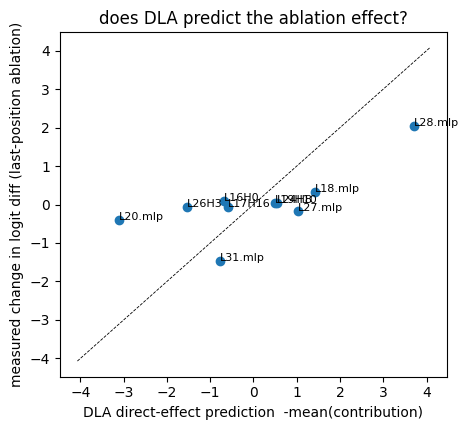

correlation of predicted vs measured: 0.721


In [31]:
try:
    if RUN_STEP4:
        # STEP 4d. results: accuracy, yes-rate, hallucination (false yes) and miss (false no) rates vs baseline, matched random controls
        import pandas as pd
        from scipy import stats
        import matplotlib.pyplot as plt
        gt = np.array([r["gt"] for r in EVAL]); isno, isyes = gt == "no", gt == "yes"
        base_pred = LD[:, 0] > 0; base_ok = base_pred == (gt == "yes")
        rows = []
        for j, cf in enumerate(CONFIGS):
            pred = LD[:, j] > 0; ok = pred == (gt == "yes")
            b, c = int((base_ok & ~ok).sum()), int((~base_ok & ok).sum())
            rows.append(dict(label=cf["label"], group=cf["group"], k=cf.get("k", 0), scale=cf["scale"], auroc=auroc(LD[:, j], gt == "yes"), acc=ok.mean(), yes_rate=pred.mean(),
                             halluc=(pred & isno).sum() / isno.sum(), miss=(~pred & isyes).sum() / isyes.sum(), mean_ld=LD[:, j].mean(),
                             d_acc=ok.mean() - base_ok.mean(), d_halluc=(pred & isno).sum() / isno.sum() - (base_pred & isno).sum() / isno.sum(),
                             d_miss=(~pred & isyes).sum() / isyes.sum() - (~base_pred & isyes).sum() / isyes.sum(),
                             mcnemar_p=stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0))
        RES = pd.DataFrame(rows); RES.to_csv(f"{DLA_DIR}/ablation_table.csv", index=False)
        pd.set_option("display.width", 200)
        print("baseline:", RES[["acc", "yes_rate", "halluc", "miss", "mean_ld"]].iloc[0].astype(float).round(3).to_dict())
        print("\nSINGLE COMPONENTS (auroc is threshold-free: a pure bias shift changes acc / halluc / miss but not auroc)"); print(RES[RES.group == "single"][["label", "auroc", "acc", "yes_rate", "halluc", "miss", "mean_ld", "d_acc", "d_halluc", "d_miss", "mcnemar_p"]].round(3).to_string(index=False))
        for gname in ["hallucination-pathway", "grounding-pathway"]:
            real = RES[RES.group == gname]
            if not len(real): continue
            print(f"\n{gname.upper()} GROUPS vs matched random sets"); print(real[["label", "auroc", "acc", "halluc", "miss", "d_acc", "d_halluc", "d_miss", "mcnemar_p"]].round(3).to_string(index=False))
            rnd = RES[RES.group == f"random-{gname}"].groupby(["k", "scale"])[["d_acc", "d_halluc", "d_miss"]].agg(["mean", "std"]).round(3)
            print("random matched sets (mean, std over seeds):"); print(rnd.to_string())

        # DLA direct-effect prediction vs measured change, singles at scale 0
        sg = [(nm, q) for q, nm in enumerate(SINGLES)]
        meas, pred_ = [], []
        for nm, q in sg:
            j = [k for k, c in enumerate(CONFIGS) if c["group"] == "single" and c["names"] == [nm] and c["scale"] == 0.0]
            if j: meas.append((LD[:, j[0]] - LD[:, 0]).mean()); pred_.append(-PRED_DIRECT[:, q].mean())
        if meas:
            plt.figure(figsize=(4.8, 4.4)); plt.scatter(pred_, meas)
            for (nm, _), x, y in zip(sg, pred_, meas): plt.annotate(nm, (x, y), fontsize=8)
            lim = max(np.abs(pred_ + meas)) * 1.1; plt.plot([-lim, lim], [-lim, lim], "k--", lw=0.6); plt.xlabel("DLA direct-effect prediction  -mean(contribution)"); plt.ylabel("measured change in logit diff (last-position ablation)")
            plt.title("does DLA predict the ablation effect?"); plt.tight_layout(); plt.savefig(f"{DLA_DIR}/ablation_dla_vs_measured.png"); plt.show()
            print("correlation of predicted vs measured:", np.corrcoef(pred_, meas)[0, 1].round(3))
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


## Step 4: last-position ablations (noise control run, 1000 balanced POPE questions, 69 configs)

**Setup.** Each config zeroes (×0.0) or halves (×0.5) the last-position output of one component or a group, and the Yes − No logit difference $\Delta$ is recomputed. Baseline: accuracy 0.723, yes-rate 0.407, false-yes rate 0.184 (halluc), miss rate 0.370, mean $\Delta = -0.126$. AUROC is the threshold-free measure: a pure bias shift changes accuracy, false-yes and miss, but not AUROC.

**Headline.** Ablating one component at the last position moves the answer threshold but barely changes how well the model separates present from absent objects.

### 1. Single ablations change calibration, not discrimination

AUROC stays at 0.809–0.821 for every single-component ablation, while the yes-rate swings between 0.09 and 1.0.

| Config | Accuracy | Yes-rate | Mean $\Delta$ | AUROC |
|---|---|---|---|---|
| L28.mlp ×0 | 0.500 | 1.000 | +1.911 | 0.809 |
| L31.mlp ×0 | 0.584 | 0.088 | −1.606 | 0.815 |
| L20.mlp ×0 | 0.666 | 0.206 | −0.520 | 0.816 |
| L18.mlp ×0 | 0.709 | 0.637 | +0.198 | 0.811 |
| L26H3 ×0 | 0.719 | 0.361 | −0.183 | 0.821 |

Zeroing L28.mlp makes the model answer "yes" to everything, and AUROC is still 0.809. These components set where the threshold sits. The evidence that separates present from absent is not in any single last-position component.

### 2. DLA direct effect predicts the ablation effect poorly

The correlation between the DLA prediction $-\overline{\text{contribution}}$ and the measured change in $\Delta$ is 0.721, but it is carried by two points (L28.mlp and L20.mlp) and $n=10$. Predicted values are read off the scatter plot, so they are approximate. Measured values are the table's mean $\Delta$ minus the baseline of $-0.126$.

| Component | DLA predicts | Measured | Note |
|---|---|---|---|
| L26H3 | −1.55 | −0.06 | almost fully compensated downstream |
| L20.mlp | −3.1 | −0.39 | about 87% compensated |
| L28.mlp | +3.7 | +2.04 | about 45% compensated |
| L18.mlp | +1.4 | +0.32 | |
| L27.mlp | +1.0 | −0.16 | sign flips |
| L31.mlp | −0.8 | −1.48 | larger than predicted |

- L31.mlp is the last layer, so there is no downstream compensation. The extra effect is probably the final layer-norm denominator changing when its output is zeroed. This is a guess and has not been checked.
- The L27.mlp sign flip fits a chain in which its output feeds L28.mlp.

### 3. Group ablations behave the same way

| Group | Accuracy | False-yes | Miss | AUROC |
|---|---|---|---|---|
| baseline | 0.723 | 0.184 | 0.370 | about 0.82 (see note) |
| hallucination-pathway top 3, ×0 | 0.543 | 0.002 | 0.912 | 0.819 |
| hallucination-pathway top 5, ×0 | 0.518 | 0.002 | 0.962 | 0.815 |
| hallucination-pathway top 10, ×0 | 0.500 | 0.000 | 1.000 | 0.796 |
| grounding-pathway top 3, ×0 | 0.500 | 1.000 | 0.000 | 0.811 |
| grounding-pathway top 5, ×0 | 0.500 | 1.000 | 0.000 | 0.765 |
| grounding-pathway top 10, ×0 | 0.500 | 1.000 | 0.000 | 0.722 |

- The hallucination-pathway top 3 cuts false-yes from 0.184 to 0.002, but misses rise from 0.37 to 0.91 and accuracy drops from 0.72 to 0.54. It is a bias shift, not a selective fix. AUROC does not move.
- The grounding groups push everything to "yes", so accuracy, false-yes and miss are saturated and uninformative. Only AUROC tells you anything there.
- Baseline AUROC is not printed in the table (the baseline row is shown only by its accuracy and rates). The single-ablation values suggest about 0.82.

### 4. Where AUROC does drop

Only the grounding top 5 at ×0 (0.765) and top 10 at ×0 (0.722), where several components are removed at once. At ×0.5 it stays at about 0.81. So the image evidence is spread across many components.

The random matched sets have large variance, because some draws hit L28.mlp (for example, $k=5$, ×0: $\Delta$false-yes $=+0.465 \pm 0.333$). Their AUROC is not printed. Check `ablation_table.csv` before calling the 0.72 meaningful.

### Caveats

- Zero-ablation removes each component's constant offset too, which is most of what moves here. Step 6 (mean-ablation, with AUROC and bootstrap CIs) separates the offset from the evidence and tests whether the evidence MLPs are needed.
- AUROC at $n=1000$ has a standard error of about 0.015, so differences within 0.809–0.821 are within noise.
- Last-position ablation only removes a component's output at the final token. It does not touch how that component's earlier-position outputs reach the last position through attention, which is what step 7's K/V patching addresses.

## Step 5: attribution patching (last position, clean activation vs corrupted activation)

Estimates, for every head and MLP, **how much the Yes-No logit would change if that component's output at the final token were replaced by its value from the corrupted run** (`CONTROL_MODE`), using one gradient instead of 1056 patching runs:

`AtP(c) = (a_clean - a_corrupt) . d(logit diff)/d a  evaluated on the clean run`

Positive = the component's clean activation raises Yes-No relative to the corrupted one. This is a first-order approximation of activation patching (corrupted -> clean run). Unlike DLA it includes **indirect** effects (the component changing later layers at the last position). It does not include effects routed through other token positions, the same scope as the step 4 ablations.

* 5a: hooks (record / leaf-with-gradient / patch) + the function that does one question.
* 5b: **validation**: for a few questions, exactly patch the top components and compare with the gradient prediction. Check this before trusting 5d.
* 5c: loop over `N_AP` balanced questions. 5d: results (per outcome group, vs the direct-only clean-minus-corrupted DLA).

In [33]:
# STEP 5a. ATTRIBUTION PATCHING MACHINERY (requires STEP 4a: prefix_cache, last_token, clear_abl)
AP = {"mode": "off", "leaf_a": {}, "leaf_m": {}, "rec_a": {}, "rec_m": {}, "pa": {}, "pm": set()}
def _ap_pre(l):
    def hook(module, args):
        m = AP["mode"]
        if m == "off": return None
        x = args[0]
        if m == "record": AP["rec_a"][l] = x[0, -1].detach().clone(); return None
        if m == "leaf":
            xl = x.detach().clone().requires_grad_(True); AP["leaf_a"][l] = xl; return (xl,) + tuple(args[1:])
        if m == "patch" and l in AP["pa"]:
            xn = x.clone(); xv = xn.view(*xn.shape[:-1], n_head, head_dim); hs = AP["pa"][l]
            xv[..., hs, :] = AP["rec_a"][l].view(n_head, head_dim)[hs].to(xn.dtype)
            return (xn,) + tuple(args[1:])
        return None
    return hook
def _ap_mlp(l):
    def hook(module, args, output):
        m = AP["mode"]
        if m == "off": return None
        o = output[0] if isinstance(output, tuple) else output
        if m == "record": AP["rec_m"][l] = o[0, -1].detach().clone(); return None
        if m == "leaf":
            ol = o.detach().clone().requires_grad_(True); AP["leaf_m"][l] = ol; return ol
        if m == "patch" and l in AP["pm"]:
            on = o.clone(); on[0, -1] = AP["rec_m"][l].to(on.dtype); return on
        return None
    return hook
_ap_handles = []
for l, layer in enumerate(layers):
    _ap_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_ap_pre(l)))
    _ap_handles.append(layer.mlp.register_forward_hook(_ap_mlp(l)))

def _dla_now():
    rms = float(_dla_cache["rms"])
    return (torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]).numpy() / rms,
            torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]).numpy() / rms)

def ap_one(r):
    """clean and corrupted last-token runs for one question; returns the attribution-patching estimate for every head and MLP."""
    feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"])
    proj_c, _ = corrupted_proj(r); emb_c, _ = build_embeds(proj_c, r["question_text"])
    clear_abl()
    AP.update(mode="record", rec_a={}, rec_m={})
    ld_c = last_token(emb_c, prefix_cache(emb_c)); AP["mode"] = "off"
    dla_a_c, dla_m_c = _dla_now()                                   # direct contributions in the corrupted run
    ld_0 = last_token(emb, prefix_cache(emb)); dla_a_0, dla_m_0 = _dla_now()
    pc = prefix_cache(emb)
    AP.update(mode="leaf", leaf_a={}, leaf_m={})
    with torch.enable_grad():
        out = llm(inputs_embeds=emb[:, -1:], past_key_values=pc, use_cache=True, logits_to_keep=1)
        lg = out.logits[0, -1].float(); (lg[YES_ID] - lg[NO_ID]).backward()
    AP["mode"] = "off"
    ga = torch.stack([AP["leaf_a"][l].grad[0, -1].float().cpu() for l in range(n_layer)])
    aa = torch.stack([AP["leaf_a"][l].detach()[0, -1].float().cpu() for l in range(n_layer)])
    ac = torch.stack([AP["rec_a"][l].float().cpu() for l in range(n_layer)])
    gm = torch.stack([AP["leaf_m"][l].grad[0, -1].float().cpu() for l in range(n_layer)])
    am = torch.stack([AP["leaf_m"][l].detach()[0, -1].float().cpu() for l in range(n_layer)])
    mc = torch.stack([AP["rec_m"][l].float().cpu() for l in range(n_layer)])
    return dict(atp_a=(ga * (aa - ac)).view(n_layer, n_head, head_dim).sum(-1).numpy(), atp_m=(gm * (am - mc)).sum(-1).numpy(),
                ld_clean=ld_0, ld_corr=ld_c, dla_a=dla_a_0 - dla_a_c, dla_m=dla_m_0 - dla_m_c, emb=emb)

def patch_exact(emb, names):
    """exact patching: replace the clean output of the named components (last position) by the recorded corrupted ones."""
    pa, pm = {}, set()
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": pa.setdefault(l, []).append(h)
        else: pm.add(l)
    AP.update(mode="patch", pa=pa, pm=pm)
    v = last_token(emb, prefix_cache(emb)); AP["mode"] = "off"; return v

In [34]:
try:
    import pandas as pd
    # STEP 5b. VALIDATION: gradient estimate vs exact patching on a few questions (do this before trusting 5d)
    vr = random.Random(SEED + 7); val_q = vr.sample(recs, 4); pred_v, act_v = [], []
    for r in val_q:
        o = ap_one(r)
        comp = [(f"L{l}H{h}", o["atp_a"][l, h]) for l in range(n_layer) for h in range(n_head)] + [(f"L{l}.mlp", o["atp_m"][l]) for l in range(n_layer)]
        top = sorted(comp, key=lambda t: -abs(t[1]))[:8]; rnd = vr.sample(comp, 4)
        for nm, a in top + rnd:
            actual = patch_exact(o["emb"], [nm]) - o["ld_clean"]
            pred_v.append(-a); act_v.append(actual)
        print(f"{r['question_id']}: clean {o['ld_clean']:+.3f} corrupted {o['ld_corr']:+.3f}")
    pred_v, act_v = np.array(pred_v), np.array(act_v)
    big = np.abs(act_v) > 0.05
    print(f"{len(pred_v)} single-component patches | corr(predicted, exact) = {np.corrcoef(pred_v, act_v)[0, 1]:.3f} "
          f"| on the {int(big.sum())} with |exact change| > 0.05: {np.corrcoef(pred_v[big], act_v[big])[0, 1] if big.sum() > 2 else float('nan'):.3f}")
    print("predicted vs exact change of the Yes-No logit when the component is patched clean -> corrupted:")
    print(pd.DataFrame(dict(predicted=pred_v[:12], exact=act_v[:12])).round(3).T.to_string())
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


pope_1326: clean +0.188 corrupted +0.609
pope_617: clean -0.703 corrupted +0.633
pope_1617: clean -1.109 corrupted +0.984
pope_2666: clean +0.062 corrupted +0.219
48 single-component patches | corr(predicted, exact) = 0.713 | on the 35 with |exact change| > 0.05: 0.718
predicted vs exact change of the Yes-No logit when the component is patched clean -> corrupted:
             0      1      2      3      4      5      6      7      8      9      10     11
predicted -2.78  2.220 -1.156  0.857  0.807  0.794 -0.663 -0.612  0.000 -0.000 -0.001 -0.039
exact     -0.25  1.391 -0.141  0.172 -0.203  0.219 -0.859 -0.281  0.062  0.031  0.078  0.062


It passes, narrowly. The correlation is 0.713, just above the 0.7 line I set, and 0.718 on the 35 patches with a non-trivial effect. So run 5c and 5d, but read the results as rankings, not magnitudes.

**What the predicted-versus-exact pairs show**
- **Direction is mostly right.** Ten of the twelve printed pairs agree in sign. Position 4 is the clear miss (predicted +0.81, exact −0.20), and position 8 is a tiny effect on both sides.
- **Magnitudes are inflated for the big ones.** The first component is predicted −2.78 and the exact value is −0.25, about 11×. Position 2 is −1.16 against −0.14, about 8×. Position 1 is 2.22 against 1.39, about 1.6×.
- **Same story as 4d.** The first-order estimate misses the same downstream compensation that DLA missed. Here the corruption is large, with $\Delta$ moving by 1 to 2 logits (for example −1.11 to +0.98), so a linear approximation around the clean run is rough.

**How to use step 5**
- Trust the *order* and sign of the top components in 5d, and the within-run comparison with DLA. Don't quote the effect sizes. Expect them to be inflated by roughly 2–10×.
- The exact numbers are in step 7, which patches activations directly and has no linear approximation. Step 7 and the exact-patching checks are the ones to cite in the report.
- Exact single-component effects are small relative to the full clean-to-corrupted change (the largest here is −0.86). So no single component accounts for much, which fits the 4d finding that the evidence is spread out.

Go on to 5c now (about 20–30 min). Paste the 5d output when it's done.

In [35]:
import shutil
shutil.copy("/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise/ckpt_step4.npz", f"{DLA_DIR}/ckpt_step4.npz")
push("step 4 results: ablation table, scatter, results npz")

[push] OK (step 4 results: ablation table, scatter, results npz): B/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.13MB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.17MB/s]


In [37]:
try:
    # STEP 5c. ATTRIBUTION PATCHING LOOP (balanced yes/no sample)
    import time
    if RUN_STEP5:
        rs = random.Random(SEED + 11)
        qy = [r for r in recs if r["gt"] == "yes"]; qn = [r for r in recs if r["gt"] == "no"]
        AP_Q = rs.sample(qy, min(N_AP // 2, len(qy))) + rs.sample(qn, min(N_AP // 2, len(qn))); rs.shuffle(AP_Q)
        OUT5 = dict(atp_a=[], atp_m=[], dla_a=[], dla_m=[], ld_clean=[], ld_corr=[])
        K5 = _ckpt_key([CONTROL_MODE], [r["question_id"] for r in AP_Q]); start5 = 0; _p5 = f"{DLA_DIR}/ckpt_step5.npz"
        if os.path.exists(_p5):
            try:
                _z = np.load(_p5, allow_pickle=False)
                if str(_z["key"]) == K5:
                    OUT5 = {k: list(_z[k]) for k in OUT5}; start5 = int(_z["done"]); print(f"[step5] resuming from row {start5}")
            except Exception as ex: print("[step5] checkpoint unreadable:", ex)
        print(f"[step5] {len(AP_Q)} questions, starting at row {start5}", flush=True)
        t0 = time.time(); n_bad5 = 0
        for i, r in enumerate(AP_Q):
            if i < start5: continue
            o = ap_one(r)
            for k in OUT5: OUT5[k].append(o[k])
            if not all(np.isfinite(np.asarray(o[k], dtype=float)).all() for k in OUT5): n_bad5 += 1
            n_done = i + 1 - start5
            if n_done % 10 == 0 or i + 1 == len(AP_Q):
                el = time.time() - t0
                ldc = np.array(OUT5["ld_clean"][-50:], dtype=float); ldk = np.array(OUT5["ld_corr"][-50:], dtype=float)
                print(f"[{i + 1}/{len(AP_Q)}] {el / 60:.1f} min elapsed | {el / n_done:.1f} s/q | ETA {el / n_done * (len(AP_Q) - i - 1) / 60:.1f} min | "
                      f"last-50 mean logit diff: clean {ldc.mean():+.2f}, corrupted {ldk.mean():+.2f} | non-finite {n_bad5}", flush=True)
            if (i + 1) % 25 == 0: ckpt_save("step5", K5, i + 1, {k: np.array(v) for k, v in OUT5.items()})
        A5 = {k: np.array(v) for k, v in OUT5.items()}
        np.savez(f"{DLA_DIR}/atp_results.npz", **A5, qids=np.array([r["question_id"] for r in AP_Q]), gt=np.array([r["gt"] for r in AP_Q]), control=CONTROL_MODE)
        print("saved", f"{DLA_DIR}/atp_results.npz", f"| {(time.time() - t0) / 60:.1f} min"); push("attribution patching")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise

[step5] 600 questions, starting at row 0
[10/600] 0.6 min elapsed | 3.7 s/q | ETA 36.4 min | last-50 mean logit diff: clean +0.03, corrupted +0.51 | non-finite 0
[20/600] 1.3 min elapsed | 3.8 s/q | ETA 36.9 min | last-50 mean logit diff: clean -0.00, corrupted +0.38 | non-finite 0
[30/600] 1.9 min elapsed | 3.9 s/q | ETA 37.0 min | last-50 mean logit diff: clean -0.07, corrupted +0.35 | non-finite 0
[40/600] 2.6 min elapsed | 3.9 s/q | ETA 36.5 min | last-50 mean logit diff: clean -0.01, corrupted +0.31 | non-finite 0
[50/600] 3.3 min elapsed | 3.9 s/q | ETA 36.0 min | last-50 mean logit diff: clean -0.01, corrupted +0.26 | non-finite 0
[60/600] 3.9 min elapsed | 3.9 s/q | ETA 35.4 min | last-50 mean logit diff: clean +0.02, corrupted +0.18 | non-finite 0
[70/600] 4.6 min elapsed | 3.9 s/q | ETA 34.9 min | last-50 mean logit diff: clean -0.01, corrupted +0.20 | non-finite 0
[80/600] 5.3 min elapsed | 4.0 s/q | ETA 34.3 min | last-50 mean logit diff: clean -0.00, corrupted +0.17 | non-

Good. Run 5d next, then paste me the output and the plots. I’ll read it against what we already know.

What I’ll check:

Ranking vs DLA: whether attribution patching gives the same top components as the direct-effect DLA, or a different order.
TN-vs-FP tests: whether the attribution-patching scores differ between correct-no and false-yes questions, and which components carry it.
Sign agreement: given the 5b result (0.713, mostly right on sign but inflated in size), I’ll weight the order of components and ignore the effect sizes.

After 5d, go straight on to 6a. If the 5c log showed any non-finite count above 0, tell me. It should have been 0 on every progress line.

600 questions | outcomes {np.str_('TP'): 176, np.str_('TN'): 240, np.str_('FN'): 124, np.str_('FP'): 60} | control = noise
mean clean Yes-No -0.156 | mean corrupted +0.185 | mean (clean - corrupted) -0.342
sum over components, mean: attribution patching +0.159 (signed) | direct-only clean-minus-corrupted +0.289 (signed) | true signed (clean - corrupted) +0.289  (heads + MLPs at the last position only)

TOP COMPONENTS BY |attribution patching| (mean over all questions, signed towards the correct answer)
   name    atp  direct  indirect
L18.mlp  0.176   0.180    -0.004
L23.mlp  0.097   0.097     0.001
L20.mlp  0.094   0.093     0.001
L31.mlp -0.071   0.011    -0.083
L27.mlp -0.067  -0.057    -0.010
L28.mlp -0.066  -0.037    -0.029
L21.mlp -0.052  -0.054     0.001
L24.mlp -0.039  -0.039    -0.000
L16.mlp  0.035   0.036    -0.001
L30.mlp -0.024  -0.011    -0.013
  L16H0  0.020   0.014     0.006
L17.mlp  0.017   0.019    -0.002
 L23H10 -0.017  -0.017    -0.000
 L16H18  0.012   0.012     0.0

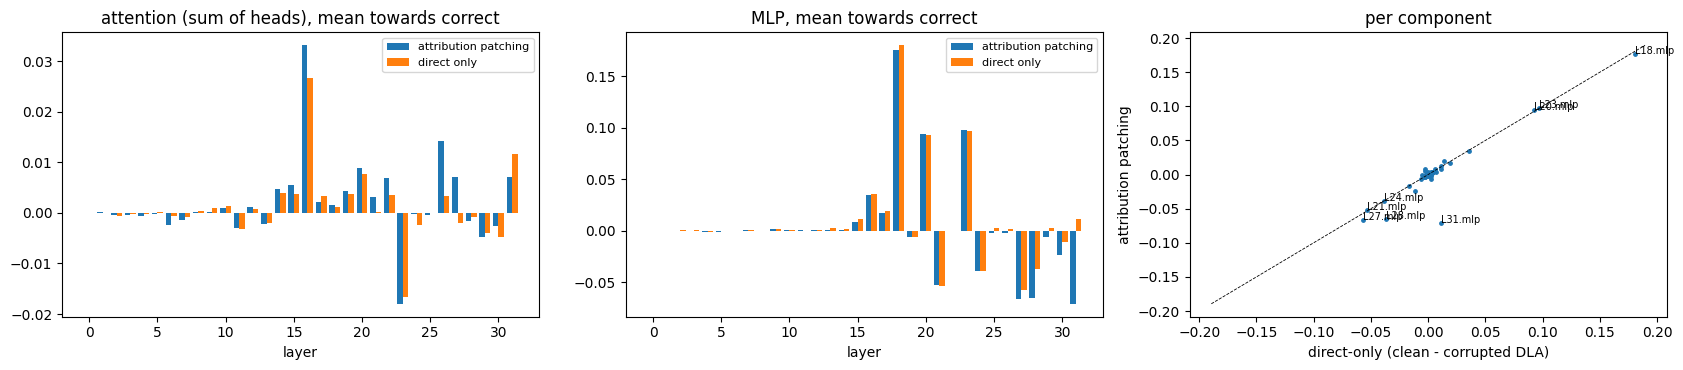

In [38]:
try:
    # STEP 5d. RESULTS: attribution patching vs direct-only (DLA) clean-minus-corrupted, by outcome group
    import pandas as pd
    from scipy import stats
    import matplotlib.pyplot as plt
    if RUN_STEP5:
        gt5 = np.array([r["gt"] for r in AP_Q]); sgn = np.where(gt5 == "yes", 1.0, -1.0)[:, None]
        pred5 = np.where(A5["ld_clean"] > 0, "yes", "no"); outc = np.where((gt5 == "yes") & (pred5 == "yes"), "TP", np.where((gt5 == "no") & (pred5 == "no"), "TN", np.where(pred5 == "yes", "FP", "FN")))
        N5 = len(AP_Q); atp = np.concatenate([A5["atp_a"].reshape(N5, -1), A5["atp_m"]], 1) * sgn      # signed: positive = towards the correct answer
        dd = np.concatenate([A5["dla_a"].reshape(N5, -1), A5["dla_m"]], 1) * sgn
        names5 = [f"L{l}H{h}" for l in range(n_layer) for h in range(n_head)] + [f"L{l}.mlp" for l in range(n_layer)]
        print(f"{N5} questions | outcomes {dict(Counter(outc))} | control = {CONTROL_MODE}")
        print(f"mean clean Yes-No {A5['ld_clean'].mean():+.3f} | mean corrupted {A5['ld_corr'].mean():+.3f} | mean (clean - corrupted) {np.mean(A5['ld_clean'] - A5['ld_corr']):+.3f}")
        print(f"sum over components, mean: attribution patching {atp.sum(1).mean() * 1:+.3f} (signed) | direct-only clean-minus-corrupted {dd.sum(1).mean():+.3f} (signed)"
              f" | true signed (clean - corrupted) {np.mean((A5['ld_clean'] - A5['ld_corr']) * sgn[:, 0]):+.3f}  (heads + MLPs at the last position only)")
        T = pd.DataFrame(dict(name=names5, atp=atp.mean(0), direct=dd.mean(0))); T["indirect"] = T.atp - T.direct
        print("\nTOP COMPONENTS BY |attribution patching| (mean over all questions, signed towards the correct answer)")
        print(T.reindex(T.atp.abs().sort_values(ascending=False).index).head(15).round(3).to_string(index=False))
        print("\nLARGEST INDIRECT PARTS (attribution patching minus direct-only)")
        print(T.reindex(T.indirect.abs().sort_values(ascending=False).index).head(10).round(3).to_string(index=False))

        def bh5(p):
            n = len(p); o = np.argsort(p); q = p[o] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(q, 1.0); return out
        for nm, gA, gB in [("absent: TN vs FP", "TN", "FP"), ("present: TP vs FN", "TP", "FN")]:
            a, b = atp[outc == gA], atp[outc == gB]
            if len(a) < 5 or len(b) < 5: print(nm, "too few samples"); continue
            t, p = stats.ttest_ind(a, b, equal_var=False); p = np.nan_to_num(p, nan=1.0)
            sp = np.sqrt(((len(a) - 1) * a.var(0, ddof=1) + (len(b) - 1) * b.var(0, ddof=1)) / (len(a) + len(b) - 2)); d = np.where(sp > 0, (a.mean(0) - b.mean(0)) / np.where(sp > 0, sp, 1), 0)
            sig = (bh5(p) < 0.05) & (np.abs(d) > 0.3)
            print(f"\n{nm} on attribution-patching scores: n={len(a)} vs {len(b)} | significant {int(sig.sum())}")
            o_ = np.argsort(-np.abs(d))[:10]
            print(pd.DataFrame(dict(name=np.array(names5)[o_], mean_A=a.mean(0)[o_], mean_B=b.mean(0)[o_], d=d[o_], sig=sig[o_])).round(3).to_string(index=False))

        La = lambda v: v[:n_layer * n_head].reshape(n_layer, n_head).sum(1)
        fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
        ax[0].bar(np.arange(n_layer) - 0.2, La(T.atp.values), 0.4, label="attribution patching"); ax[0].bar(np.arange(n_layer) + 0.2, La(T.direct.values), 0.4, label="direct only")
        ax[0].set_title("attention (sum of heads), mean towards correct"); ax[0].set_xlabel("layer"); ax[0].legend(fontsize=8)
        ax[1].bar(np.arange(n_layer) - 0.2, T.atp.values[n_layer * n_head:], 0.4, label="attribution patching"); ax[1].bar(np.arange(n_layer) + 0.2, T.direct.values[n_layer * n_head:], 0.4, label="direct only")
        ax[1].set_title("MLP, mean towards correct"); ax[1].set_xlabel("layer"); ax[1].legend(fontsize=8)
        ax[2].scatter(T.direct, T.atp, s=6); lim = max(T.atp.abs().max(), T.direct.abs().max()) * 1.05; ax[2].plot([-lim, lim], [-lim, lim], "k--", lw=0.6)
        for _, rw in T.reindex(T.atp.abs().sort_values(ascending=False).index).head(8).iterrows(): ax[2].annotate(rw["name"], (rw["direct"], rw["atp"]), fontsize=7)
        ax[2].set_xlabel("direct-only (clean - corrupted DLA)"); ax[2].set_ylabel("attribution patching"); ax[2].set_title("per component")
        plt.tight_layout(); plt.savefig(f"{DLA_DIR}/atp_vs_direct.png"); plt.show()
        T.to_csv(f"{DLA_DIR}/atp_components.csv", index=False)
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


## Step 5: attribution patching (noise control, $0.5\sigma$, 600 balanced questions)

### What was measured

For each question we patch one component's last-position output from the noisy run into the clean run, and estimate the change in $\Delta = \text{logit(Yes)} - \text{logit(No)}$ with a first-order (gradient) approximation. Scores are signed so that positive means "pushes toward the correct answer". The estimate is compared with the direct-only DLA contribution (clean minus corrupted) of the same component. The *indirect* part is the attribution-patching estimate minus the direct-only part.

**Sample.** 600 questions (300 yes, 300 no). Outcomes: TP 176, TN 240, FN 124, FP 60. Accuracy $=416/600=0.693$, yes-rate $=0.393$, close to the full 3000-question run (0.728, 0.408).

### 5b validation (before running 5c)

48 single-component patches on 4 questions: corr(predicted, exact) $=0.713$, and $0.718$ on the 35 patches with $|\text{exact change}|>0.05$. Sample of predicted versus exact change in $\Delta$:

| | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| predicted | −2.78 | 2.22 | −1.16 | 0.86 | 0.81 | 0.79 | −0.66 | −0.61 | 0.00 | −0.00 | −0.00 | −0.04 |
| exact | −0.25 | 1.39 | −0.14 | 0.17 | −0.20 | 0.22 | −0.86 | −0.28 | 0.06 | 0.03 | 0.08 | 0.06 |

Sign agrees in 10 of the 12 printed pairs, but magnitudes are inflated, in some cases several times (e.g. −2.78 versus −0.25). The estimate is usable for ranking and sign, not for effect sizes. Exact patching numbers come from step 7.

### 5d headline numbers

| Quantity | Value |
|---|---|
| Mean clean $\Delta$ | −0.156 |
| Mean corrupted $\Delta$ | +0.185 |
| Mean (clean − corrupted) $\Delta$, raw | −0.342 |
| Sum over components, attribution patching (signed) | +0.159 |
| Sum over components, direct-only clean − corrupted (signed) | +0.289 |
| True signed (clean − corrupted), heads + MLPs at last position | +0.289 |

The direct-only sum equals the true difference by construction (the decomposition is exact). The attribution-patching total is 55% of it. The missing $-0.13$ is the total indirect part.

**Top components by $|\text{attribution patching}|$** (mean over all questions, signed toward correct):

| Component | AtP | Direct | Indirect |
|---|---|---|---|
| L18.mlp | 0.176 | 0.180 | −0.004 |
| L23.mlp | 0.097 | 0.097 | 0.001 |
| L20.mlp | 0.094 | 0.093 | 0.001 |
| L31.mlp | −0.071 | 0.011 | −0.083 |
| L27.mlp | −0.067 | −0.057 | −0.010 |
| L28.mlp | −0.066 | −0.037 | −0.029 |
| L21.mlp | −0.052 | −0.054 | 0.001 |
| L24.mlp | −0.039 | −0.039 | −0.000 |
| L16.mlp | 0.035 | 0.036 | −0.001 |
| L30.mlp | −0.024 | −0.011 | −0.013 |
| L16H0 | 0.020 | 0.014 | 0.006 |
| L17.mlp | 0.017 | 0.019 | −0.002 |
| L23H10 | −0.017 | −0.017 | −0.000 |
| L16H18 | 0.012 | 0.012 | 0.000 |
| L15.mlp | 0.009 | 0.011 | −0.002 |

**Largest indirect parts** (AtP minus direct):

| Component | AtP | Direct | Indirect |
|---|---|---|---|
| L31.mlp | −0.071 | 0.011 | −0.083 |
| L28.mlp | −0.066 | −0.037 | −0.029 |
| L30.mlp | −0.024 | −0.011 | −0.013 |
| L26H3 | 0.008 | −0.003 | 0.010 |
| L27.mlp | −0.067 | −0.057 | −0.010 |
| L29.mlp | −0.006 | 0.002 | −0.008 |
| L27H7 | 0.005 | −0.003 | 0.008 |
| L16H0 | 0.020 | 0.014 | 0.006 |
| L25.mlp | −0.002 | 0.003 | −0.005 |
| L30H7 | −0.001 | −0.005 | 0.005 |

**Layer-level plots** (attention summed over heads, and MLP, per layer): attention peaks at L16 (AtP +0.033, direct +0.027), is negative at L23 (−0.018), positive at L26 (AtP +0.014, direct +0.0035) and at L31 (AtP +0.007, direct +0.0115). MLP bars are an order of magnitude larger (L18 +0.176 versus the largest attention layer +0.033). On the per-component scatter, almost everything lies on the diagonal. The exceptions are L31.mlp (−0.07 versus +0.01), L28.mlp and L27.mlp.

**TN vs FP** on attribution-patching scores (absent-object questions, $n=240$ versus 60; 132 components significant):

| Component | TN mean | FP mean | $d$ |
|---|---|---|---|
| L22H3 | 0.003 | −0.006 | 2.033 |
| L16H18 | 0.093 | 0.056 | 1.759 |
| L1H14 | −0.000 | −0.000 | 1.679 |
| L18.mlp | 1.132 | 0.669 | 1.538 |
| L24.mlp | −0.223 | −0.126 | −1.437 |
| L16.mlp | 0.285 | 0.185 | 1.428 |
| L31.mlp | −0.768 | −0.533 | −1.326 |
| L23.mlp | −0.127 | −0.357 | 1.262 |
| L26H19 | 0.019 | 0.025 | −1.210 |
| L0H1 | 0.000 | 0.000 | −1.171 |

**TP vs FN** (present-object questions, $n=176$ versus 124; 142 components significant):

| Component | TP mean | FN mean | $d$ |
|---|---|---|---|
| L22H3 | 0.009 | 0.001 | 2.011 |
| L16H18 | −0.049 | −0.080 | 1.820 |
| L1H14 | 0.000 | 0.000 | 1.757 |
| L18.mlp | −0.509 | −0.941 | 1.507 |
| L16.mlp | −0.158 | −0.247 | 1.499 |
| L23.mlp | 0.456 | 0.243 | 1.321 |
| L31.mlp | 0.483 | 0.715 | −1.301 |
| L24.mlp | 0.095 | 0.169 | −1.074 |
| L0H15 | −0.000 | −0.000 | −1.040 |
| L18H30 | 0.026 | 0.018 | 1.016 |

### Findings

**1. The image evidence at the last token is written mostly by mid-layer MLPs, and opposed by late MLPs.**
- Evidence MLPs: L18 (+0.176), L23 (+0.097), L20 (+0.094), L16 (+0.035), L17 (+0.017). The top three make up about 86% of the positive MLP total.
- Opposing MLPs: L31 (−0.071), L27 (−0.067), L28 (−0.066), L21 (−0.052), L24 (−0.039), L30 (−0.024).
- Listed positive MLPs sum to $+0.43$ and listed negative ones to $-0.32$, so about **75% of the evidence is cancelled**.
- Attention matters less: the largest layer is L16 (+0.033 summed), and L23 is negative.

**2. Direct DLA and the first-order total agree for most components.** The indirect part is under 0.01 for L18, L20, L23. This contrasts with the 4d zero-ablations, where compensation was large. A small clean-versus-noisy difference is a mild perturbation. Zeroing a component is a large one.

**3. Late MLPs have large negative indirect effects, late heads positive ones.** The total indirect part is $-0.13$. The late MLPs account for most of it (L31 −0.083, L28 −0.029, L30 −0.013, L27 −0.010). L31 is the last layer, so its indirect part can't pass through later components. It most likely comes through the final-norm scale, a guess consistent with the data but not directly tested. Several late heads are positive (L26H3 +0.010, L27H7 +0.008, L16H0 +0.006, L30H7 +0.005).

**4. A component's mean signed score is half the absent-versus-present gap.** On a balanced sample, the class-independent part of the effect cancels. The class means are recovered from the TN/FP/TP/FN table (weights $240, 60, 176, 124$):

| Component | Signed, absent | Signed, present | Truth part (mean) | Constant (raw, + = toward yes) |
|---|---|---|---|---|
| L18.mlp | +1.04 | −0.69 | +0.176 | −0.86 |
| L16.mlp | +0.27 | −0.20 | +0.035 | −0.23 |
| L23.mlp | −0.17 | +0.37 | +0.097 | +0.27 |
| L24.mlp | −0.20 | +0.13 | −0.039 | +0.17 |
| L31.mlp | −0.72 | +0.58 | −0.071 | +0.65 |
| L16H18 | +0.09 | −0.06 | +0.012 | −0.07 |

The reproduced truth parts match the 5d top table. The constants are 3–6× larger than the truth parts and largely oppose each other (L18 toward No, L31 toward Yes).

**5. This explains 4d.** Zeroing L18.mlp should push toward yes, and it did (yes-rate 0.41 to 0.64). Zeroing L31.mlp should push toward no, and it did (0.09). Removing a big constant ruins calibration, but the small truth modulation riding on it is mostly intact, so AUROC barely moves (0.811 and 0.815).

**6. Two kinds of evidence component (interpretation from the signs, not tested).** Absence-leaning: L18.mlp, L16.mlp, L16H18 push toward No and push harder when the object is absent. Presence-leaning: L23.mlp pushes toward Yes and harder when present. Anti-evidence: L24.mlp and L31.mlp push toward Yes, harder when the object is absent.

**7. The same components separate correct from wrong, in both classes.** Within-class gaps (correct minus wrong), in signed units:

| Component | TN − FP | TP − FN | gap / total truth effect |
|---|---|---|---|
| L18.mlp | 0.463 | 0.432 | 1.27 |
| L16.mlp | 0.100 | 0.089 | 1.35 |
| L23.mlp | 0.230 | 0.213 | 1.14 |
| L24.mlp | −0.097 | −0.074 | 1.10 |
| L31.mlp | −0.235 | −0.232 | 1.64 |
| L16H18 | 0.037 | 0.031 | 1.43 |

The gap is about the same in both classes and is 1.1–1.6× the total truth effect for every component. That suggests one latent axis (how much image evidence the model extracted) scales them together. The correctness gap is slightly larger than the truth gap, so these signals track the model's answer slightly more than the ground truth. Part of this is circular, since correctness is defined by the sum of the same components.

**8. Evidence MLPs are followed by opposing ones at the next layer** (suggestive pattern, not tested). L20 (+0.094) then L21 (−0.052, 55% as large). L23 (+0.097) then L24 (−0.039, 40% as large).

**9. A candidate source of the model's main error.** L18.mlp's No-push is 0.94 on FN questions versus 0.51 on TP. The dominant error is misses (546 versus 269 false-yes on the full run). A too-strong No-push from L18 on present-object images fits that. It's a hypothesis, which step 6 can test.

### Caveats

- **Magnitudes are suspect.** The 5b check (corr 0.713) showed attribution patching overshooting exact patching, in some cases several times. Trust sign and order, and take effect sizes from step 7.
- **Ignore the largest $d$ values.** L22H3, L1H14, L0H1, L0H15 reach $|d|\approx 2$, but their score gaps are about 0.01 logits or less. Tiny variance inflates $d$. Rank by logit gap.
- **The outcome contrasts are partly circular.** Correct versus wrong depends on the sum of these same components.
- **The noise control is imperfect.** It has a yes-bias of about +0.34 and an "Is" top-token problem. The balanced sample cancels a constant shift but not other out-of-distribution effects. `none` and `shuffle` will show whether the pattern holds.
- **FP has $n=60$.**
- **The class-level decomposition (finding 4, 6, 7, 8) covers only the components printed in both TN/FP and TP/FN tables.** It rests on the sign convention above (signed = effect × +1 for yes-questions, −1 for no-questions).

### What this predicts for steps 6 and 7

- Mean-ablating the evidence-MLP group (L16, L17, L18, L20, L23) should lower AUROC clearly more than matched random sets. If it doesn't, the evidence story is in trouble.
- Mean-ablating a single MLP, even L18, should lower AUROC only modestly, since evidence is spread over several MLPs and the single-component zero-ablation AUROC was 0.811.
- Mean-ablating the opposing MLPs should shift AUROC upward or leave it unchanged, since they cancel part of the evidence.

# Step 5d — Per-Question Analysis of Attribution-Patching Data

**Data:** `atp_results.npz`, `atp_components.csv` (600 questions, noise mode, $k=0.5$; 1056 components = 32×32 heads + 32 MLPs; last position).
**Conventions:** $E = \Delta_{\text{clean}} - \Delta_{\text{corr}}$ is the total image effect, where $\Delta = \text{logit(Yes)} - \text{logit(No)}$. "Raw" effects are $+$ = toward Yes. Direct effects are clean-minus-corrupted DLA, and $\sum_c \text{direct}_c = E$ (verified). "Present" and "absent" refer to the object in the image.

---

## 1. Headline

**L18.mlp is the swing component.** It carries the largest image-dependent signal (44% of $\mathrm{Var}(E)$) and it is the component whose level separates right from wrong answers. The large L20/L28 offsets are a separate gain axis that does not carry truth.

---

## 2. Which components discriminate present vs absent

AUROC of the raw direct effect for present vs absent:

| Component | AUROC | Mean raw (present) | Mean raw (absent) |
|---|---|---|---|
| L23.mlp | 0.745 | 0.327 | 0.133 |
| L16H18 | 0.744 | −0.069 | −0.092 |
| L18.mlp | 0.743 | −0.486 | −0.847 |
| L24.mlp | 0.265 | 0.111 | 0.189 |
| L16.mlp | 0.713 | −0.207 | −0.279 |
| L21.mlp | 0.336 | −0.640 | −0.532 |
| L20.mlp | 0.638 | 2.288 | 2.103 |

Group sums:

| Group | AUROC (truth) | corr with $\Delta_{\text{clean}}$ | Mean raw (present / absent) |
|---|---|---|---|
| Evidence MLPs {16,17,18,20,23} | **0.780** | +0.851 | +2.52 / +1.67 |
| Opposing MLPs {21,24,27} | 0.284 | −0.587 | −1.04 / −0.74 |
| Late MLPs {28,30,31} | 0.460 | −0.171 | −0.70 / −0.62 |
| All MLPs | 0.676 | +0.528 | |
| All heads | 0.526 | +0.127 | |

Reference AUROCs: clean $\Delta$ 0.799, $E$ 0.728, corrupted $\Delta$ 0.524.

- The evidence-MLP sum (0.780) discriminates **better than the total image effect $E$ (0.728)**: the rest of the network dilutes it.
- Opposing MLPs have AUROC $<0.5$, i.e. they respond in the opposite direction. This is consistent with a compensating role.
- The corrupted $\Delta$ (question-only prior) has AUROC 0.524, so it carries almost no truth signal.

---

## 3. Variance of the image effect

Share of $\mathrm{Var}(E)$ by component, $\mathrm{Cov}(x_c, E)/\mathrm{Var}(E)$:

| Component | Share |
|---|---|
| L18.mlp | **0.437** |
| L23.mlp | 0.167 |
| L27.mlp | −0.080 |
| L26H3 | 0.077 |
| L30H7 | 0.070 |
| L24.mlp | −0.060 |
| L16.mlp | 0.059 |
| L17.mlp | 0.054 |
| L27H7 | 0.053 |
| L20.mlp | 0.048 |

The shares sum to 1 by construction. MLPs account for 0.693 and heads for 0.307.

**Heads are diffuse:** the top 10 heads cover 23% of $\sum|\text{truth part}|$, the top 50 cover 46%, and the top 100 cover 60%. The largest are L16H0 (+0.0199), L23H10 (−0.0168), L16H18 (+0.0119), and all are small next to L18.mlp.

---

## 4. Evidence and opposing MLPs are coupled per question

Within-class correlations of raw direct effects (group sums):

| Class | corr(EV, OP) | corr(EV, BR) | corr(OP, BR) | corr(EV, $\Delta_{\text{clean}}$) |
|---|---|---|---|---|
| Absent | **−0.76** | −0.51 | +0.54 | +0.80 |
| Present | **−0.68** | −0.16 | +0.32 | +0.81 |

Here EV = {16,17,18,20,23}, OP = {21,24,27}, BR = {28,30,31}.

Selected pairs (all questions): corr(L20, L21) = −0.63, corr(L23, L24) = −0.46, corr(L20, L28) = −0.40, corr(L18, L20) = 0.01, corr(L18, L28) = 0.05.

**Reading:** when the evidence MLPs push harder, the opposing MLPs push back harder on the same question. This fits compensation or self-repair, but also fits both groups reading the same residual. These correlations cannot separate the two; only ablation and patching can. L18 is statistically independent of L20 and L28.

---

## 5. A separate "gain" axis (PCA of the 32 MLP effects)

Variance explained by PC1–PC5: 0.425, 0.203, 0.141, 0.054, 0.038.

PC1 loadings: L28 (+0.83), L20 (−0.39), L27 (+0.29), L23 (−0.15), L29 (−0.14), L21 (+0.09), L17 (−0.07), L31 (−0.06).

- PC1 vs truth: AUROC 0.597. Corr with $\Delta_{\text{clean}}$ is −0.30 and corr with $E$ is −0.14.
- PC1 is a L28-vs-L20 axis that varies per question but is not evidence. The large constants (L20 ≈ +2.4, L28 ≈ −1.9) belong to this axis, so part of the aggregate "signal" in the 5d numbers is this gain.

---

## 6. What distinguishes errors

Mean raw direct effects by outcome:

| Outcome | L18.mlp (sd) | L20.mlp | L28.mlp | Mean $\Delta_{\text{clean}}$ |
|---|---|---|---|---|
| TP | −0.30 (0.33) | 2.38 | −1.27 | +0.49 |
| FN | −0.74 (0.31) | 2.16 | −1.31 | −0.33 |
| TN | −0.95 (0.35) | 2.08 | −1.18 | −0.64 |
| FP | −0.45 (0.28) | 2.19 | −1.35 | +0.23 |

- Within each class, right and wrong answers differ in L18.mlp by ~0.4–0.5, which is more than 1 sd. L20 and L28 barely move across outcomes.
- L18.mlp is **negative in every class**: "object present" appears as *less suppression* of Yes, not as a push toward Yes.

**Linear what-if (direct effect only).** For erroneous questions, replace one component's raw effect with its mean on correctly-answered questions of the same class:

| Component | FN → flip to Yes | FP → flip to No |
|---|---|---|
| L18.mlp | **0.73** | **0.83** |
| L20.mlp | 0.35 | 0.37 |
| L28.mlp | 0.35 | 0.25 |
| L31.mlp | 0.20 | 0.18 |
| L23.mlp | 0.30 | 0.50 |
| L26H3 | 0.23 | 0.52 |

This is a screening tool and an **upper bound**: it ignores downstream compensation (see §4), and "correct" is defined by the same $\Delta$, so it is partly circular.

---

## 7. Correctness vs image effect and prior

Accuracy by quintile (low to high):

| Variable | Q1 | Q2 | Q3 | Q4 | Q5 |
|---|---|---|---|---|---|
| Signed $E$ (toward correct) | 0.31 | 0.58 | 0.73 | 0.87 | 0.98 |
| Corrupted $\Delta$ (question-only prior) | 0.65 | 0.73 | 0.66 | 0.71 | 0.72 |

The prior does not predict correctness, whereas the image effect does. Because $\Delta_{\text{clean}} = \Delta_{\text{corr}} + E$, the first row is partly circular and is descriptive only.

---

## 8. Caveats

- First-order, **direct** effects at the last position only. Indirect effects are excluded.
- Noise corruption at $k=0.5$. The corrupted baseline has AUROC 0.524, so "effect" here largely means "effect relative to a noisy image", not relative to a no-object baseline.
- `none` and `shuffle` modes have not been run, so L18's role is unconfirmed outside noise mode.
- Not reconciled: $\sum$ constants ($-0.224$) vs mean raw $E$ ($-0.342$). Do not quote either as exact until this is resolved.
- 600 questions, one model run; no confidence intervals on the correlations above yet.

---

## 9. Predictions for steps 6–7

1. Mean-ablating L18.mlp lowers AUROC more than any other single component.
2. The evidence group {16,17,18,20,23} lowers AUROC more than a random MLP set of the same size.
3. L20.mlp and L28.mlp ablations shift the yes-rate (bias) but leave AUROC nearly unchanged.
4. The opposing group {21,24,27} ablation leaves AUROC unchanged or slightly higher.
5. Patching the layer 16–19 window flips answers more than neighbouring windows.
6. Because of the compensation in §4, the realised effects will be smaller than the §6 what-if.

## What the second analysis run showed, and the new tests it motivates

At a **fixed model answer** the ground truth shifts the Yes-No logit by only **+0.285 logits** (MLPs +0.255, attention +0.030), and the shift of every component is almost exactly proportional to how much that component moves with the answer (correlation 0.95, slope 0.37 over all 1057 components). After **margin matching** (same answer and same logit difference) present vs absent differ by at most ~0.04 logits in any single component. So the final-token direct contributions contain no truth information beyond what comes with the margin itself. Two components are outliers (L28 MLP, L30 MLP: they follow the answer, not the truth, which looks like a downstream "brake"), and L26H3 is a constant +1.5 offset (TP 1.56, FP 1.57, TN 1.51, FN 1.53).

Direct logit attribution therefore **cannot show where the image evidence enters**. The tests below can; each has a prediction so that it can fail.

| Test | Question | Prediction if the DLA picture is right |
|---|---|---|
| **6 mean-ablation + AUROC** | Does the *question-to-question variation* of a component matter, as opposed to its constant offset? | Bias components (L26H3, L17H16, ...) shift the mean logit but leave AUROC unchanged. Mean-ablating the evidence MLPs (L16, 17, 18, 20, 23) lowers AUROC clearly; random MLP sets of the same size do not. |
| **7a window patching, last position** | In which layers does the clean-vs-corrupted difference live at the final token, in heads vs MLPs? | MLPs in about L16-L24 carry most of it; attention (direct) carries little. |
| **7b KV patching** | Which layers read the image (image-token K/V) or an image-derived summary held on the question tokens (text-token K/V)? | Image KV matters in middle layers; text KV matters if the image information is moved onto the question tokens first. Not available for `CONTROL_MODE = "none"` (sequence lengths differ). |

Zero-ablation (step 4) removes a component's constant offset as well, which is why zeroing L28 or L26H3 mostly just moves the bias. **Mean-ablation keeps the offset and removes only the variation**, and AUROC is threshold-free, so a pure bias shift does not register. Step 4 now also reports AUROC.

Inputs: add the dataset **`dla-output`** (the analysis notebook's outputs: `candidates.json`, `step1c_answer_vs_truth.csv`, ...). The candidates in it come from the discovery half (even image ids) and are significant with the same sign for absent AND present objects, ranked by size in logits. Evaluation uses odd image ids only.

Things I’d do later, not now:

Rerun this per-question analysis on none and shuffle. Whether L18 is the swing component in those modes is the main generalisation question. It needs those runs first, so it can’t happen yet.
Resolve the Σ constants vs mean E gap (−0.224 vs −0.342). It is probably an accounting detail, such as how the constants are averaged over classes versus all questions. It should be fixed before any of those numbers go in the report, but it doesn’t block step 6.

What to watch in the step 6 output:

L18 single-component AUROC drop. If it is small, the “swing component” story is wrong, probably because the downstream compensation from §4 absorbs it.
Evidence group vs random group. If they’re similar, evidence isn’t localised to those MLPs.
L20/L28. They should shift the yes-rate with AUROC roughly unchanged. If AUROC moves, the gain-axis reading from §5 needs revising.

I tested the checks on your atp_results.npz and they run in about 2 seconds, so you can run them anywhere. I also resolved the open −0.224 vs −0.342 discrepancy, and I looked at your step 6 cells.

Your step 6 setup

It already ablates L18, L20, L23 and L28 as single components, plus the evidence group, the opposing group, and matched random sets. That matches what I wanted.
One problem: N_RANDOM = 3, so each random-set average rests on 3 draws and its sd is unreliable. Set N_RANDOM = 10 before 6b. It’s cheap, since each config is one last-token pass.

Result of the bootstrap on your existing data (2000 stratified resamples)

Quantity	Estimate	95% CI
AUROC, evidence-MLP sum	0.780	[0.743, 0.817]
AUROC, E	0.728	[0.688, 0.768]
Difference (EV − E)	+0.052	[+0.014, +0.089]
AUROC, L18.mlp	0.743	[0.703, 0.782]
L18 share of Var(E)	0.437	[0.408, 0.469]
corr(EV, OP), absent	−0.760	[−0.808, −0.705]
corr(EV, OP), present	−0.682	[−0.740, −0.617]
L18 mean, FN − TP	−0.440	[−0.511, −0.366]
L18 mean, TN − FP	−0.497	[−0.576, −0.419]
The “evidence MLPs beat E” claim holds: the difference excludes 0, and P(EV > E) = 0.998. It is a small gap (+0.05), so state it modestly.
The L18 and coupling numbers have tight intervals.

The −0.224 vs −0.342 gap is resolved

The AtP constants sum to −0.224 because they include indirect effects. The direct constants sum to −0.337, which matches mean E = −0.342.
The leftover ~0.005 is probably the embedding term, which isn’t a component. I haven’t checked that.
So the gap is the total indirect effect, about +0.11. Compare direct constants only when quoting against E.

In [40]:
try:
    # STEP 6a. MEAN-ABLATION REFERENCE (needs 5a): mean last-position output of every head and MLP over reference questions from the DISCOVERY half
    import time
    N_MEAN = 200                         # reference questions (balanced yes/no, even image ids)
    N_EVAL6 = 400                        # evaluation questions for step 6 (taken from the step 4 evaluation set: balanced, odd image ids)
    PRINT_EVERY6A = 5                    # progress print frequency (questions)
    EVID_MLPS = ["L16.mlp", "L17.mlp", "L18.mlp", "L20.mlp", "L23.mlp"]      # move with the margin, carry most of the truth effect
    OPP_MLPS = ["L21.mlp", "L24.mlp", "L27.mlp"]                              # move against it
    BRAKE = ["L28.mlp", "L30.mlp"]                                            # follow the answer, not the truth
    BIAS_HEADS = ["L26H3", "L17H16", "L26H27", "L24H8", "L19H10"]             # large offset in our model, silent in LLaVA
    EVID_HEADS = ["L16H0", "L16H18", "L21H14", "L27H7"]                       # LLaVA / truth-effect heads
    imgpar = lambda r: int(re.findall(r"\d+", str(r["image_id"]))[-1]) % 2
    rr = random.Random(SEED + 21)
    ref_pool = [r for r in recs if imgpar(r) == 0]
    REFQ = rr.sample([r for r in ref_pool if r["gt"] == "yes"], min(N_MEAN // 2, sum(r["gt"] == "yes" for r in ref_pool))) + rr.sample([r for r in ref_pool if r["gt"] == "no"], min(N_MEAN // 2, sum(r["gt"] == "no" for r in ref_pool)))
    acc_a, acc_m = {}, {}
    print(f"computing mean activations over {len(REFQ)} reference questions...", flush=True)
    t0 = time.time()
    for i, r in enumerate(REFQ):
        feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb)
        clear_abl(); AP.update(mode="record", rec_a={}, rec_m={}); last_token(emb, pc); AP["mode"] = "off"
        for l in range(n_layer):
            acc_a[l] = acc_a.get(l, 0) + AP["rec_a"][l].float(); acc_m[l] = acc_m.get(l, 0) + AP["rec_m"][l].float()
        if (i + 1) % PRINT_EVERY6A == 0 or i == 0 or i + 1 == len(REFQ):
            el = time.time() - t0; eta = el / (i + 1) * (len(REFQ) - i - 1)
            print(f"  [{i + 1}/{len(REFQ)}] {el:.0f}s elapsed, ETA {eta:.0f}s", flush=True)
    MEAN_A = {l: v / len(REFQ) for l, v in acc_a.items()}; MEAN_M = {l: v / len(REFQ) for l, v in acc_m.items()}
    print(f"mean activations from {len(REFQ)} reference questions | {(time.time() - t0) / 60:.1f} min")

    def parse_names(names):
        pa, pm = {}, set()
        for nm in names:
            kd, l, h = parse_comp(nm)
            if kd == "head": pa.setdefault(l, []).append(h)
            else: pm.add(l)
        return pa, pm
    def heads_in(lo, hi): return [f"L{l}H{h}" for l in range(lo, min(hi, n_layer - 1) + 1) for h in range(n_head)]
    def mlps_in(lo, hi): return [f"L{l}.mlp" for l in range(lo, min(hi, n_layer - 1) + 1)]
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise

computing mean activations over 200 reference questions...
  [1/200] 1s elapsed, ETA 246s
  [5/200] 6s elapsed, ETA 252s
  [10/200] 13s elapsed, ETA 238s
  [15/200] 19s elapsed, ETA 230s
  [20/200] 25s elapsed, ETA 227s
  [25/200] 33s elapsed, ETA 229s
  [30/200] 40s elapsed, ETA 227s
  [35/200] 47s elapsed, ETA 222s
  [40/200] 55s elapsed, ETA 220s
  [45/200] 62s elapsed, ETA 213s
  [50/200] 69s elapsed, ETA 208s
  [55/200] 77s elapsed, ETA 204s
  [60/200] 85s elapsed, ETA 198s
  [65/200] 93s elapsed, ETA 194s
  [70/200] 101s elapsed, ETA 187s
  [75/200] 108s elapsed, ETA 179s
  [80/200] 115s elapsed, ETA 172s
  [85/200] 122s elapsed, ETA 165s
  [90/200] 129s elapsed, ETA 157s
  [95/200] 136s elapsed, ETA 150s
  [100/200] 143s elapsed, ETA 143s
  [105/200] 150s elapsed, ETA 136s
  [110/200] 157s elapsed, ETA 129s
  [115/200] 165s elapsed, ETA 122s
  [120/200] 172s elapsed, ETA 115s
  [125/200] 179s elapsed, ETA 108s
  [130/200] 186s elapsed, ETA 100s
  [135/200] 193s elapsed, ETA 93s


In [41]:
# PRE-STEP-6 CHECKS. Part 1 (config) is instant. Part 2 (bootstrap) takes ~1-2 min, prints progress.
import glob, os, time, numpy as np
from scipy.stats import rankdata
t00 = time.time()

# ---------- PART 1: what will step 6 ablate? (run this AFTER cell 6a, BEFORE 6b) ----------
print("=" * 70, "\nPART 1. step 6 configuration check\n" + "=" * 70)
try:
    for nm, L in [("EVID_MLPS", EVID_MLPS), ("OPP_MLPS", OPP_MLPS), ("BRAKE", BRAKE)]:
        print(f"{nm:10s} {L}")
    need = ["L18.mlp", "L20.mlp", "L28.mlp", "L23.mlp"]
    SING_chk = BIAS_HEADS[:3] + EVID_HEADS + EVID_MLPS + OPP_MLPS + BRAKE
    for n in need: print(f"  single ablation of {n:8s}:", "YES" if n in SING_chk else "MISSING -> add to SING6")
    print(f"  N_RANDOM (random matched sets per group) = {N_RANDOM}")
    if N_RANDOM < 10:
        print("  >>> only", N_RANDOM, "random sets: their sd will be unreliable. Set N_RANDOM = 10 before running 6b (cheap: one last-token pass per config).")
    print(f"  evaluation questions N_EVAL6 = {N_EVAL6}, reference N_MEAN = {N_MEAN}")
except NameError as e:
    print("run cell 6a first (name missing):", e)

# ---------- PART 2: bootstrap CIs on the attribution-patching claims ----------
print("\n" + "=" * 70, "\nPART 2. bootstrap CIs on the 5d claims\n" + "=" * 70)
cands = glob.glob("/kaggle/working/**/atp_results.npz", recursive=True) + glob.glob("/kaggle/input/**/atp_results.npz", recursive=True)
try: cands = [f"{DLA_DIR}/atp_results.npz"] + cands
except NameError: pass
path = next((p for p in cands if os.path.exists(p)), None)
assert path, "atp_results.npz not found; set path manually"
print("using", path)
z = np.load(path, allow_pickle=False); N = len(z["gt"]); yes = z["gt"] == "yes"
D = np.concatenate([z["dla_a"].reshape(N, -1), z["dla_m"]], 1)           # direct effects, 1024 heads + 32 MLPs
ldc, ldn = z["ld_clean"], z["ld_corr"]; E = ldc - ldn
mlp = lambda l: 1024 + l
EV = [mlp(l) for l in (16, 17, 18, 20, 23)]; OP = [mlp(l) for l in (21, 24, 27)]
def auroc(x, pos):
    r = rankdata(x); n1 = pos.sum(); n0 = len(pos) - n1
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
evs, ops, l18 = D[:, EV].sum(1), D[:, OP].sum(1), D[:, mlp(18)]
out = np.where(yes & (ldc > 0), "TP", np.where(~yes & (ldc <= 0), "TN", np.where(ldc > 0, "FP", "FN")))

B = 2000; rng = np.random.default_rng(0)
# stratified bootstrap (resample present and absent separately so every draw keeps both classes)
iy, ino = np.where(yes)[0], np.where(~yes)[0]
stats = {k: [] for k in ["AUROC evidence-MLP sum", "AUROC E", "diff (EV - E)", "AUROC L18.mlp", "AUROC clean delta",
                         "corr(EV,OP) absent", "corr(EV,OP) present", "L18 var share of E",
                         "L18 mean: FN - TP", "L18 mean: TN - FP"]}
t0 = time.time()
for b in range(B):
    ii = np.concatenate([rng.choice(iy, len(iy)), rng.choice(ino, len(ino))]); y = yes[ii]
    a_ev, a_E = auroc(evs[ii], y), auroc(E[ii], y)
    stats["AUROC evidence-MLP sum"].append(a_ev); stats["AUROC E"].append(a_E); stats["diff (EV - E)"].append(a_ev - a_E)
    stats["AUROC L18.mlp"].append(auroc(l18[ii], y)); stats["AUROC clean delta"].append(auroc(ldc[ii], y))
    ab, pr = ii[~y], ii[y]
    stats["corr(EV,OP) absent"].append(np.corrcoef(evs[ab], ops[ab])[0, 1]); stats["corr(EV,OP) present"].append(np.corrcoef(evs[pr], ops[pr])[0, 1])
    stats["L18 var share of E"].append(np.cov(l18[ii], E[ii])[0, 1] / E[ii].var(ddof=1))
    o = out[ii]; l = l18[ii]
    stats["L18 mean: FN - TP"].append(l[o == "FN"].mean() - l[o == "TP"].mean()); stats["L18 mean: TN - FP"].append(l[o == "TN"].mean() - l[o == "FP"].mean())
    if (b + 1) % 250 == 0: print(f"  bootstrap {b + 1}/{B}  ({time.time() - t0:.0f}s)", flush=True)

pt = {"AUROC evidence-MLP sum": auroc(evs, yes), "AUROC E": auroc(E, yes), "diff (EV - E)": auroc(evs, yes) - auroc(E, yes), "AUROC L18.mlp": auroc(l18, yes),
      "AUROC clean delta": auroc(ldc, yes), "corr(EV,OP) absent": np.corrcoef(evs[~yes], ops[~yes])[0, 1], "corr(EV,OP) present": np.corrcoef(evs[yes], ops[yes])[0, 1],
      "L18 var share of E": np.cov(l18, E)[0, 1] / E.var(ddof=1),
      "L18 mean: FN - TP": l18[out == "FN"].mean() - l18[out == "TP"].mean(), "L18 mean: TN - FP": l18[out == "TN"].mean() - l18[out == "FP"].mean()}
print(f"\n{'quantity':28s} {'estimate':>9s}   95% CI")
for k, v in stats.items():
    lo, hi = np.percentile(v, [2.5, 97.5]); print(f"{k:28s} {pt[k]:+9.3f}   [{lo:+.3f}, {hi:+.3f}]")
d = np.array(stats["diff (EV - E)"]); print(f"\nP(evidence-MLP AUROC > E AUROC) over bootstrap = {(d > 0).mean():.3f}")
print("reading: if the CI of 'diff (EV - E)' excludes 0 the claim 'evidence MLPs discriminate better than E' holds; if it includes 0, drop it from the report.")
print(f"\ntotal {time.time() - t00:.0f}s")

PART 1. step 6 configuration check
EVID_MLPS  ['L16.mlp', 'L17.mlp', 'L18.mlp', 'L20.mlp', 'L23.mlp']
OPP_MLPS   ['L21.mlp', 'L24.mlp', 'L27.mlp']
BRAKE      ['L28.mlp', 'L30.mlp']
  single ablation of L18.mlp : YES
  single ablation of L20.mlp : YES
  single ablation of L28.mlp : YES
  single ablation of L23.mlp : YES
  N_RANDOM (random matched sets per group) = 3
  >>> only 3 random sets: their sd will be unreliable. Set N_RANDOM = 10 before running 6b (cheap: one last-token pass per config).
  evaluation questions N_EVAL6 = 400, reference N_MEAN = 200

PART 2. bootstrap CIs on the 5d claims
using /kaggle/working/dla_jepa_noise/atp_results.npz
  bootstrap 250/2000  (0s)
  bootstrap 500/2000  (1s)
  bootstrap 750/2000  (1s)
  bootstrap 1000/2000  (1s)
  bootstrap 1250/2000  (2s)
  bootstrap 1500/2000  (2s)
  bootstrap 1750/2000  (2s)
  bootstrap 2000/2000  (3s)

quantity                      estimate   95% CI
AUROC evidence-MLP sum          +0.780   [+0.743, +0.817]
AUROC E           

In [42]:
N_RANDOM = 10

Your output matches my local run to three decimals, so the notebook is reading the right atp_results.npz. The CIs confirm the 5d claims:

L18.mlp accounts for 44% of Var(E) [0.41, 0.47] and has AUROC 0.743 [0.70, 0.78].
Evidence MLPs beat E: 0.780 vs 0.728, difference +0.052 [0.014, 0.089]. The gap is small but the interval excludes 0.
Evidence–opposing coupling is −0.76 absent and −0.68 present, both with tight intervals.
Errors are separated by L18: FN is 0.44 below TP and TN is 0.50 below FP, with intervals far from 0.

Then run 6b and paste the 6c output. I’ll check it against the predictions:

L18 should have the largest single-component AUROC drop.
The evidence group should drop AUROC more than its random sets.
L20 and L28 should shift the mean logit with AUROC about unchanged.
The opposing group should leave AUROC unchanged or slightly higher.

In [46]:
from IPython.display import FileLink

# Or zip a folder first, then create a link
!zip -r output.zip /kaggle/working
FileLink('output.zip')

updating: kaggle/working/ (stored 0%)
updating: kaggle/working/.virtual_documents/ (stored 0%)
updating: kaggle/working/.virtual_documents/__notebook_source__.ipynb (deflated 69%)
updating: kaggle/working/dla_jepa_ctrl/ (stored 0%)
updating: kaggle/working/dla_jepa_noise/ (stored 0%)
updating: kaggle/working/dla_jepa_noise/object_batch_11.pt (deflated 29%)
updating: kaggle/working/dla_jepa_noise/object_batch_3.pt (deflated 29%)
updating: kaggle/working/dla_jepa_noise/ablation_table.csv (deflated 74%)
updating: kaggle/working/dla_jepa_noise/ckpt_step4.npz (deflated 68%)
updating: kaggle/working/dla_jepa_noise/object_batch_10.pt (deflated 29%)
updating: kaggle/working/dla_jepa_noise/object_batch_0.pt (deflated 29%)
updating: kaggle/working/dla_jepa_noise/ablation_results.npz (deflated 70%)
updating: kaggle/working/dla_jepa_noise/object_batch_14.pt (deflated 29%)
updating: kaggle/working/dla_jepa_noise/dla_meta.json (deflated 26%)
updating: kaggle/working/dla_jepa_noise/object_batch_13.pt

/kaggle/working/output.zip

What we’re trying to find out (rough order)

Where does the yes/no decision get computed? DLA decomposes the final Yes–No logit into per-component contributions. It showed that a few MLPs (around L18 and L23) carry the image-dependent evidence, while big offsets (L20, L28) set a bias.
Do those components actually cause the behaviour? DLA and attribution patching are correlational or first-order approximations. Step 4 (ablations), step 6 (mean-ablation) and step 7 (patching) test causality: if I remove L18, does the model lose the ability to tell present from absent?
Is the finding about the image or just about the prompt? The control modes answer this:
noise replaces the image with noise.
shuffle uses a mismatched image.
none uses no image.
If a component’s effect disappears when the image is uninformative, it is genuinely using visual evidence rather than the question text.
Does it match LLaVA? The final deliverable is the side-by-side: which components and layers matter in both models, and which differ. Same components would suggest a language-model-side mechanism. Different ones would show the vision encoder reshapes it.

The end deliverable is a report section (and the notebooks behind it) that says:

where object-hallucination signal lives in the JEPA-VLM,
how causally strong each part is, with confidence intervals and controls,
how that compares with Rohan’s LLaVA results.

Note the limits: I’m inferring the framing from your project description and the notebook. The exact claim your report makes about “same vs different from LLaVA” is yours and your collaborators’ to set. We also haven’t run none and shuffle, and there’s no LLaVA comparison yet, so none of the conclusions are final.

Why step 6 matters: it’s the first causal test of the L18 story, and the report needs causal evidence rather than “this component correlates with the answer”.

In [44]:
try:
    # STEP 6b. MEAN-ABLATION RUN
    if RUN_STEP6:
        EVAL6 = EVAL[:N_EVAL6]
        SING6 = BIAS_HEADS[:3] + EVID_HEADS + EVID_MLPS + OPP_MLPS + BRAKE
        GROUPS6 = {"evidence MLPs": EVID_MLPS, "opposing MLPs": OPP_MLPS, "answer-reactive MLPs": BRAKE, "bias heads": BIAS_HEADS, "evidence heads": EVID_HEADS,
                   "all heads, first half": heads_in(0, n_layer // 2 - 1), "all heads, second half": heads_in(n_layer // 2, n_layer - 1),
                   "all MLPs, first half": mlps_in(0, n_layer // 2 - 1), "all MLPs, second half": mlps_in(n_layer // 2, n_layer - 1)}
        CFG6 = [dict(label="baseline", names=[], group="baseline")]
        for nm in SING6: CFG6.append(dict(label=nm, names=[nm], group="single"))
        for g, names in GROUPS6.items():
            CFG6.append(dict(label=g, names=names, group="group", gname=g))
            if len(names) <= 12:
                for sd in range(N_RANDOM): CFG6.append(dict(label=f"random like {g} #{sd}", names=random_like(names, 5000 + sd + 17 * len(names)), group="random", gname=g))
        for c in CFG6: c["pa"], c["pm"] = parse_names(c["names"])
        LD6 = np.zeros((len(EVAL6), len(CFG6))); t0 = time.time()
        K6 = _ckpt_key([c["label"] for c in CFG6], [r["question_id"] for r in EVAL6]); start6 = ckpt_load("step6", K6, dict(LD6=LD6))
        for i, r in enumerate(EVAL6):
            if i < start6: continue
            feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb); clear_abl()
            for j, c in enumerate(CFG6):
                if c["names"]: AP.update(mode="patch", rec_a=MEAN_A, rec_m=MEAN_M, pa=c["pa"], pm=c["pm"])
                else: AP["mode"] = "off"
                LD6[i, j] = last_token(emb, pc); AP["mode"] = "off"
            if i % 10 == 0 and i > start6: print(f"[{i}/{len(EVAL6)}] {(time.time() - t0) / 60:.1f} min, ETA {(time.time() - t0) / (i - start6) * (len(EVAL6) - i) / 60:.1f} min")
            if (i + 1) % 20 == 0: ckpt_save("step6", K6, i + 1, dict(LD6=LD6))
        np.savez(f"{DLA_DIR}/meanablation_results.npz", LD=LD6, labels=np.array([c["label"] for c in CFG6]), gt=np.array([r["gt"] for r in EVAL6]), qids=np.array([r["question_id"] for r in EVAL6]))
        print("saved meanablation_results.npz |", f"{(time.time() - t0) / 60:.1f} min"); push("mean ablation")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


[10/400] 1.0 min, ETA 40.9 min
[20/400] 2.0 min, ETA 38.1 min
[30/400] 3.0 min, ETA 36.4 min
[40/400] 3.9 min, ETA 35.2 min
[50/400] 4.8 min, ETA 33.9 min
[60/400] 5.8 min, ETA 33.1 min
[70/400] 6.8 min, ETA 32.2 min
[push] OK (step6 checkpoint at row 80): 00%|██████████| 1.14M/1.14M [00:01<00:00, 1.15MB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
 78%|███████▊  | 912k/1.14M [00:00<00:00, 1.97MB/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 812kB/s]
[80/400] 8.4 min, ETA 33.7 min
[90/400] 9.4 min, ETA 32.3 min
[100/400] 10.3 min, ETA 30.9 min
[110/400] 11.2 min, ETA 29.6 min
[120/400] 12.1 min, ETA 28.3 min
[130/400] 13.1 min, ETA 27.1 min
[140/400] 14.0 min, ETA 26.0 min
[150/400] 14.9 min, ETA 24.9 min
[push] OK (step6 checkpoint at row 160): B/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.15MB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.16MB/s]
[160/400] 16.5 min, ETA 24.7 min
[170/40

In [45]:
try:
    # STEP 6c. MEAN-ABLATION RESULTS: change in AUROC (threshold-free) and in the mean logit, with paired-bootstrap 95% intervals
    import pandas as pd
    if RUN_STEP6:
        yes6 = np.array([r["gt"] == "yes" for r in EVAL6]); n6 = len(yes6); rb = np.random.default_rng(0); BI = rb.integers(0, n6, (300, n6))
        base6 = LD6[:, 0]; au0 = auroc(base6, yes6); rows = []
        for j, c in enumerate(CFG6):
            a = auroc(LD6[:, j], yes6)
            boots = [auroc(LD6[b, j], yes6[b]) - auroc(base6[b], yes6[b]) for b in BI] if j else [0.0]
            rows.append(dict(label=c["label"], group=c["group"], gname=c.get("gname", ""), n_comp=len(c["names"]), auroc=a, d_auroc=a - au0, ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                             d_mean_logit=(LD6[:, j] - base6).mean(), acc0=((LD6[:, j] > 0) == yes6).mean(), yes_rate=(LD6[:, j] > 0).mean()))
        R6 = pd.DataFrame(rows); R6.to_csv(f"{DLA_DIR}/meanablation_table.csv", index=False); pd.set_option("display.width", 220)
        print(f"baseline AUROC {au0:.3f}, accuracy {((base6 > 0) == yes6).mean():.3f}, n={n6}")
        print("\nSINGLE COMPONENTS (mean-ablated)"); print(R6[R6.group == "single"][["label", "auroc", "d_auroc", "ci_lo", "ci_hi", "d_mean_logit", "acc0"]].round(3).to_string(index=False))
        print("\nGROUPS vs matched random sets (random: mean and sd of d_auroc over seeds)")
        for g in GROUPS6:
            real = R6[(R6.group == "group") & (R6.gname == g)].iloc[0]; rnd = R6[(R6.group == "random") & (R6.gname == g)]
            print(f"  {g:26s} n={real.n_comp:4d} | d_auroc {real.d_auroc:+.3f} [{real.ci_lo:+.3f}, {real.ci_hi:+.3f}] | d_mean_logit {real.d_mean_logit:+.3f} | acc0 {real.acc0:.3f}"
                  + (f" | random sets: d_auroc {rnd.d_auroc.mean():+.3f} +- {rnd.d_auroc.std():.3f}, d_mean_logit {rnd.d_mean_logit.mean():+.3f}" if len(rnd) else ""))
        print("\nPREDICTIONS: bias heads -> d_mean_logit large, d_auroc about 0 | evidence MLPs -> d_auroc clearly negative, more than their random sets | all heads / all MLPs halves show where the evidence lives")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


baseline AUROC 0.812, accuracy 0.700, n=400

SINGLE COMPONENTS (mean-ablated)
  label  auroc  d_auroc  ci_lo  ci_hi  d_mean_logit  acc0
  L26H3  0.813    0.001 -0.001  0.003         0.003 0.700
 L17H16  0.813    0.001 -0.000  0.002         0.001 0.700
 L26H27  0.812   -0.000 -0.002  0.001        -0.001 0.700
  L16H0  0.805   -0.007 -0.013  0.000         0.002 0.690
 L16H18  0.811   -0.001 -0.006  0.005         0.007 0.705
 L21H14  0.811   -0.001 -0.002  0.001         0.000 0.700
  L27H7  0.812    0.000 -0.001  0.002        -0.000 0.698
L16.mlp  0.800   -0.012 -0.021 -0.003        -0.022 0.675
L17.mlp  0.804   -0.008 -0.013 -0.003         0.002 0.688
L18.mlp  0.804   -0.008 -0.015 -0.000        -0.007 0.685
L20.mlp  0.809   -0.003 -0.005 -0.000        -0.005 0.695
L23.mlp  0.804   -0.007 -0.013 -0.003        -0.003 0.698
L21.mlp  0.811   -0.001 -0.003  0.001         0.001 0.700
L24.mlp  0.813    0.001 -0.001  0.003        -0.002 0.700
L27.mlp  0.816    0.004  0.001  0.006        -0.001 

## Step 4: last-position ablations (noise control run, 1000 balanced POPE questions, 69 configs)

**Setup.** Each config zeroes (×0.0) or halves (×0.5) the last-position output of one component or a group, and the Yes − No logit difference $\Delta$ is recomputed. Baseline: accuracy 0.723, yes-rate 0.407, false-yes rate 0.184 (halluc), miss rate 0.370, mean $\Delta = -0.126$. AUROC is the threshold-free measure: a pure bias shift changes accuracy, false-yes and miss, but not AUROC.

**Headline.** Ablating one component at the last position moves the answer threshold but barely changes how well the model separates present from absent objects.

### 1. Single ablations change calibration, not discrimination

AUROC stays at 0.809–0.821 for every single-component ablation, while the yes-rate swings between 0.09 and 1.0.

| Config | Accuracy | Yes-rate | Mean $\Delta$ | AUROC |
|---|---|---|---|---|
| L28.mlp ×0 | 0.500 | 1.000 | +1.911 | 0.809 |
| L31.mlp ×0 | 0.584 | 0.088 | −1.606 | 0.815 |
| L20.mlp ×0 | 0.666 | 0.206 | −0.520 | 0.816 |
| L18.mlp ×0 | 0.709 | 0.637 | +0.198 | 0.811 |
| L26H3 ×0 | 0.719 | 0.361 | −0.183 | 0.821 |

Zeroing L28.mlp makes the model answer "yes" to everything, and AUROC is still 0.809. These components set where the threshold sits. The evidence that separates present from absent is not in any single last-position component.

### 2. DLA direct effect predicts the ablation effect poorly

The correlation between the DLA prediction $-\overline{\text{contribution}}$ and the measured change in $\Delta$ is 0.721, but it is carried by two points (L28.mlp and L20.mlp) and $n=10$. Predicted values are read off the scatter plot, so they are approximate. Measured values are the table's mean $\Delta$ minus the baseline of $-0.126$.

| Component | DLA predicts | Measured | Note |
|---|---|---|---|
| L26H3 | −1.55 | −0.06 | almost fully compensated downstream |
| L20.mlp | −3.1 | −0.39 | about 87% compensated |
| L28.mlp | +3.7 | +2.04 | about 45% compensated |
| L18.mlp | +1.4 | +0.32 | |
| L27.mlp | +1.0 | −0.16 | sign flips |
| L31.mlp | −0.8 | −1.48 | larger than predicted |

- L31.mlp is the last layer, so there is no downstream compensation. The extra effect is probably the final layer-norm denominator changing when its output is zeroed. This is a guess and has not been checked.
- The L27.mlp sign flip fits a chain in which its output feeds L28.mlp.

### 3. Group ablations behave the same way

| Group | Accuracy | False-yes | Miss | AUROC |
|---|---|---|---|---|
| baseline | 0.723 | 0.184 | 0.370 | about 0.82 (see note) |
| hallucination-pathway top 3, ×0 | 0.543 | 0.002 | 0.912 | 0.819 |
| hallucination-pathway top 5, ×0 | 0.518 | 0.002 | 0.962 | 0.815 |
| hallucination-pathway top 10, ×0 | 0.500 | 0.000 | 1.000 | 0.796 |
| grounding-pathway top 3, ×0 | 0.500 | 1.000 | 0.000 | 0.811 |
| grounding-pathway top 5, ×0 | 0.500 | 1.000 | 0.000 | 0.765 |
| grounding-pathway top 10, ×0 | 0.500 | 1.000 | 0.000 | 0.722 |

- The hallucination-pathway top 3 cuts false-yes from 0.184 to 0.002, but misses rise from 0.37 to 0.91 and accuracy drops from 0.72 to 0.54. It is a bias shift, not a selective fix. AUROC does not move.
- The grounding groups push everything to "yes", so accuracy, false-yes and miss are saturated and uninformative. Only AUROC tells you anything there.
- Baseline AUROC is not printed in the table (the baseline row is shown only by its accuracy and rates). The single-ablation values suggest about 0.82.

### 4. Where AUROC does drop

Only the grounding top 5 at ×0 (0.765) and top 10 at ×0 (0.722), where several components are removed at once. At ×0.5 it stays at about 0.81. So the image evidence is spread across many components.

The random matched sets have large variance, because some draws hit L28.mlp (for example, $k=5$, ×0: $\Delta$false-yes $=+0.465 \pm 0.333$). Their AUROC is not printed. Check `ablation_table.csv` before calling the 0.72 meaningful.

### Caveats

- Zero-ablation removes each component's constant offset too, which is most of what moves here. Step 6 (mean-ablation, with AUROC and bootstrap CIs) separates the offset from the evidence and tests whether the evidence MLPs are needed.
- AUROC at $n=1000$ has a standard error of about 0.015, so differences within 0.809–0.821 are within noise.
- Last-position ablation only removes a component's output at the final token. It does not touch how that component's earlier-position outputs reach the last position through attention, which is what step 7's K/V patching addresses.

---

## CORRECTION (added after the random-control AUROCs were available)

Section 4 above ("Where AUROC does drop") is **retracted as a finding about the pathways**. The matched random sets in `ablation_table.csv` drop AUROC just as much:

| Config (×0) | Pathway AUROC | Random sets (3 draws) |
|---|---|---|
| grounding top 5 | 0.765 | 0.763, 0.802, 0.755 |
| grounding top 10 | 0.722 | 0.607, 0.798, 0.748 |
| hallucination top 10 | 0.796 | 0.810, 0.806, 0.797 |

Baseline AUROC is 0.818. Zero-ablating 5–10 arbitrary components can lower AUROC to 0.61–0.76, so the grounding drops are not pathway-specific, and the claim that "the image evidence is spread across many components" does not follow from step 4. What *is* pathway-specific in step 4 is the bias shift (for example hallucination top 3: false-yes 0.002 vs random 0.37 / 0.186 / 0.184), and even that depends on whether a random set happens to include L28.mlp or L20.mlp. Discrimination claims should rest on step 6 (mean-ablation with 10 matched random sets).

## Step 6: mean-ablation at the last position (noise control, 400 balanced POPE questions, 77 configs)

**Setup.** Each config replaces the last-position output of a component or group by its mean over 200 reference questions (discovery half). This removes the question-specific variation but keeps the average offset, so the mean logit barely moves by design (all $|\Delta\overline{\text{logit}}| \le 0.08$). Baseline: AUROC $0.812$, accuracy $0.700$, yes-rate $0.423$. $\Delta_{\text{AUROC}}$ has paired-bootstrap 95% CIs; random controls are 10 same-size sets per group, drawn from outside the group.

**Headline.** The question-specific evidence at the last token is carried mostly by MLPs, in the second half of the network, spread across many of them. No single component is necessary. Heads contribute almost nothing at the last position, and second-half heads add noise.

### 1. Singles

| Component | $\Delta_{\text{AUROC}}$ | 95% CI |
|---|---|---|
| L28.mlp | −0.015 | [−0.024, −0.005] |
| L16.mlp | −0.012 | [−0.021, −0.003] |
| L17.mlp | −0.008 | [−0.013, −0.003] |
| L18.mlp | −0.008 | [−0.015, −0.000] |
| L23.mlp | −0.007 | [−0.013, −0.003] |
| L20.mlp | −0.003 | [−0.005, −0.000] |
| L27.mlp | +0.004 | [+0.001, +0.006] |
| L16H0 | −0.007 | [−0.013, +0.000] |
| all other heads and MLPs | $\lvert\cdot\rvert \le 0.002$ | include 0 |

L18.mlp, which has 44% of $\mathrm{Var}(E)$ in step 5d, is **not** the dominant single ablation. Direct-effect share did not translate into necessity.

### 2. Groups vs 10 matched random sets

| Group | $n$ | $\Delta_{\text{AUROC}}$ [CI] | Random: mean ± sd (min, max) | Real vs random |
|---|---|---|---|---|
| evidence MLPs | 5 | **−0.057** [−0.076, −0.039] | −0.006 ± 0.009 (−0.021, +0.007) | $z=-5.9$; 0/10 as extreme |
| opposing MLPs | 3 | +0.005 [+0.002, +0.009] | −0.009 ± 0.008 (−0.025, +0.003) | $z=+1.7$; above 9/10 |
| answer-reactive MLPs {28, 30} | 2 | −0.018 [−0.029, −0.006] | −0.002 ± 0.006 (−0.015, +0.004) | $z=-2.4$; 0/10 as extreme |
| evidence heads | 4 | −0.011 [−0.022, −0.000] | −0.000 ± 0.001 (−0.003, +0.003) | $z=-7.2$ (but CI touches 0; driven by L16H0) |
| bias heads | 5 | +0.002 [−0.001, +0.004] | −0.000 ± 0.001 | indistinguishable |

With 10 random sets the smallest attainable permutation $p$ is $1/11\approx0.09$, so the $z$-scores assume roughly normal random draws. The more robust statement: the evidence group is $2.7\times$ worse than the worst random set, and the paired bootstrap of (evidence group − worst random) is $-0.036$ [−0.063, −0.012].

### 3. What the ablation does to the logit distribution

| Config | mean $\Delta$ present | mean $\Delta$ absent | gap | sd (pres / abs) | $d'$ | AUROC |
|---|---|---|---|---|---|---|
| baseline | 0.193 | −0.468 | 0.661 | 0.538 / 0.492 | 1.28 | 0.812 |
| evidence MLPs | −0.033 | −0.245 | 0.212 | 0.214 / 0.218 | 0.98 | 0.754 |
| random 5-MLP sets (mean) | | | 0.623 | 0.518 | 1.25 | |
| all MLPs, 1st half | 0.070 | −0.406 | 0.477 | 0.429 / 0.439 | 1.10 | 0.776 |
| all MLPs, 2nd half | −0.074 | −0.208 | 0.134 | 0.331 / 0.328 | 0.41 | 0.610 |
| all heads, 1st half | −0.045 | −0.370 | 0.325 | 0.292 / 0.287 | 1.12 | 0.782 |
| all heads, 2nd half | 0.020 | −0.315 | 0.335 | 0.244 / 0.238 | **1.39** | **0.836** |

- Ablating the evidence MLPs removes 68% of the present–absent gap and 60% of the per-question spread, but $d'$ falls only 24%. These MLPs carry most of the per-question variation of $\Delta$, of which a smaller fraction is signal.
- Second-half heads halve both gap and spread yet *raise* $d'$ and AUROC ($+0.024$ [+0.006, +0.042]): they add per-question variation with poor signal-to-noise.
- Errors after ablating the evidence MLPs: accuracy on present objects $0.445$, on absent objects $0.874$. The model moves toward "no" and misses more.

### 4. Additivity

| Group | Sum of single $\Delta_{\text{AUROC}}$ | Group $\Delta_{\text{AUROC}}$ |
|---|---|---|
| evidence MLPs | −0.038 | −0.057 |
| opposing MLPs | +0.004 | +0.005 |
| answer-reactive MLPs | −0.017 | −0.018 |
| evidence heads | −0.007 | −0.011 |

Only the evidence MLPs are mildly superadditive (about a third more than the sum). Under mean-ablation, compensation among them is modest, not strong.

### 5. Second-half MLPs

All 16 MLPs in layers 16–31: $\Delta_{\text{AUROC}}=-0.202$ [−0.243, −0.155], AUROC $0.610$, accuracy $0.575$. The first half gives $-0.036$. The evidence group accounts for about 28% of the $-0.202$ (difference evidence group minus second-half group: $+0.142$ [+0.100, +0.187]). The rest is spread over the other 11 MLPs, none large alone. There are no matched random controls for 16-MLP sets, so layer localisation is **not yet established**: part of the drop may be generic damage from ablating 16 MLPs.

### 6. Reconciling with 5d and step 4

- 5d: L18 explained most of $\mathrm{Var}(E)$ and the evidence MLPs discriminated better than $E$ (0.780 vs 0.728). Step 6 confirms the **group**, not L18 individually.
- Coupling of evidence and opposing MLPs ($-0.76$) fits the small single-component effects: removing one component is largely compensated.
- Opposing MLPs and second-half heads do not help discrimination; removing them is neutral or beneficial.
- L28.mlp: step 4 says it sets the threshold (zeroing gives yes-rate 1.0). Step 6 says its per-question variation also carries a little truth ($-0.015$). Both can hold.

### 7. Caveats

- Last-position ablation only. Evidence also reaches the last token through earlier positions; AUROC stays at $0.61$ after removing all second-half MLPs at the last position. Step 7 (K/V patching) addresses that route.
- $n=400$; CIs from 300 paired bootstrap resamples. Several singles have CIs touching 0 (L18, L16H0, evidence heads); do not cite them as effects.
- About 17 singles and 9 groups were tested, so a few borderline results are expected by chance.
- Noise-mode only; `none` and `shuffle` are untested.

### 8. Suggested follow-up

Mean-ablate sliding 4-layer MLP windows (16–19, 20–23, 24–27, 28–31) and add random 16-MLP sets drawn from all 32, to localise the $-0.202$ and give the missing control.

With the full files, the evidence-MLP result holds and one step 4 claim of mine is retracted. I wrote step6_results.md and added a correction block to step4d_results.md.

Retraction: the step 4 AUROC drops are not pathway-specific
In step 4, I said AUROC only dropped for the grounding top 5 and top 10 at ×0 (0.765 and 0.722), and that this showed the evidence is spread across many components.
Step 4’s random matched sets drop AUROC just as much: 0.763, 0.802 and 0.755 for top 5, and 0.607, 0.798 and 0.748 for top 10. The hallucination pathway sits at 0.796 against random sets at 0.797–0.810.
Zero-ablating 5–10 arbitrary components can damage AUROC, so step 4 shows no pathway-specific discrimination effect. The bias shifts are pathway-specific, though a random set that happens to include L28.mlp also pushes everything to “yes”.
Step 6 findings
The evidence-MLP group is real. AUROC drops by 0.057, and the worst of 10 random sets drops by only 0.021. Paired bootstrap against that worst random set gives −0.036 [−0.063, −0.012].
What the ablation does.
It removes 68% of the gap between present and absent (0.661 → 0.212) and 60% of the per-question spread.
The signal-to-noise ratio falls only 24% (d′ 1.28 → 0.98).
Random 5-MLP sets leave the gap near 0.62 and d′ near 1.25.
Misses rise: accuracy on present objects falls to 0.445, while absent objects stay at 0.874.
Second-half heads hurt discrimination. Removing them raises AUROC by 0.024 [0.006, 0.042] and d′ from 1.28 to 1.39. They add per-question variation with poor signal.
Opposing MLPs don’t matter. Removing them is neutral to slightly positive (+0.005), above 9 of 10 random sets.
Compensation is mild. The five single drops sum to −0.038 against −0.057 for the group. The other groups add up almost exactly.
L18 is not a single point of failure. It has 44% of Var(E) in 5d but costs only 0.008 when ablated alone.
Not established
Second-half MLPs. They give −0.202, but the evidence group explains only about 28% of it, and the other 11 MLPs show nothing alone. There is no matched random control for 16-MLP sets, so “layers 16–31 carry the evidence” is not yet a claim.
Random controls. With 10 random sets the smallest possible permutation p is about 0.09. The z-scores assume roughly normal random draws, so lean on the “2.7× the worst random” and paired-bootstrap framing.
Last-position ablation only. AUROC stays at 0.61 after removing all second-half MLPs, so evidence also reaches the last token another way. That is what step 7’s K/V patching tests.
Next

Run step 7. When it finishes, send patch_last_position.csv, patch_kv.csv and patching_sweeps.npz. I can also write the sliding 4-layer MLP window cell plus the random 16-MLP controls to localise the −0.202. It’s cheap and closes the main open gap from this step.

Evidence lives in the MLPs, mostly in the second half of the network, and it's spread across many of them. L18 on its own is **not** the dominant single component, so one of my predictions failed.

**Scoreboard against my predictions**

| Prediction | Result |
|---|---|
| Evidence MLP group drops AUROC more than random sets | **Confirmed.** −0.057 [−0.076, −0.039] vs random −0.006 ± 0.009, about 5–6 sd |
| Opposing MLPs: AUROC unchanged or higher | **Confirmed, mildly.** +0.005 [+0.002, +0.009]; L27.mlp alone +0.004 [+0.001, +0.006] |
| Bias heads: AUROC ≈ 0 | **Confirmed.** +0.002 [−0.001, +0.004] |
| L18 has the largest single-component drop | **Wrong.** L18 is −0.008 [−0.015, −0.000], borderline. L28.mlp (−0.015) and L16.mlp (−0.012) are larger |
| L20 and L28 leave AUROC unchanged | **L20 yes** (−0.003). **L28 no**: −0.015 [−0.024, −0.005] |

On the "bias heads → large d_mean_logit" line in the printed predictions: that was my mistake. Mean-ablation keeps each component's average, so d_mean_logit is ≈ 0 by design (all values are within ±0.02). The bias test is step 4's zero-ablation, not this step.

**What the result says**

1. **L18's dominance in DLA doesn't translate into necessity.** It has 44% of Var(E) but mean-ablating it costs only 0.008 AUROC. That fits the −0.76 evidence–opposing coupling from 5d, and the compensation seen in step 4: other components absorb its removal.
2. **Evidence is redundant and synergistic.** The five evidence MLPs individually cost 0.012 + 0.008 + 0.008 + 0.003 + 0.007 ≈ 0.038, but together they cost 0.057. Removing several at once defeats the compensation. No single MLP is "the" evidence component.
3. **Second-half MLPs are where it lives.** Mean-ablating all MLPs in layers 16–31 gives −0.202 [−0.243, −0.155], accuracy 0.575. The first half gives −0.036. The five evidence MLPs account for only about a quarter of that −0.202. The rest comes from the other 11 second-half MLPs, none of which matters alone.
4. **Heads barely matter at the last position.** Singles are ≈ 0, with L16H0 at −0.007 (borderline). The evidence-head group is −0.011 [−0.022, −0.000], borderline. The first-half heads group is −0.030. **The second-half heads group is +0.024 [+0.006, +0.042]**: removing their per-question variation *improves* discrimination, so they add net noise or anti-evidence at the last token.
5. **The "answer-reactive" MLPs {28, 30} cost −0.018** (vs random −0.002 ± 0.006), driven by L28. This partly contradicts my 5d "gain axis, not truth" reading. L28's per-question variation does carry some truth-relevant signal, though the effect is small.

**Caveats**
- Even after ablating every second-half MLP at the last position, AUROC is still ≈ 0.61. Evidence also reaches the last token through earlier layers and earlier positions (attention reading image tokens). That is exactly what step 7's K/V patching tests.
- The 16-MLP groups have no matched random sets, because 6b only builds random controls for sets of 12 or fewer. The first half vs second half contrast (−0.036 vs −0.202) is the only control, so I can't yet say how much of −0.202 is "these layers" vs "ablating 16 MLPs is destructive". Don't claim localisation to layers 16–31 until that's checked.
- Several CIs touch 0 (L18, L16H0, the evidence heads). I wouldn't cite them as effects.
- Multiple comparisons: with about 17 singles and 9 groups, a few borderline hits are expected by chance.

**Files I need**
1. `meanablation_table.csv`: the full per-config rows, including each individual random set, so I can plot the random distribution and compare groups against it.
2. `meanablation_results.npz` (`LD`, `labels`, `gt`, `qids`): per-question logits. With these I can test additivity properly, see which questions flip, and look at whether the effects differ for present and absent questions.
3. After step 7: `patch_last_position.csv`, `patch_kv.csv` and `patching_sweeps.npz`.
4. Optionally `ablation_table.csv` (step 4), since the random-set AUROCs were never printed there.

**One cheap follow-up I'd suggest, with the files above.** Add a short cell to step 6 that ablates sliding 4-layer MLP windows (layers 16–19, 20–23, 24–27, 28–31) and 16-MLP random sets drawn from all 32. That would show which layers carry the −0.202 and give the missing control. It's a few dozen configs, so cheap. Do you want me to write it?

What it runs (53 configs per question, 400 questions):

Windows: eight 4-layer MLP windows (0–3 … 28–31) and four 8-layer windows.
Matched random sets: 10 random sets each of 4, 8 and 16 MLPs, drawn from all 32. The 16-MLP sets are the missing control for the −0.202.
The unlocated 72% of the −0.202: one config ablates the second-half MLPs minus the 5 evidence MLPs (11 MLPs), with 10 random 11-MLP sets drawn from the 27 non-evidence MLPs as its control.

How to read it:

A window matters if its drop is below the minimum of its size-matched random sets.
The second half is only special if −0.202 sits well below the random 16-MLP distribution. If random 16-MLP sets drop about as much, then “ablating 16 MLPs is destructive” explains it and layers 16–31 aren’t singled out.
If the 11 non-evidence MLPs together drop more than their random sets, the evidence is spread across the second half, not just the 5 MLPs.

I suggested 6x because the step 6 result left one headline number without a control, and everything we'd like to say about layers depends on it.

**The problem.** Mean-ablating all 16 MLPs in layers 16–31 dropped AUROC by 0.202, from 0.81 to 0.61. That's by far the biggest effect in step 6, so it's the obvious thing to put in the report: "the evidence lives in the second-half MLPs."

But ablating 16 of 32 MLPs at once is a big intervention. It could drop AUROC that much for any set of 16 MLPs, simply because it damages the network. Step 6b only built random control sets for groups of 12 or fewer, so the 16-MLP group has no control. The only comparison is the first-half MLPs (−0.036), and that is one contrast, not a distribution of random sets.

**What it would let us say, or stop us saying:**
1. **Whether the second half is special.** If random 16-MLP sets drop AUROC by about 0.2 too, "layers 16–31" is not a finding. If random sets drop 0.05–0.1 and the second half drops 0.2, it is.
2. **Where in the second half.** The 5 evidence MLPs explain only about 28% of the drop, and none of the other 11 matters alone. The windows (16–19, 20–23, 24–27, 28–31) show which layers carry the rest. The "second half minus evidence MLPs" config, against its own random controls, shows whether the other 11 matter jointly.
3. **Whether the evidence is concentrated or spread.** This decides how the report describes the mechanism. It also decides what step 7 should test, and what to compare against LLaVA.

**Is it required?** It isn't needed before step 7, which is independent, so you can run it in either order. It is needed before you write "evidence is localised to layers 16–31" or any claim about which layers matter. Without it, the safest wording is "removing all second-half MLPs lowers AUROC to 0.61; we have no matched control for that set size."

**Cost.** About 70% of a 6b run. If runtime is tight, run step 7 first and do 6x afterwards.

In [47]:
try:
    # STEP 6x. MLP LAYER LOCALISATION (run after 6c): mean-ablate MLPs in layer windows + size-matched random sets drawn from all 32 MLPs
    import time, random as _rnd
    N_RAND6X = 10
    EVAL6X = EVAL6 if "EVAL6" in globals() else EVAL[:N_EVAL6]
    all_mlps6 = [f"L{l}.mlp" for l in range(n_layer)]
    CFGX = []
    for w in (4, 8):                                                   # contiguous windows of 4 and 8 layers
        for lo in range(0, n_layer, w): CFGX.append(dict(label=f"window MLPs {lo}-{lo + w - 1}", names=mlps_in(lo, lo + w - 1), group="window", size=w))
    rest_2nd = [m for m in mlps_in(n_layer // 2, n_layer - 1) if m not in EVID_MLPS]          # second-half MLPs minus the 5 evidence MLPs
    CFGX.append(dict(label="2nd half minus evidence MLPs", names=rest_2nd, group="special", size=len(rest_2nd)))
    for sz in (4, 8, 16):                                              # random sets drawn from ALL 32 MLPs
        for sd in range(N_RAND6X): CFGX.append(dict(label=f"random {sz} MLPs #{sd}", names=_rnd.Random(9100 + 31 * sz + sd).sample(all_mlps6, sz), group="random", size=sz))
    pool_ne = [m for m in all_mlps6 if m not in EVID_MLPS]            # control for "2nd half minus evidence": random 11 from the 27 non-evidence MLPs
    for sd in range(N_RAND6X): CFGX.append(dict(label=f"random {len(rest_2nd)} non-evidence MLPs #{sd}", names=_rnd.Random(9500 + sd).sample(pool_ne, len(rest_2nd)), group="random_ne", size=len(rest_2nd)))
    for c in CFGX: c["pa"], c["pm"] = parse_names(c["names"])
    print(f"{len(CFGX)} configs x {len(EVAL6X)} questions", flush=True)
    LDX = np.zeros((len(EVAL6X), len(CFGX))); t0 = time.time()
    KX = _ckpt_key([c["label"] for c in CFGX], [r["question_id"] for r in EVAL6X]); startx = ckpt_load("step6x", KX, dict(LDX=LDX))
    for i, r in enumerate(EVAL6X):
        if i < startx: continue
        feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb); clear_abl()
        for j, c in enumerate(CFGX):
            AP.update(mode="patch", rec_a=MEAN_A, rec_m=MEAN_M, pa=c["pa"], pm=c["pm"]); LDX[i, j] = last_token(emb, pc); AP["mode"] = "off"
        if (i + 1) % 10 == 0 or i == startx:
            el = time.time() - t0; done = i + 1 - startx; print(f"[{i + 1}/{len(EVAL6X)}] {el / 60:.1f} min elapsed, ETA {el / done * (len(EVAL6X) - i - 1) / 60:.1f} min", flush=True)
        if (i + 1) % 20 == 0: ckpt_save("step6x", KX, i + 1, dict(LDX=LDX))
    np.savez(f"{DLA_DIR}/mlp_localisation.npz", LD=LDX, labels=np.array([c["label"] for c in CFGX]), gt=np.array([r["gt"] for r in EVAL6X]))
    print(f"done in {(time.time() - t0) / 60:.1f} min", flush=True)

    # ---- results (paired bootstrap against the same baseline as 6c) ----
    import pandas as pd
    yesx = np.array([r["gt"] == "yes" for r in EVAL6X]); nx = len(yesx); BIX = np.random.default_rng(0).integers(0, nx, (300, nx))
    basex = LD6[:, 0] if ("LD6" in globals() and LD6.shape[0] == nx) else None
    assert basex is not None, "need LD6 from step 6b (same questions) as the baseline"
    au0x = auroc(basex, yesx); rows = []
    for j, c in enumerate(CFGX):
        a = auroc(LDX[:, j], yesx); bt = [auroc(LDX[b, j], yesx[b]) - auroc(basex[b], yesx[b]) for b in BIX]
        rows.append(dict(label=c["label"], group=c["group"], size=c["size"], auroc=a, d_auroc=a - au0x, ci_lo=np.percentile(bt, 2.5), ci_hi=np.percentile(bt, 97.5),
                         d_mean_logit=(LDX[:, j] - basex).mean(), acc=((LDX[:, j] > 0) == yesx).mean()))
    RX = pd.DataFrame(rows); RX.to_csv(f"{DLA_DIR}/mlp_localisation_table.csv", index=False); pd.set_option("display.width", 200)
    print(f"\nbaseline AUROC {au0x:.3f}\n\nLAYER WINDOWS (mean-ablated)"); print(RX[RX.group == "window"][["label", "size", "auroc", "d_auroc", "ci_lo", "ci_hi", "acc"]].round(3).to_string(index=False))
    print("\nWINDOWS vs RANDOM SETS OF THE SAME SIZE (random: mean, sd, min over seeds)")
    for sz in (4, 8):
        rnd = RX[(RX.group == "random") & (RX["size"] == sz)].d_auroc
        for _, w in RX[(RX.group == "window") & (RX["size"] == sz)].iterrows(): print(f"  {w.label:22s} d_auroc {w.d_auroc:+.3f} | random {sz}: {rnd.mean():+.3f} +- {rnd.std():.3f} (min {rnd.min():+.3f}) | below random min: {w.d_auroc < rnd.min()}")
    r16 = RX[(RX.group == "random") & (RX["size"] == 16)].d_auroc; h2 = RX[RX.label == "2nd half minus evidence MLPs"].iloc[0]; rne = RX[RX.group == "random_ne"].d_auroc
    h2nd = float(R6[R6.label == "all MLPs, second half"].d_auroc.iloc[0]) if "R6" in globals() else float("nan")
    print(f"\n16 MLPs: 2nd half (from 6c) d_auroc {h2nd:+.3f} | random 16 of 32: {r16.mean():+.3f} +- {r16.std():.3f} (min {r16.min():+.3f}, max {r16.max():+.3f})")
    print(f"2nd half minus evidence ({int(h2['size'])} MLPs): d_auroc {h2.d_auroc:+.3f} [{h2.ci_lo:+.3f}, {h2.ci_hi:+.3f}] | random {int(h2['size'])} non-evidence MLPs: {rne.mean():+.3f} +- {rne.std():.3f} (min {rne.min():+.3f})")
    print("\nREADING: a window matters if its d_auroc is below the min of the random sets of its size; 2nd half is 'special' only if -0.202 is well below the random 16-MLP distribution.")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise

53 configs x 400 questions
[1/400] 0.1 min elapsed, ETA 27.1 min
[10/400] 0.7 min elapsed, ETA 27.2 min
[20/400] 1.4 min elapsed, ETA 26.7 min
[30/400] 2.1 min elapsed, ETA 26.1 min
[40/400] 2.8 min elapsed, ETA 25.5 min
[50/400] 3.5 min elapsed, ETA 24.7 min
[60/400] 4.2 min elapsed, ETA 24.0 min
[70/400] 4.9 min elapsed, ETA 23.3 min
[80/400] 5.6 min elapsed, ETA 22.6 min
[push] OK (step6x checkpoint at row 80): %|██████████| 1.14M/1.14M [00:01<00:00, 1.16MB/s]

  0%|          | 0.00/1.14M [00:00<?, ?B/s]
100%|██████████| 1.14M/1.14M [00:00<00:00, 2.73MB/s]
100%|██████████| 1.14M/1.14M [00:01<00:00, 1.17MB/s]
[90/400] 7.1 min elapsed, ETA 24.5 min
[100/400] 7.8 min elapsed, ETA 23.4 min
[110/400] 8.5 min elapsed, ETA 22.5 min
[120/400] 9.3 min elapsed, ETA 21.6 min
[130/400] 10.0 min elapsed, ETA 20.7 min
[140/400] 10.7 min elapsed, ETA 19.8 min
[150/400] 11.4 min elapsed, ETA 19.0 min
[160/400] 12.1 min elapsed, ETA 18.1 min
[push] OK (step6x checkpoint at row 160):  0%|          | 

The control worked. The second half of the network is special beyond generic damage, and the evidence sits mostly in layers 16–19, with a late contribution at 28–31. The ablation interaction is large and points to self-repair.

**1. The second half is more than generic damage.**
- Mean-ablating all 16 second-half MLPs gives −0.202. Random 16-MLP sets give −0.078 ± 0.042, with the worst at −0.142.
- So about 39% of the drop is just "removing 16 MLPs hurts". The other ≈ −0.12 is specific to layers 16–31, about 2.9 sd below the random mean.

**2. Where it sits.**
- Layers 16–19 give −0.054 [−0.072, −0.037], below the minimum of the random 4-MLP sets (−0.038).
- Layers 28–31 give −0.040 [−0.056, −0.022], also below that minimum.
- Layers 16–23 give −0.071 [−0.091, −0.051], below the random 8-MLP minimum (−0.052).
- Layers 0–11 and 24–27 are about 0. 20–23 is only −0.008 even though L20 and L23 are evidence MLPs.
- Layers 12–15 give −0.032 but stay within the random range, so I wouldn't call them evidence.

**3. A strong interaction.** This is the most important new result.

| Ablated | AUROC drop |
|---|---|
| 5 evidence MLPs alone | −0.057 |
| the other 11 second-half MLPs alone | −0.016 (random 11: −0.013 ± 0.010, so no effect) |
| both together | **−0.202** |

- The additive prediction is −0.073, so the interaction is about −0.13.
- The 11 non-evidence MLPs do nothing while the evidence MLPs are intact. Once the evidence MLPs are removed, those 11 are what absorb the loss.
- That fits the −0.76 evidence–opposing coupling from 5d: compensation or self-repair.
- The alternative is nonlinear damage from removing many MLP outputs at once. The random-16 control covers part of that, but not all.
- Don't write "self-repair" in the report yet. Say "consistent with compensation".

**4. Late layers aren't additive.** 28–31 costs −0.040, but the wider 24–31 window costs only −0.024. L24 and L27 improve AUROC when removed alone (+0.004 for L27, 0.001 for L24), which partly cancels the loss.

**5. A caveat on the control.** The random sets include evidence MLPs by chance (about 2.5 of 5 per 16-set), so the control is conservative for the second-half claim. The "specific" part of the drop is probably underestimated.

I've added all of this as a 6x section to `step6_results.md`. Its earlier statement that the evidence MLPs explain "about 28% of the −0.202" is superseded by the interaction above.

**Files I'd like**
1. **`mlp_localisation_table.csv`**, to regress each random 16-set's drop on how many evidence MLPs it contains. That would separate "the evidence MLPs matter" from "the 16-MLP intervention is damaging". I can reconstruct the set membership from the seeds, so I only need the table.
2. **`mlp_localisation.npz`**, for per-question flips and a proper paired comparison of the interaction.
3. **Step 7 outputs** when that notebook finishes: `patching_sweeps.npz`, `patch_last_position.csv`, `patch_kv.csv` and `patching_sweeps.png`.

**One cheap experiment to consider:** ablate the evidence MLPs plus k of the other 11 (k = 0, 2, 4, 6, 11, random draws), and add L29 and L31 as single ablations. That would show how fast the repair capacity gets used up, and who the "repairers" are. Do you want the cell?

# Step 6: mean-ablation at the last position. Findings and conclusions

**Setting.** JEPA-VLM (I-JEPA ViT-H/16 → projector → Vicuna-7B-v1.5, 4-bit), noise-corruption control ($k=0.5$), 400 balanced POPE questions (odd image ids). Each config replaces the last-position output of the listed components by its mean over 200 reference questions: the question-specific variation is removed and the average offset is kept. $\Delta=\text{logit(Yes)}-\text{logit(No)}$. Baseline: AUROC $0.812$, accuracy $0.700$, yes-rate $0.423$, gap between present and absent $0.661$, $d'=1.28$. All CIs are paired bootstrap 95% intervals; random controls are 10 matched sets per size.

---

## 1. Conclusions

1. **Question-specific evidence at the last token is carried by MLPs, not heads.** Mean-ablating any single head, or any group of heads, changes AUROC by at most $0.011$; second-half heads *raise* AUROC ($+0.024$).
2. **No single MLP is necessary.** The largest single drops are L28.mlp ($-0.015$) and L16.mlp ($-0.012$); L18.mlp, which has 44% of $\mathrm{Var}(E)$ in step 5d, costs only $-0.008$ (CI [−0.015, −0.000]). Direct-effect share did not translate into necessity.
3. **The evidence MLPs matter as a group, beyond chance.** {L16, L17, L18, L20, L23}: $-0.057$ [−0.076, −0.039] vs random 5-MLP sets $-0.006\pm0.009$ (worst random $-0.021$).
4. **Within the MLPs, the evidence sits in layers 16–23, mostly 16–19.** Window 16–19: $-0.054$; 16–23: $-0.071$; both below the minimum of their size-matched random sets. Layers 0–11 and 24–27 contribute nothing at this position. Window 28–31 ($-0.040$) also falls below its random minimum, but with a different signature (§4).
5. **Strong non-additivity.** Ablating the evidence MLPs costs $-0.057$, the other 11 second-half MLPs cost $-0.016$ (random 11-MLP sets: $-0.013$), but all 16 together cost $-0.202$. Interaction $=-0.128$ [−0.165, −0.093]. This is consistent with compensation among MLPs (evidence and non-evidence MLPs absorb each other's removal), which also fits the $-0.76$ per-question correlation between evidence and opposing MLP effects in 5d. It is not proof of self-repair: part of the effect could be generic nonlinear damage from removing many MLP outputs at once.
6. **The second half is specific, beyond generic damage.** Random 16-MLP sets give $-0.078\pm0.042$ (range $-0.028$ to $-0.142$); the second half is $-0.123$ [−0.159, −0.089] below their mean (paired).
7. **Two roles among second-half MLPs.** Evidence MLPs (16–23) produce most of the per-question variation of $\Delta$. The later MLPs (24–31) act mainly as gain control: removing them widens the logit distribution without destroying discrimination (§4).
8. **Opposing MLPs {21, 24, 27} do not carry evidence.** Removing them is neutral or slightly beneficial ($+0.005$; L27.mlp alone $+0.004$ [+0.001, +0.006]).

---

## 2. Singles and groups

| Component or group | $\Delta_{\text{AUROC}}$ [95% CI] | Random sets (mean ± sd; min) |
|---|---|---|
| L28.mlp | −0.015 [−0.024, −0.005] | |
| L16.mlp | −0.012 [−0.021, −0.003] | |
| L17.mlp / L18.mlp | −0.008 / −0.008 | |
| L23.mlp | −0.007 [−0.013, −0.003] | |
| L20.mlp | −0.003 [−0.005, −0.000] | |
| L27.mlp | +0.004 [+0.001, +0.006] | |
| L16H0 | −0.007 [−0.013, +0.000] | |
| all other single heads and MLPs | $\lvert\cdot\rvert\le0.002$, CIs include 0 | |
| **evidence MLPs** (5) | **−0.057** [−0.076, −0.039] | −0.006 ± 0.009; −0.021 |
| opposing MLPs (3) | +0.005 [+0.002, +0.009] | −0.009 ± 0.008; −0.025 |
| answer-reactive MLPs {28, 30} | −0.018 [−0.029, −0.006] | −0.002 ± 0.006; −0.015 |
| evidence heads (4) | −0.011 [−0.022, −0.000] | −0.000 ± 0.001; −0.003 |
| bias heads (5) | +0.002 [−0.001, +0.004] | −0.000 ± 0.001 |
| all heads, first half (512) | −0.030 [−0.050, −0.015] | |
| all heads, second half (512) | **+0.024** [+0.006, +0.042] | |
| all MLPs, first half (16) | −0.036 [−0.050, −0.024] | |
| all MLPs, second half (16) | **−0.202** [−0.243, −0.155] | −0.078 ± 0.042; −0.142 |

With 10 random sets the smallest attainable permutation $p$ is $1/11$, so the strongest statement is that a real group is several times worse than the worst random set, together with the paired-bootstrap interval.

---

## 3. Layer localisation (MLP windows)

| Window | $\Delta_{\text{AUROC}}$ [95% CI] | Random same-size sets (mean ± sd; min) | Below random min? |
|---|---|---|---|
| 0–3 / 4–7 / 8–11 | +0.002 / +0.005 / +0.002 | 4 MLPs: −0.015 ± 0.013; −0.038 | no |
| 12–15 | −0.032 [−0.042, −0.022] | same | no |
| **16–19** | **−0.054** [−0.072, −0.037] | same | **yes** |
| 20–23 | −0.008 [−0.013, −0.002] | same | no |
| 24–27 | +0.004 [+0.000, +0.009] | same | no |
| **28–31** | **−0.040** [−0.056, −0.022] | same | **yes** |
| 0–7 | +0.006 | 8 MLPs: −0.027 ± 0.017; −0.052 | no |
| 8–15 | −0.040 [−0.053, −0.029] | same | no |
| **16–23** | **−0.071** [−0.091, −0.051] | same | **yes** |
| 24–31 | −0.024 [−0.040, −0.008] | same | no |
| second half minus the 5 evidence MLPs (11) | −0.016 [−0.031, −0.001] | 11 non-evidence MLPs: −0.013 ± 0.010; −0.026 | no |

Window 20–23 contains two evidence MLPs (L20, L23) yet costs only $-0.008$. MLPs 12–15 reduce AUROC but stay within the random range.

**Random sets and the evidence MLPs.** Random-set drops scale with set size ($-0.0047$ per MLP) and with the number of evidence MLPs they happen to contain ($-0.0044$ per evidence MLP; $R^2=0.52$; within size 4 and 8 the correlation with the evidence count is $-0.58$ and $-0.67$). That regression predicts $-0.087$ for the real second half (observed $-0.202$) and $-0.041$ for the rest of the second half (observed $-0.016$).

**Additive per-layer model.** A ridge model with one coefficient per MLP layer, fitted on the random sets, special set and step-6 singles/groups, predicts the held-out layer windows with correlation $0.89$. It predicts the evidence group at $-0.073$ (observed $-0.057$), the first half at $-0.039$ (observed $-0.036$), but the second half at $-0.093$ (observed $-0.202$). Large coefficients (rough, 68 configs for 32 parameters): L14 $-0.022$, L15 $-0.031$, L16 $-0.025$, L17 $-0.025$, L28 $-0.018$, L29 $-0.015$; positive for L22 ($+0.021$) and L27 ($+0.011$). L14 and L15 are not in the evidence set and were never ablated alone.

---

## 4. What the ablations do to the logit distribution

| Config | gap | sd | $d'$ | AUROC | accuracy | yes-rate |
|---|---|---|---|---|---|---|
| baseline | 0.661 | 0.516 | 1.28 | 0.812 | 0.700 | 0.422 |
| evidence MLPs (5) | 0.212 | 0.216 | 0.98 | 0.754 | 0.650 | 0.292 |
| MLPs 16–19 | 0.256 | 0.258 | 0.99 | 0.757 | 0.652 | 0.315 |
| MLPs 16–23 | 0.183 | 0.198 | 0.93 | 0.741 | 0.625 | 0.292 |
| MLPs 12–15 | 0.478 | 0.426 | 1.12 | 0.780 | 0.675 | 0.398 |
| MLPs 28–31 | 0.765 | 0.710 | 1.08 | 0.772 | 0.678 | 0.415 |
| second half minus evidence (11) | 1.089 | 0.917 | 1.19 | 0.795 | 0.702 | 0.430 |
| all second-half MLPs (16) | 0.134 | 0.330 | 0.41 | 0.610 | 0.575 | 0.352 |

- **Evidence MLPs / layers 16–23:** removing them shrinks both the gap and the spread by about 60–70% ($d'$ falls only 24–28%). They produce most of the per-question variation of $\Delta$, only part of which is signal. Errors shift toward misses (accuracy on present objects $0.445$ for the evidence group, on absent objects $0.874$).
- **Layers 28–31 and the other second-half MLPs:** removing them *widens* the distribution (sd $0.516\to0.71$ and $0.92$) while $d'$ drops modestly. They scale the logit difference down; their removal is a gain increase, not a loss of evidence.
- **Removing both** leaves $d'=0.41$ and AUROC $0.61$: what remains at the last position is mostly noise plus whatever signal reaches it through earlier layers.

---

## 5. How this fits the earlier steps

- **Step 5d:** the evidence-MLP group discriminates better than $E$ (AUROC $0.780$ vs $0.728$, difference $+0.052$ [+0.014, +0.089]); L18 explains 44% of $\mathrm{Var}(E)$ (CI [0.41, 0.47]). Step 6 confirms the group but not L18 alone.
- **Compensation:** step 4 showed large compensation for zero-ablation (L20 about 87%, L28 about 45%); 5d showed evidence–opposing coupling of $-0.76$ (absent) and $-0.68$ (present); step 6x shows an interaction of $-0.128$. These are consistent with a compensating structure; none isolates it as the cause.
- **Step 4 correction:** the AUROC drops of the grounding top-5/top-10 zero-ablations (0.765, 0.722) are matched by random sets (0.755–0.763 and 0.607–0.798). Step 4 therefore shows no pathway-specific discrimination effect; only the bias shifts are pathway-specific. See the correction block in `step4d_results.md`.
- **L28.mlp:** zeroing it makes the model answer "yes" to everything (step 4), and mean-ablating it costs $0.015$ AUROC (step 6). It sets the threshold and also carries a little per-question signal.

---

## 6. Caveats

- Last-position ablation only. After removing all second-half MLPs at the last position AUROC is still $0.61$, so evidence reaches the last token by other routes: earlier layers' MLPs (12–15 are partly implicated) and attention over image tokens at earlier positions. Step 7 (K/V patching) addresses this.
- $n=400$ questions, 300 bootstrap resamples (for 6c/6x), noise-mode only. `none` and `shuffle` are untested.
- Random sets are a conservative control for the second-half claim, because they contain 1–4 evidence MLPs by chance.
- About 30 single and group tests were run; borderline results (L18, L16H0, evidence heads) should not be cited as effects.
- The additive layer model is fitted on few configs; use its coefficients only to choose what to test next.
- "Compensation" and "gain control" are interpretations of the logit-distribution changes, not causally isolated mechanisms.

---

## 7. Suggested next checks

1. **Interaction curve:** ablate the evidence MLPs plus $k\in\{2,4,6,11\}$ of the other second-half MLPs (several random draws) to see how fast discrimination collapses and which MLPs act as the repairers.
2. **New singles:** L14, L15, L22, L29, L31 (flagged by the additive model but never ablated alone).
3. **Step 7:** K/V and last-position patching by layer window, for the route that last-position ablation cannot see.
4. **Other control modes** (`none`, `shuffle`): check that layers 16–19 remain the main evidence site.

In [1]:
# ONE-CELL SETUP for step 7: install, config, models, prompting, questions, DLA machinery, upload + checkpoint helpers, hooks, evaluation questions.
# Reads from /kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise (checkpoint resume) and from the questions / COCO / projector datasets.
# Pushes step 7 results to the separate dataset dla-jepa-vicuna-noise-step7. Run this cell once per session, then the step 7 cells.

print("[setup 1/12] install packages", flush=True)
import sys, subprocess, importlib
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.16.1", "accelerate==1.14.0", "bitsandbytes==0.50.2", "pillow==12.3.0", "sentencepiece"], check=False)
importlib.invalidate_caches()

print("[setup 2/12] config", flush=True)
# 1. CONFIG
import os, re, json, glob, math, time, random, shutil, subprocess
from collections import Counter

USERNAME      = "ponishbhatia2"
CKPT_DIR      = f"/kaggle/input/datasets/{USERNAME}/jepa-projector-fixed-ckpts"
CKPT_NAME     = "best.pt"                     # best.pt = val 1.8704 (final.pt is overfit: 1.8942)
LLM_PATH      = "lmsys/vicuna-7b-v1.5"
VIT_ID        = "facebook/ijepa_vith16_1k"

QUESTIONS_JSON = f"/kaggle/input/datasets/{USERNAME}/vlm-questions/all_questions.json"   # same file Rohan used (17492 questions, version 2)
IMG_DIR        = "/kaggle/input/datasets/nadaibrahim/coco2014/val2014/val2014"             # POPE images (object questions are all POPE)

HALLUC_TYPE   = "object"                      # filter: hallucination_type == "object" and answer_format == "yes_no" (3000 questions, as in Rohan's run)
MAX_SAMPLES   = None                          # None = all; or an int for a smaller test run
SEED          = 0

PROMPT_KEY    = "vicuna"                      # one of PROMPTS below; compare in section 4 and change if another is better
PROMPTS = {
    "vicuna": "A chat between a curious human and an artificial intelligence assistant. USER: {q} Answer with Yes or No. ASSISTANT:",
    "plain":  "Question: {q} Answer with yes or no.\nAnswer:",
    "bare":   "{q} Please answer yes or no.\nAnswer:",
}

N_GALLERY     = 12
N_QUICK_EVAL  = 200

# DLA caching: same layout as Rohan's dla-llava dataset ({type}_batch_{i}.pt, 200 entries per file, dla_meta.json)
BATCH_SAVE_SIZE   = 200
DLA_DIR           = "/kaggle/working/dla_jepa_ctrl"   # overwritten below with the mode name
DATASET_SLUG      = "dla-jepa-vicuna"                          # his is dla-llava; rename if you prefer
UPLOAD            = True
UPLOAD_EVERY      = 5                                          # batches between Kaggle dataset versions (a final upload always happens)
FORCE_FRESH       = False                                      # True: ignore batches already in DLA_DIR / the mounted dataset

random.seed(SEED)
os.makedirs(DLA_DIR, exist_ok=True)

# ---------------- controls-specific settings ----------------
RUN_STEP3     = False
RUN_STEP4     = False
RUN_STEP5     = False
RUN_STEP6     = False               # mean-ablation + AUROC
RUN_STEP7     = True                # patching sweeps (last position, K/V)
DLA_OUT_SLUG  = "dla-output"         # dataset with the analysis notebook's outputs (candidates.json, step1c_answer_vs_truth.csv, ...)
N_AP          = 600                # step 5: questions (balanced yes/no) for attribution patching, ~2 s each
CONTROL_MODE  = "noise"            # "noise" (paper), "shuffle" or "none" (no image tokens); run the notebook once per mode
SOFT_FAIL     = True               # True: a failing compute/result cell prints its traceback and the notebook carries on; False: stop at the first error
NOISE_MULT    = 0.5                # noise std = NOISE_MULT x std of the clean projected visual tokens
DLA_DIR       = f"/kaggle/working/dla_jepa_{CONTROL_MODE}_step7"
DATASET_SLUG  = f"dla-jepa-vicuna-{CONTROL_MODE}-step7"          # step 7 results are pushed here (a separate dataset: the main one is never overwritten)
DATA_IN       = "/kaggle/input/datasets/ponishbhatia2/dla-jepa-vicuna-noise"   # everything needed from the earlier steps is read from here
os.makedirs(DLA_DIR, exist_ok=True)

# step 4
N_ABL         = 1000               # evaluation questions (balanced yes/no, odd question numbers only)
SCALES        = [0.0, 0.5]         # 0 = remove the component output, 0.5 = halve it
K_GROUPS      = [3, 5, 10]         # group sizes for the hallucination-pathway / grounding-pathway ablations
N_RANDOM      = 3                  # random matched-size control sets per group
MANUAL_COMPONENTS = []             # e.g. ["L26H3", "L20.mlp"]; used when no candidates.json is attached
DEFAULT_SINGLES = ["L26H3", "L16H0", "L17H16", "L24H8", "L19H10", "L20.mlp", "L28.mlp", "L18.mlp"]   # from the clean-cache DLA plots

print("[setup 3/12] load models", flush=True)
# 2. LOAD MODELS
import numpy as np, torch, torch.nn as nn
from PIL import Image
import transformers, bitsandbytes
from transformers import LlamaTokenizer, AutoModel, AutoImageProcessor, AutoModelForCausalLM, BitsAndBytesConfig

print("transformers", transformers.__version__, "| bitsandbytes", bitsandbytes.__version__, "| torch", torch.__version__)
assert torch.cuda.is_available(), "No GPU: set Accelerator to T4 x2"
device = "cuda:0"

tokenizer = LlamaTokenizer.from_pretrained(LLM_PATH)
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
toks = tokenizer.convert_ids_to_tokens(tokenizer("A yellow clock that is on the floor.").input_ids)
EXPECT = ["<s>", "▁A", "▁yellow", "▁clock", "▁that", "▁is", "▁on", "▁the", "▁floor", "."]
assert toks == EXPECT, f"TOKENIZER BROKEN: {toks}"
print(type(tokenizer).__name__, "OK")

# projector checkpoint
ck_path = f"{CKPT_DIR}/{CKPT_NAME}"
if not os.path.exists(ck_path):
    alt = sorted(glob.glob(f"/kaggle/input/**/jepa-projector-fixed-ckpts/{CKPT_NAME}", recursive=True))
    assert alt, f"checkpoint not found: {ck_path}"
    ck_path = alt[-1]
ck = torch.load(ck_path, map_location="cpu", weights_only=False)
assert ck.get("meta", {}).get("tokenizer") == "LlamaTokenizer", "checkpoint was not trained with the fixed tokenizer"
print(f"loaded {ck_path} | step {ck['step']} | best val {ck.get('best')}")

image_processor = AutoImageProcessor.from_pretrained(VIT_ID)
vit = AutoModel.from_pretrained(VIT_ID).to(device).eval()
for p in vit.parameters(): p.requires_grad_(False)
vit_dtype = next(vit.parameters()).dtype

llm = AutoModelForCausalLM.from_pretrained(
    LLM_PATH, quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map={"": 0}, low_cpu_mem_usage=True).eval()
for p in llm.parameters(): p.requires_grad_(False)
LLM_DTYPE = next(llm.parameters()).dtype
H = llm.config.hidden_size
N_LAYERS = llm.config.num_hidden_layers
N_HEADS = llm.config.num_attention_heads
HEAD_DIM = H // N_HEADS
assert LLM_DTYPE == torch.float16

class MLPProjector(nn.Module):
    def __init__(self, v, l):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(v, l), nn.GELU(), nn.Linear(l, l))
    def forward(self, x): return self.proj(x)

P = MLPProjector(1280, H).to(device)
P.load_state_dict(ck["projector"]); P.eval()
for p in P.parameters(): p.requires_grad_(False)
print("vit", vit_dtype, "| llm", LLM_DTYPE, "| hidden", H, "| layers", N_LAYERS, "| heads", N_HEADS)

print("[setup 4/12] prompting + yes/no scoring", flush=True)
# 3. PROMPTING + YES/NO SCORING
def toks_to_ids(cands):
    out = []
    for t in cands:
        i = tokenizer.convert_tokens_to_ids(t)
        if i is not None and i != tokenizer.unk_token_id and i not in out: out.append(i)
    return out
YES_IDS = toks_to_ids(["▁Yes", "Yes", "▁yes", "yes"])
NO_IDS  = toks_to_ids(["▁No", "No", "▁no", "no"])
YES_ID, NO_ID = YES_IDS[0], NO_IDS[0]            # "▁Yes" / "▁No": same ids Rohan used for LLaVA (shared Llama vocabulary)
assert (YES_ID, NO_ID) == (3869, 1939), (YES_ID, NO_ID)
assert tokenizer.convert_ids_to_tokens(YES_ID) == "▁Yes" and tokenizer.convert_ids_to_tokens(NO_ID) == "▁No"
print("yes ids", dict(zip(tokenizer.convert_ids_to_tokens(YES_IDS), YES_IDS)), "| no ids", dict(zip(tokenizer.convert_ids_to_tokens(NO_IDS), NO_IDS)))

def load_img(path): return Image.open(path).convert("RGB")

@torch.no_grad()
def encode_image(path):
    pv = image_processor(load_img(path), return_tensors="pt")["pixel_values"].to(device, dtype=vit_dtype)
    feats = vit(pixel_values=pv).last_hidden_state            # (1, 784, 1280)
    proj = P(feats.float())                                  # (1, 784, 4096)
    return feats, proj

@torch.no_grad()
def build_embeds(proj, question, prompt_key=None):
    # layout identical to training: [image tokens][BOS][text]
    text = PROMPTS[prompt_key or PROMPT_KEY].format(q=question.strip())
    ids = torch.tensor([tokenizer(text).input_ids], device=device)         # starts with BOS
    te = llm.get_input_embeddings()(ids).float()
    return torch.cat([proj, te], 1).to(LLM_DTYPE), ids

def score_from_logits(lg):
    lg = lg.float()
    y = torch.logsumexp(lg[YES_IDS], 0).item(); n = torch.logsumexp(lg[NO_IDS], 0).item()
    return y, n, ("yes" if y > n else "no"), 1 / (1 + math.exp(-(y - n)))

@torch.no_grad()
def answer(path, question, prompt_key=None):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question, prompt_key)
    lg = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1]
    return score_from_logits(lg)

@torch.no_grad()
def generate_text(path, question, max_new=6):
    feats, proj = encode_image(path)
    emb, _ = build_embeds(proj, question)
    out = llm.generate(inputs_embeds=emb, attention_mask=torch.ones(emb.shape[:2], dtype=torch.long, device=device),
                       max_new_tokens=max_new, do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0], skip_special_tokens=True).strip()

print("[setup 5/12] load questions", flush=True)
# 4. LOAD OBJECT-HALLUCINATION YES/NO QUESTIONS
with open(QUESTIONS_JSON) as f: all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2 (17492 questions)"
print(len(all_questions), "questions | types:", dict(Counter(q["hallucination_type"] for q in all_questions)))
recs = [dict(q, gt=str(q["ground_truth_answer"]).strip().lower(), path=os.path.join(IMG_DIR, f"{q['image_id']}.jpg"))
        for q in all_questions if q["hallucination_type"] == HALLUC_TYPE and q["answer_format"] == "yes_no"]
missing = [r for r in recs if not os.path.exists(r["path"])]
print(f"{HALLUC_TYPE}: {len(recs)} yes/no questions | missing images: {len(missing)} | gt: {dict(Counter(r['gt'] for r in recs))}")
assert recs and not missing, "check IMG_DIR / question file"
if MAX_SAMPLES: recs = recs[:MAX_SAMPLES]

print("[setup 6/12] DLA machinery", flush=True)
# 7. DLA MACHINERY (same math and hook points as Rohan's collect_llava.ipynb)
# u = ln_f.weight * (W_U[yes] - W_U[no]). embed / attn[layer, head] / mlp[layer] / resid_dot are RAW projections onto u;
# divide by rms to get logit units.  embed + sum(attn) + sum(mlp) = resid_dot,  resid_dot / rms = logit_diff.
lm_head, ln_f, layers = llm.lm_head, llm.model.norm, llm.model.layers
n_layer, n_head, head_dim = N_LAYERS, N_HEADS, HEAD_DIM
u = (ln_f.weight.float() * (lm_head.weight[YES_ID] - lm_head.weight[NO_ID]).float()).to(device)

# head_proj[l] = W_O^T.view(n_head, head_dim, hidden) @ u.  The 4-bit o_proj weight is packed, so get W_O^T by applying o_proj to the identity.
eye = torch.eye(H, dtype=LLM_DTYPE, device=device)
with torch.no_grad():
    head_proj = [(layers[l].self_attn.o_proj(eye).float() @ u).view(n_head, head_dim) for l in range(n_layer)]
del eye; torch.cuda.empty_cache()

_dla_cache = {}
def _make_attn_hook(l):
    def hook(module, args):
        z = args[0][0, -1].float().reshape(n_head, head_dim)
        _dla_cache[f"attn_{l}"] = (z * head_proj[l]).sum(-1)
    return hook
def _make_mlp_hook(l):
    def hook(module, args, output):
        o = output[0] if isinstance(output, tuple) else output
        _dla_cache[f"mlp_{l}"] = o[0, -1].float() @ u
    return hook
def _final_norm_hook(module, args):
    h = args[0][0, -1].float()
    _dla_cache["resid_dot"] = h @ u
    _dla_cache["rms"] = torch.sqrt(h.pow(2).mean() + ln_f.variance_epsilon)

_hook_handles = []
for l, layer in enumerate(layers):
    _hook_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_make_attn_hook(l)))
    _hook_handles.append(layer.mlp.register_forward_hook(_make_mlp_hook(l)))
_hook_handles.append(ln_f.register_forward_pre_hook(_final_norm_hook))
print(len(_hook_handles), "hooks registered")

@torch.no_grad()
def dla_question(image_path, question_text):
    feats, proj = encode_image(image_path)
    emb, ids = build_embeds(proj, question_text)
    _dla_cache.clear()
    last_logits = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(last_logits)
    entry = {
        "embed": (emb[0, -1].float() @ u).cpu(),                     # embedding of the last prompt token = layer-0 residual input
        "attn": torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]),   # [layer, head]
        "mlp": torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]),     # [layer]
        "resid_dot": _dla_cache["resid_dot"].cpu(),
        "rms": _dla_cache["rms"].cpu(),
        "logit_diff": (last_logits[YES_ID] - last_logits[NO_ID]).cpu(),
        "answer_text": tokenizer.decode(last_logits.argmax().item()).strip(),
        # extras beyond Rohan's format (ignored by his analysis code)
        "pred": pred, "p_yes": py, "yesno_score": y - n,
    }
    return entry

# sanity check on 6 samples: components must add up to the final residual and to the real logit difference
for r in recs[:6]:
    e = dla_question(r["path"], r["question_text"])
    total = e["embed"] + e["attn"].sum() + e["mlp"].sum()
    scale = e["embed"].abs() + e["attn"].abs().sum() + e["mlp"].abs().sum()
    rel = ((total - e["resid_dot"]).abs() / scale).item(); err = (total / e["rms"] - e["logit_diff"]).abs().item()
    print(f"logit diff {e['logit_diff']:+.3f} | sum of components {(total / e['rms']):+.3f} | rel err resid {rel:.5f} | abs err {err:.4f} | argmax token {e['answer_text']!r}")
    assert rel < 0.05 and err < 0.5, "DLA decomposition does not match the model: do not cache until fixed"
print("DLA decomposition OK")

print("[setup 7/12] kaggle upload helpers", flush=True)
# 8. KAGGLE UPLOAD HELPERS + RESUME
def sh(cmd, timeout=3000):
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    return r.returncode, (r.stdout + r.stderr).strip()

DS_ID = f"{USERNAME}/{DATASET_SLUG}"
if UPLOAD:
    from kaggle_secrets import UserSecretsClient
    _s = UserSecretsClient()
    os.environ["KAGGLE_USERNAME"] = _s.get_secret("KAGGLE_USERNAME"); os.environ["KAGGLE_KEY"] = _s.get_secret("KAGGLE_KEY")
    with open(f"{DLA_DIR}/dataset-metadata.json", "w") as f:
        json.dump({"title": DATASET_SLUG, "id": DS_ID,
                   "subtitle": "Direct logit attribution components for JEPA-Vicuna yes/no questions",
                   "description": "Per-question direct logit attribution for the I-JEPA ViT-H/16 -> MLP projector (best.pt) -> Vicuna-7B-v1.5 VLM. "
                                  "Same layout as dla-llava: embed, attn [layer, head], mlp [layer] and resid_dot are raw projections onto the Yes minus No "
                                  "direction with the final norm gain folded in. Divide by rms to get logit units. logit_diff is the model's own Yes minus No logit.",
                   "licenses": [{"name": "CC0-1.0"}]}, f)
with open(f"{DLA_DIR}/dla_meta.json", "w") as f:
    json.dump({"model": "I-JEPA ViT-H/16 + MLP projector + Vicuna-7B-v1.5 (4-bit)", "projector_ckpt": os.path.basename(ck_path), "ckpt_step": int(ck["step"]),
               "prompt_key": PROMPT_KEY, "prompt": PROMPTS[PROMPT_KEY], "yes_id": YES_ID, "no_id": NO_ID,
               "n_layer": N_LAYERS, "n_head": N_HEADS}, f)

# resume: bring in batches from an earlier version of this dataset if it is attached as an input
if not FORCE_FRESH:
    for pd_ in sorted(set(glob.glob(f"/kaggle/input/**/{DATASET_SLUG}", recursive=True))):
        for fn in glob.glob(f"{pd_}/{HALLUC_TYPE}_batch_*.pt"):
            dst = f"{DLA_DIR}/{os.path.basename(fn)}"
            if not os.path.exists(dst): shutil.copy(fn, dst)

def push(note):
    if not UPLOAD: return
    rc, out = sh(["kaggle", "datasets", "status", DS_ID], 120)
    cmd = ["kaggle", "datasets", "create", "-p", DLA_DIR] if rc != 0 else ["kaggle", "datasets", "version", "-p", DLA_DIR, "-m", note]
    rc, out = sh(cmd + ["--dir-mode", "zip"])
    print(f"[push] {'OK' if rc == 0 else 'FAILED'} ({note}): {out[-200:]}")

print("[setup 8/12] checkpoint helpers + restore step 7 checkpoint", flush=True)
# CHECKPOINT HELPERS: long loops save partial results every few rows, push them to the output dataset, and resume after a crash
import hashlib
CKPT_PUSH_EVERY = 4                                   # push to Kaggle every 4th checkpoint (set UPLOAD = False at the top to disable pushes)

def restore_from_input():
    # bring back ckpt_step7.npz from DATA_IN and/or an attached copy of the -step7 dataset; keep the one that got further
    os.makedirs(DLA_DIR, exist_ok=True)
    cands = [f for s in [DATA_IN] + [d for d in glob.glob(f"/kaggle/input/**/{DATASET_SLUG}", recursive=True) if os.path.isdir(d)] for f in glob.glob(f"{s}/**/ckpt_step7.npz", recursive=True)]
    best, best_done = None, -1
    for f in cands:
        try: d_ = int(np.load(f)["done"])
        except Exception as ex: print("  could not read", f, ex); continue
        print(f"  found {f}: {d_} questions done")
        if d_ > best_done: best, best_done = f, d_
    if best: shutil.copy(best, f"{DLA_DIR}/ckpt_step7.npz"); print(f"restored step 7 checkpoint ({best_done} questions done) from {best}")
    else: print("no step 7 checkpoint found in", DATA_IN, "or an attached", DATASET_SLUG, "; starting step 7 from question 0")
restore_from_input()

def _ckpt_key(labels, qids): return hashlib.md5(("|".join(map(str, labels)) + "#" + "|".join(map(str, qids))).encode()).hexdigest()
def ckpt_load(name, key, arrays):
    p = f"{DLA_DIR}/ckpt_{name}.npz"
    if not os.path.exists(p): return 0
    try:
        z = np.load(p, allow_pickle=False)
        if str(z["key"]) != key or any(z[k].shape != a.shape for k, a in arrays.items()): print(f"[{name}] checkpoint does not match this configuration; starting from row 0"); return 0
        for k, a in arrays.items(): a[...] = z[k]
        print(f"[{name}] resuming from row {int(z['done'])}"); return int(z["done"])
    except Exception as ex: print(f"[{name}] checkpoint unreadable ({ex}); starting from row 0"); return 0
_ckpt_count = {}
def ckpt_save(name, key, done, arrays):
    p = f"{DLA_DIR}/ckpt_{name}.npz"; tmp = p[:-4] + "_tmp.npz"
    for k_, a_ in arrays.items():                       # NaN/inf warning (K/V patch results are NaN by design in 'none' mode)
        if k_ != "KV" and a_[:done].size and not np.isfinite(a_[:done]).all(): print(f"WARNING [{name}]: {int((~np.isfinite(a_[:done])).sum())} non-finite values in {k_} (fp16 overflow? check NOISE_MULT)")
    np.savez(tmp, done=done, key=key, **arrays); os.replace(tmp, p)
    _ckpt_count[name] = _ckpt_count.get(name, 0) + 1
    if _ckpt_count[name] % CKPT_PUSH_EVERY == 0: push(f"{name} checkpoint at row {done}")

print("[setup 9/12] corrupted-image functions (3a)", flush=True)
# STEP 3a. corrupted-image DLA (same output format as the clean cache)
from scipy.stats import rankdata
def auroc(ld, is_yes):
    ld, is_yes = np.asarray(ld, float), np.asarray(is_yes, bool); n1, n0 = is_yes.sum(), (~is_yes).sum()
    return float((rankdata(ld)[is_yes].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)) if n1 and n0 else float('nan')

REC_IDX = {r["question_id"]: j for j, r in enumerate(recs)}
IMG_PATH = {}
for r in recs: IMG_PATH.setdefault(r["image_id"], r["path"])
UNIQ_IMG = sorted(IMG_PATH)
def partner_path(r):
    pos = UNIQ_IMG.index(r["image_id"]); other = UNIQ_IMG[(pos + len(UNIQ_IMG) // 2) % len(UNIQ_IMG)]
    assert other != r["image_id"]; return other, IMG_PATH[other]

@torch.no_grad()
def corrupted_proj(r):
    if CONTROL_MODE == "none":
        return torch.zeros(1, 0, H, dtype=torch.float32, device=device), None        # no image tokens at all
    feats, proj = encode_image(r["path"])
    if CONTROL_MODE == "noise":
        g = torch.Generator(device=proj.device).manual_seed(SEED * 100003 + REC_IDX[r["question_id"]])
        sigma = proj.float().std()
        return proj + (NOISE_MULT * sigma * torch.randn(proj.shape, generator=g, device=proj.device, dtype=torch.float32)).to(proj.dtype), None
    other, p = partner_path(r)
    return encode_image(p)[1], other

@torch.no_grad()
def dla_from_proj(proj, question_text):
    emb, ids = build_embeds(proj, question_text)
    _dla_cache.clear()
    last_logits = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    y, n, pred, py = score_from_logits(last_logits)
    return {
        "embed": (emb[0, -1].float() @ u).cpu(),
        "attn": torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]),
        "mlp": torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]),
        "resid_dot": _dla_cache["resid_dot"].cpu(), "rms": _dla_cache["rms"].cpu(),
        "logit_diff": (last_logits[YES_ID] - last_logits[NO_ID]).cpu(),
        "answer_text": tokenizer.decode(last_logits.argmax().item()).strip(),
        "pred": pred, "p_yes": py, "yesno_score": y - n}

def control_question(r):
    proj, other = corrupted_proj(r)
    e = dla_from_proj(proj, r["question_text"]); e["control"] = CONTROL_MODE
    if other is not None: e["src_image_id"] = other
    return e

print("[setup 10/12] ablation hooks + prefix cache (4a)", flush=True)
# STEP 4a. components, ablation hooks, prefix-cache runner
def parse_comp(name):
    m = re.fullmatch(r"L(\d+)H(\d+)", name)
    if m: return ("head", int(m.group(1)), int(m.group(2)))
    m = re.fullmatch(r"L(\d+)\.mlp", name)
    if m: return ("mlp", int(m.group(1)), None)
    raise ValueError(name)

ABL = {"heads": {}, "mlps": set(), "scale": 1.0}
def _abl_pre(l):
    def hook(module, args):
        hs = ABL["heads"].get(l)
        if not hs: return None
        x = args[0].clone(); xv = x.view(*x.shape[:-1], n_head, head_dim); xv[..., hs, :] *= ABL["scale"]
        return (x,) + tuple(args[1:])
    return hook
def _abl_mlp(l):
    def hook(module, args, output):
        if l in ABL["mlps"]: return output * ABL["scale"]
    return hook
_abl_handles = []
for l, layer in enumerate(layers):
    _abl_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_abl_pre(l)))
    _abl_handles.append(layer.mlp.register_forward_hook(_abl_mlp(l)))

def set_abl(names, scale):
    ABL["heads"], ABL["mlps"], ABL["scale"] = {}, set(), float(scale)
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": ABL["heads"].setdefault(l, []).append(h)
        else: ABL["mlps"].add(l)
def clear_abl(): ABL["heads"], ABL["mlps"], ABL["scale"] = {}, set(), 1.0

@torch.no_grad()
def prefix_cache(emb):
    out = llm(inputs_embeds=emb[:, :-1], use_cache=True, logits_to_keep=1)
    return out.past_key_values

@torch.no_grad()
def last_token(emb, cache):
    out = llm(inputs_embeds=emb[:, -1:], past_key_values=cache, use_cache=True, logits_to_keep=1)
    cache.crop(-1)                                   # drop the entry just appended, so the prefix cache can be reused
    lg = out.logits[0, -1].float()
    return float(lg[YES_ID] - lg[NO_ID])

# validation 1: the cached last-token path must reproduce the full forward pass (no ablation)
clear_abl()
for r in recs[:3]:
    feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"])
    full = llm(inputs_embeds=emb, use_cache=False, logits_to_keep=1).logits[0, -1].float()
    d_full = float(full[YES_ID] - full[NO_ID]); d_cache = last_token(emb, prefix_cache(emb))
    print(f"full forward {d_full:+.4f} | cached last-token {d_cache:+.4f} | diff {abs(d_full - d_cache):.4f}")
    assert abs(d_full - d_cache) < 0.15, "cached path does not reproduce the full forward"

# validation 2: ablating the strongest head must change the logit difference, and the change should be close to -(its DLA contribution)
r = recs[0]; feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"]); pc = prefix_cache(emb)
clear_abl(); base = last_token(emb, pc)
rms0 = float(_dla_cache["rms"]); c_head = float(_dla_cache["attn_26"][3]) / rms0
set_abl(["L26H3"], 0.0); abl = last_token(emb, pc); clear_abl()
print(f"L26H3 zeroed: logit diff {base:+.3f} -> {abl:+.3f} (change {abl - base:+.3f}) | direct-effect prediction {-c_head:+.3f}")

print("[setup 11/12] evaluation question list (4b)", flush=True)
try:
    # STEP 4b. choose components (discovery half) and build the ablation configs; evaluation uses the odd-numbered half
    def find_out(fname):
        for pat in (f"/kaggle/input/**/{DLA_OUT_SLUG}/**/{fname}", f"/kaggle/input/**/{fname}"):
            h = glob.glob(pat, recursive=True)
            if h: return h[0]
        return None
    cj = find_out("candidates.json")
    CANDS = json.load(open(cj)) if cj else []
    print("candidates file:", cj if cj else f"none found (attach the dataset {DLA_OUT_SLUG})", "| components in it:", len(CANDS))
    by_abs = sorted(CANDS, key=lambda c: -abs(c.get("gap", c["d"])))      # ranked by effect size in logits (falls back to d for older candidates.json files)
    HALL = [c["name"] for c in by_abs if c["pathway"] == "hallucination"]
    GROUND = [c["name"] for c in by_abs if c["pathway"] == "grounding"]
    SINGLES = list(dict.fromkeys(DEFAULT_SINGLES + MANUAL_COMPONENTS + [c["name"] for c in by_abs[:6]]))
    print("hallucination-pathway candidates:", HALL[:10], "| grounding candidates:", GROUND[:10])

    all_heads = [f"L{l}H{h}" for l in range(n_layer) for h in range(n_head)]; all_mlps = [f"L{l}.mlp" for l in range(n_layer)]
    def random_like(names, seed):
        rng = random.Random(seed); nh = sum(parse_comp(n)[0] == "head" for n in names); nm = len(names) - nh
        pool_h = [x for x in all_heads if x not in names]; pool_m = [x for x in all_mlps if x not in names]
        return rng.sample(pool_h, nh) + rng.sample(pool_m, nm)

    CONFIGS = [dict(label="baseline", names=[], scale=1.0, group="baseline")]
    for nm in SINGLES:
        for s in SCALES: CONFIGS.append(dict(label=f"{nm} x{s}", names=[nm], scale=s, group="single"))
    for gname, pool in [("hallucination-pathway", HALL), ("grounding-pathway", GROUND)]:
        for k in K_GROUPS:
            if len(pool) < k: continue
            for s in SCALES:
                CONFIGS.append(dict(label=f"{gname} top{k} x{s}", names=pool[:k], scale=s, group=gname, k=k))
                for sd in range(N_RANDOM):
                    CONFIGS.append(dict(label=f"random-{gname} top{k} #{sd} x{s}", names=random_like(pool[:k], 1000 * k + sd), scale=s, group=f"random-{gname}", k=k, seed=sd))
    print(len(CONFIGS), "configs")

    num = lambda q: int(re.findall(r"\d+", q)[-1])
    odd = [r for r in recs if int(re.findall(r"\d+", str(r["image_id"]))[-1]) % 2 == 1]      # split by image-id parity (question-number parity is confounded with the ground truth)
    rng = random.Random(SEED)
    ev_yes = [r for r in odd if r["gt"] == "yes"]; ev_no = [r for r in odd if r["gt"] == "no"]
    EVAL = rng.sample(ev_yes, min(N_ABL // 2, len(ev_yes))) + rng.sample(ev_no, min(N_ABL // 2, len(ev_no))); rng.shuffle(EVAL)
    print("evaluation questions:", len(EVAL), dict(Counter(r["gt"] for r in EVAL)))
    assert len(set(r["gt"] for r in EVAL)) == 2, "evaluation half contains only one ground-truth class"
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise

print("[setup 12/12] patching hooks (5a)", flush=True)
# STEP 5a. ATTRIBUTION PATCHING MACHINERY (requires STEP 4a: prefix_cache, last_token, clear_abl)
AP = {"mode": "off", "leaf_a": {}, "leaf_m": {}, "rec_a": {}, "rec_m": {}, "pa": {}, "pm": set()}
def _ap_pre(l):
    def hook(module, args):
        m = AP["mode"]
        if m == "off": return None
        x = args[0]
        if m == "record": AP["rec_a"][l] = x[0, -1].detach().clone(); return None
        if m == "leaf":
            xl = x.detach().clone().requires_grad_(True); AP["leaf_a"][l] = xl; return (xl,) + tuple(args[1:])
        if m == "patch" and l in AP["pa"]:
            xn = x.clone(); xv = xn.view(*xn.shape[:-1], n_head, head_dim); hs = AP["pa"][l]
            xv[..., hs, :] = AP["rec_a"][l].view(n_head, head_dim)[hs].to(xn.dtype)
            return (xn,) + tuple(args[1:])
        return None
    return hook
def _ap_mlp(l):
    def hook(module, args, output):
        m = AP["mode"]
        if m == "off": return None
        o = output[0] if isinstance(output, tuple) else output
        if m == "record": AP["rec_m"][l] = o[0, -1].detach().clone(); return None
        if m == "leaf":
            ol = o.detach().clone().requires_grad_(True); AP["leaf_m"][l] = ol; return ol
        if m == "patch" and l in AP["pm"]:
            on = o.clone(); on[0, -1] = AP["rec_m"][l].to(on.dtype); return on
        return None
    return hook
_ap_handles = []
for l, layer in enumerate(layers):
    _ap_handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_ap_pre(l)))
    _ap_handles.append(layer.mlp.register_forward_hook(_ap_mlp(l)))

def _dla_now():
    rms = float(_dla_cache["rms"])
    return (torch.stack([_dla_cache[f"attn_{l}"].cpu() for l in range(n_layer)]).numpy() / rms,
            torch.stack([_dla_cache[f"mlp_{l}"].cpu() for l in range(n_layer)]).numpy() / rms)

def ap_one(r):
    """clean and corrupted last-token runs for one question; returns the attribution-patching estimate for every head and MLP."""
    feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"])
    proj_c, _ = corrupted_proj(r); emb_c, _ = build_embeds(proj_c, r["question_text"])
    clear_abl()
    AP.update(mode="record", rec_a={}, rec_m={})
    ld_c = last_token(emb_c, prefix_cache(emb_c)); AP["mode"] = "off"
    dla_a_c, dla_m_c = _dla_now()                                   # direct contributions in the corrupted run
    ld_0 = last_token(emb, prefix_cache(emb)); dla_a_0, dla_m_0 = _dla_now()
    pc = prefix_cache(emb)
    AP.update(mode="leaf", leaf_a={}, leaf_m={})
    with torch.enable_grad():
        out = llm(inputs_embeds=emb[:, -1:], past_key_values=pc, use_cache=True, logits_to_keep=1)
        lg = out.logits[0, -1].float(); (lg[YES_ID] - lg[NO_ID]).backward()
    AP["mode"] = "off"
    ga = torch.stack([AP["leaf_a"][l].grad[0, -1].float().cpu() for l in range(n_layer)])
    aa = torch.stack([AP["leaf_a"][l].detach()[0, -1].float().cpu() for l in range(n_layer)])
    ac = torch.stack([AP["rec_a"][l].float().cpu() for l in range(n_layer)])
    gm = torch.stack([AP["leaf_m"][l].grad[0, -1].float().cpu() for l in range(n_layer)])
    am = torch.stack([AP["leaf_m"][l].detach()[0, -1].float().cpu() for l in range(n_layer)])
    mc = torch.stack([AP["rec_m"][l].float().cpu() for l in range(n_layer)])
    return dict(atp_a=(ga * (aa - ac)).view(n_layer, n_head, head_dim).sum(-1).numpy(), atp_m=(gm * (am - mc)).sum(-1).numpy(),
                ld_clean=ld_0, ld_corr=ld_c, dla_a=dla_a_0 - dla_a_c, dla_m=dla_m_0 - dla_m_c, emb=emb)

def patch_exact(emb, names):
    """exact patching: replace the clean output of the named components (last position) by the recorded corrupted ones."""
    pa, pm = {}, set()
    for nm in names:
        kd, l, h = parse_comp(nm)
        if kd == "head": pa.setdefault(l, []).append(h)
        else: pm.add(l)
    AP.update(mode="patch", pa=pa, pm=pm)
    v = last_token(emb, prefix_cache(emb)); AP["mode"] = "off"; return v

import pandas as pd                                    # step 7b uses pd without importing it
print("[setup done] everything for step 7 is ready", flush=True)

[setup 1/12] install packages
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.2 MB/s eta 0:00:00
[setup 2/12] config
[setup 3/12] load models


transformers 5.16.1 | bitsandbytes 0.50.2 | torch 2.11.0+cu128


tokenizer_config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

...

model.safetensors.index.json:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/162 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


vit torch.float32 | llm torch.float16 | hidden 4096 | layers 32 | heads 32
[setup 4/12] prompting + yes/no scoring
yes ids {'▁Yes': 3869, 'Yes': 8241, '▁yes': 4874, 'yes': 3582} | no ids {'▁No': 1939, 'No': 3782, '▁no': 694, 'no': 1217}
[setup 5/12] load questions
17492 questions | types: {'object': 3000, 'attribute': 7628, 'relation': 6864}
object: 3000 yes/no questions | missing images: 0 | gt: {'yes': 1500, 'no': 1500}
[setup 6/12] DLA machinery
65 hooks registered
logit diff +0.688 | sum of components +0.678 | rel err resid 0.00003 | abs err 0.0093 | argmax token 'Yes'
logit diff -0.703 | sum of components -0.700 | rel err resid 0.00005 | abs err 0.0027 | argmax token 'No'
logit diff +0.250 | sum of components +0.254 | rel err resid 0.00002 | abs err 0.0041 | argmax token 'Yes'
logit diff -0.375 | sum of components -0.380 | rel err resid 0.00006 | abs err 0.0048 | argmax token 'No'
logit diff -0.328 | sum of components -0.331 | rel err resid 0.00002 | abs err 0.0029 | argmax token 

In [4]:
try:
    # STEP 7a. PATCHING SWEEPS: replace the clean run's last-position heads / MLPs (window of layers) or the cached image / question-token keys and values by the corrupted run's
    N_PATCH = 300                                                    # evaluation questions (balanced, odd image ids)
    WINDOWS = [(0, 7), (8, 15), (16, 19), (20, 23), (24, 27), (28, 31)]
    KV_OK = CONTROL_MODE in ("noise", "shuffle")                      # K/V patching needs equal sequence lengths
    PRINT_EVERY_Q = 1                                                # one progress line every this many questions
    SUMMARY_EVERY_Q = 25                                             # running table of the results so far every this many questions
    def kv_tensors(cache):
        if hasattr(cache, "layers"): return [(c.keys, c.values) for c in cache.layers]
        return list(zip(cache.key_cache, cache.value_cache))
    def kv_patch_run(emb, pc, pc_c, lo, hi, slices):
        cur = kv_tensors(pc); src = kv_tensors(pc_c); saved = []
        for l in range(lo, min(hi, n_layer - 1) + 1):
            for sl in slices:
                saved.append((l, sl, cur[l][0][:, :, sl].clone(), cur[l][1][:, :, sl].clone()))
                cur[l][0][:, :, sl] = src[l][0][:, :, sl]; cur[l][1][:, :, sl] = src[l][1][:, :, sl]
        v = last_token(emb, pc)
        cur = kv_tensors(pc)                                          # fetched again: the cache re-creates its tensors when it appends and crops
        for l, sl, k0, v0 in saved: cur[l][0][:, :, sl] = k0; cur[l][1][:, :, sl] = v0
        return v
    def _fmt(sec): return f"{int(sec // 3600)}h{int(sec % 3600 // 60):02d}m" if sec >= 3600 else f"{int(sec // 60)}m{int(sec % 60):02d}s"
    def _summary(i, EV, LD0, LDC, LAST, KV):
        # running result on the questions finished so far: fraction of the full clean->corrupted shift that each patch reproduces (same definition as 7b)
        sg = np.array([1.0 if EV[j]["gt"] == "yes" else -1.0 for j in range(i + 1)]); tot = (sg * (LDC[:i + 1] - LD0[:i + 1])).mean()
        row = lambda A, k: " ".join(f"{(sg * (A[:i + 1, w, k] - LD0[:i + 1])).mean() / tot:+.2f}" if abs(tot) > 1e-9 else "  nan" for w in range(len(WINDOWS)))
        print(f"   --- running summary after {i + 1} questions | full-corruption shift {tot:+.3f} logits | fraction reproduced, windows {[f'{lo}-{hi}' for lo, hi in WINDOWS]}")
        print(f"       last position: heads {row(LAST, 0)} | MLPs {row(LAST, 1)} | both {row(LAST, 2)}")
        if KV_OK: print(f"       K/V          : image {row(KV, 0)} | question {row(KV, 1)} | both {row(KV, 2)}")

    if RUN_STEP7:
        EVAL7 = EVAL[:N_PATCH]; n7 = len(EVAL7); nw = len(WINDOWS)
        print(f"step 7a: {n7} questions x {nw} windows | K/V patching: {KV_OK} | control: {CONTROL_MODE}", flush=True)
        LD0, LDC = np.zeros(n7), np.zeros(n7); LAST = np.zeros((n7, nw, 3)); KV = np.full((n7, nw, 3), np.nan); t0 = time.time()
        K7 = _ckpt_key([str(w) for w in WINDOWS] + [CONTROL_MODE], [r["question_id"] for r in EVAL7]); start7 = ckpt_load("step7", K7, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV))
        if start7: print(f"resumed: {start7}/{n7} questions already done, {n7 - start7} to run", flush=True)
        for i, r in enumerate(EVAL7):
            if i < start7: continue
            tq = time.time(); tm = {}
            feats, proj = encode_image(r["path"]); emb, _ = build_embeds(proj, r["question_text"])
            proj_c, _ = corrupted_proj(r); emb_c, _ = build_embeds(proj_c, r["question_text"]); n_img = proj.shape[1]
            clear_abl(); AP.update(mode="record", rec_a={}, rec_m={}); pc_c = prefix_cache(emb_c); LDC[i] = last_token(emb_c, pc_c); AP["mode"] = "off"
            REC_A, REC_M = dict(AP["rec_a"]), dict(AP["rec_m"])
            pc = prefix_cache(emb); LD0[i] = last_token(emb, pc); tm["clean+corrupted runs"] = time.time() - tq; tl = time.time(); tk = 0.0
            for w, (lo, hi) in enumerate(WINDOWS):
                lay = list(range(lo, min(hi, n_layer - 1) + 1))
                for k, (uh, um) in enumerate([(1, 0), (0, 1), (1, 1)]):
                    AP.update(mode="patch", rec_a=REC_A, rec_m=REC_M, pa={l: list(range(n_head)) for l in lay} if uh else {}, pm=set(lay) if um else set())
                    LAST[i, w, k] = last_token(emb, pc); AP["mode"] = "off"
                if KV_OK:
                    t1 = time.time(); Lc = kv_tensors(pc)[0][0].shape[2]; img, txt = slice(0, n_img), slice(n_img, Lc)
                    for k, sls in enumerate([[img], [txt], [img, txt]]): KV[i, w, k] = kv_patch_run(emb, pc, pc_c, lo, hi, sls)
                    tk += time.time() - t1
            tm["last-position patches"] = time.time() - tl - tk; tm["K/V patches"] = tk
            done = i + 1 - start7; el = time.time() - t0
            if i == start7: print("   first question timing: " + " | ".join(f"{k} {v:.1f}s" for k, v in tm.items()) + f" | total {time.time() - tq:.1f}s", flush=True)
            if done % PRINT_EVERY_Q == 0 or i + 1 == n7:
                print(f"[{i + 1}/{n7}] {r['gt']:>3s} | clean {LD0[i]:+.2f} corrupted {LDC[i]:+.2f} | {time.time() - tq:.1f}s this question, {el / done:.1f}s avg | elapsed {_fmt(el)}, ETA {_fmt(el / done * (n7 - i - 1))}", flush=True)
            if (i + 1) % 10 == 0: ckpt_save("step7", K7, i + 1, dict(LD0=LD0, LDC=LDC, LAST=LAST, KV=KV)); print(f"   checkpoint saved at question {i + 1}", flush=True)
            if (i + 1) % SUMMARY_EVERY_Q == 0 and i + 1 < n7: _summary(i, EVAL7, LD0, LDC, LAST, KV)
        np.savez(f"{DLA_DIR}/patching_sweeps.npz", LD0=LD0, LDC=LDC, LAST=LAST, KV=KV, windows=np.array(WINDOWS), gt=np.array([r["gt"] for r in EVAL7]), control=CONTROL_MODE)
        print("saved patching_sweeps.npz |", f"{(time.time() - t0) / 60:.1f} min", flush=True); push("patching sweeps")
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise

step 7a: 300 questions x 6 windows | K/V patching: True | control: noise
   first question timing: clean+corrupted runs 2.5s | last-position patches 1.1s | K/V patches 1.1s | total 4.8s
[1/300]  no | clean -0.22 corrupted +1.15 | 4.8s this question, 4.8s avg | elapsed 0m04s, ETA 23m47s
[2/300]  no | clean -0.89 corrupted -0.05 | 4.7s this question, 4.7s avg | elapsed 0m09s, ETA 23m33s
[3/300] yes | clean +0.12 corrupted +0.23 | 4.7s this question, 4.7s avg | elapsed 0m14s, ETA 23m27s
[4/300]  no | clean -0.81 corrupted -0.29 | 4.8s this question, 4.8s avg | elapsed 0m19s, ETA 23m26s
[5/300] yes | clean +0.91 corrupted +0.50 | 4.8s this question, 4.8s avg | elapsed 0m23s, ETA 23m26s
[6/300] yes | clean +0.92 corrupted +0.20 | 4.8s this question, 4.8s avg | elapsed 0m28s, ETA 23m23s
[7/300] yes | clean +0.88 corrupted +0.49 | 5.2s this question, 4.8s avg | elapsed 0m33s, ETA 23m35s
[8/300] yes | clean -0.05 corrupted -0.15 | 5.1s this question, 4.9s avg | elapsed 0m38s, ETA 23m41s
[9/300

noise: clean AUROC 0.818 acc 0.703 | corrupted AUROC 0.516 acc 0.520 | mean signed shift of the full corruption -0.311 logits

LAST-POSITION PATCHING (clean activations replaced by corrupted ones at the final token) (shift = mean signed change of the logit difference towards the correct answer; frac = shift / full-corruption shift)
layers  heads: shift  heads: frac  heads: AUROC  MLPs: shift  MLPs: frac  MLPs: AUROC  both: shift  both: frac  both: AUROC
   0-7        -0.022        0.070         0.784        0.025      -0.080        0.781       -0.022       0.070        0.784
  8-15        -0.206        0.664         0.632       -0.173       0.556        0.624       -0.217       0.696        0.629
 16-19        -0.152        0.490         0.774       -0.171       0.550        0.757       -0.220       0.707        0.706
 20-23        -0.010        0.032         0.820       -0.061       0.195        0.800       -0.070       0.224        0.793
 24-27        -0.035        0.113         0.81

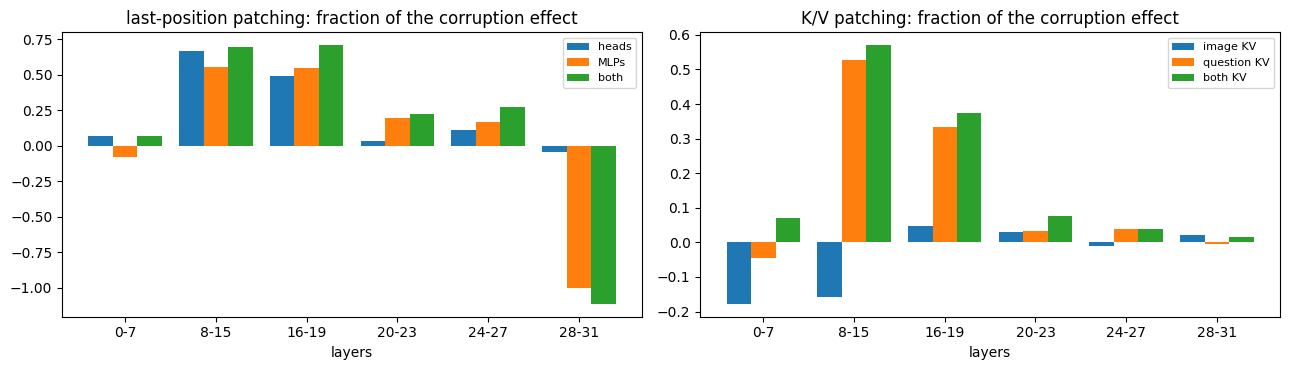

In [5]:
try:
    # STEP 7b. PATCHING RESULTS: how much of the clean -> corrupted change does each patch reproduce?
    if RUN_STEP7:
        yes7 = np.array([r["gt"] == "yes" for r in EVAL7]); sg = np.where(yes7, 1.0, -1.0)
        tot = (sg * (LDC - LD0)).mean()                               # mean shift towards the correct answer when the WHOLE input is corrupted (negative = corruption hurts)
        print(f"{CONTROL_MODE}: clean AUROC {auroc(LD0, yes7):.3f} acc {((LD0 > 0) == yes7).mean():.3f} | corrupted AUROC {auroc(LDC, yes7):.3f} acc {((LDC > 0) == yes7).mean():.3f} | mean signed shift of the full corruption {tot:+.3f} logits")
        def table(A, kinds, title):
            rows = []
            for w, (lo, hi) in enumerate(WINDOWS):
                row = {"layers": f"{lo}-{hi}"}
                for k, kn in enumerate(kinds):
                    sh = (sg * (A[:, w, k] - LD0)).mean(); row[f"{kn}: shift"] = sh; row[f"{kn}: frac"] = sh / tot if abs(tot) > 1e-9 else np.nan; row[f"{kn}: AUROC"] = auroc(A[:, w, k], yes7)
                rows.append(row)
            df = pd.DataFrame(rows); print(f"\n{title} (shift = mean signed change of the logit difference towards the correct answer; frac = shift / full-corruption shift)"); print(df.round(3).to_string(index=False)); return df
        T7a = table(LAST, ["heads", "MLPs", "both"], "LAST-POSITION PATCHING (clean activations replaced by corrupted ones at the final token)")
        T7a.to_csv(f"{DLA_DIR}/patch_last_position.csv", index=False)
        if KV_OK:
            T7b = table(KV, ["image KV", "question KV", "both KV"], "K/V PATCHING (keys and values of the image tokens / question tokens, in a window of layers, replaced by the corrupted run's)")
            T7b.to_csv(f"{DLA_DIR}/patch_kv.csv", index=False)
        else: print("\nK/V patching skipped for CONTROL_MODE =", CONTROL_MODE, "(sequence lengths differ)")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(1, 2 if KV_OK else 1, figsize=(13 if KV_OK else 6.5, 3.8), squeeze=False)
        xs = np.arange(len(WINDOWS)); lab = [f"{lo}-{hi}" for lo, hi in WINDOWS]
        for k, kn in enumerate(["heads", "MLPs", "both"]): ax[0, 0].bar(xs + (k - 1) * 0.27, T7a[f"{kn}: frac"], 0.27, label=kn)
        ax[0, 0].set_xticks(xs); ax[0, 0].set_xticklabels(lab); ax[0, 0].set_title("last-position patching: fraction of the corruption effect"); ax[0, 0].set_xlabel("layers"); ax[0, 0].legend(fontsize=8)
        if KV_OK:
            for k, kn in enumerate(["image KV", "question KV", "both KV"]): ax[0, 1].bar(xs + (k - 1) * 0.27, T7b[f"{kn}: frac"], 0.27, label=kn)
            ax[0, 1].set_xticks(xs); ax[0, 1].set_xticklabels(lab); ax[0, 1].set_title("K/V patching: fraction of the corruption effect"); ax[0, 1].set_xlabel("layers"); ax[0, 1].legend(fontsize=8)
        plt.tight_layout(); plt.savefig(f"{DLA_DIR}/patching_sweeps.png"); plt.show()
except Exception:
    import traceback; traceback.print_exc()
    print("\n>>> THIS CELL FAILED (traceback above). Results saved by earlier cells are untouched. <<<")
    if not globals().get("SOFT_FAIL", True): raise


# Step 7: patching sweeps. Results and conclusions

**Setting.** JEPA-VLM (I-JEPA ViT-H/16 → projector → Vicuna-7B-v1.5, 4-bit), noise corruption ($k=0.5$), 300 balanced POPE questions (158 present, 142 absent; first 300 of the step 4/6 evaluation set). For each window of layers the clean run is patched with the corrupted run's activations in two ways:

- **Last-position patching:** the outputs of all heads, all MLPs, or both at the final token, in the window.
- **K/V patching:** the cached keys and values of the **image tokens**, of the **text tokens** (BOS, instruction and question; called "question" below), or both, in the window.

Metric: $\text{frac}=\text{shift}/\text{full-corruption shift}$, where shift is the mean change of $\Delta=\text{logit(Yes)}-\text{logit(No)}$ toward the correct answer. 95% intervals are bootstrap intervals of the ratio (2000 resamples). For balanced classes the signed shift is essentially half of the loss in the present–absent gap, so $\text{frac}$ is approximately the **share of the gap loss that the patch reproduces**.

**Baselines.** Clean: AUROC $0.818$, accuracy $0.703$, yes-rate $0.437$, gap $0.688$. Corrupted: AUROC $0.516$, accuracy $0.520$, yes-rate $0.660$, gap $0.032$. Full-corruption signed shift: $-0.311$ [−0.397, −0.225].

---

## 1. Conclusions

1. **Image information reaches the answer through layers 8–19 and almost nothing else.** Patching all last-position heads and MLPs together in layers 8–15 reproduces $0.70$ [0.40, 0.97] of the effect and in layers 16–19 $0.71$ [0.60, 0.87]. Layers 0–7 reproduce $0.07$ [−0.25, 0.31], layers 20–23 $0.22$ [0.04, 0.49] and layers 24–27 $0.28$ [0.04, 0.62].
2. **The last token does not read the image tokens directly.** Patching the image-token keys and values reproduces nothing in any window: $-0.157$ [−0.212, −0.116] in 8–15, $+0.048$ [0.027, 0.070] in 16–19, and $\le0.03$ elsewhere.
3. **The last token reads the image information from the text-token positions.** Patching the text-token keys and values reproduces $0.527$ [0.395, 0.672] of the effect in layers 8–15 and $0.334$ [0.249, 0.418] in layers 16–19, and nothing from layer 20 on ($0.033$, $0.038$, $-0.004$). Difference text − image: $+0.684$ [0.539, 0.861] in 8–15 and $+0.286$ [0.210, 0.362] in 16–19.
4. **Both heads and MLPs at the last position carry the effect, redundantly.** In 8–15 heads reproduce $0.66$ [0.43, 0.91] and MLPs $0.56$ [0.15, 0.92]; in 16–19 heads $0.49$ [0.39, 0.62] and MLPs $0.55$ [0.45, 0.68]. Together they reproduce $0.70$ and $0.71$, far less than the sum of the parts, so they carry overlapping information.
5. **After layer ~19 the image information is already inside the last-position residual stream.** Neither last-position patches nor K/V patches in layers 20–27 reproduce more than about a quarter of the effect, and their per-question effect is negatively correlated with the total effect ($r=-0.30$ and $-0.32$), consistent with downstream compensation.
6. **The late MLPs (28–31) regulate gain and bias; they do not transmit the image effect.** Patching their outputs from the corrupted run drives the yes-rate to $0.98$ and widens the margin (sd $0.62\to1.25$). Their $\text{frac}$ of $-1.0$ is an artefact of that bias and the class imbalance, not a sign that the corruption "helps".
7. **Corruption removes evidence and adds a yes-bias, and both enter in layers 8–15.** Patching the last-position heads, MLPs or both in 8–15 sends the yes-rate to $0.90$–$0.96$ (accuracy on absent objects $0.03$–$0.13$). Patching only the text-token K/V in 8–15 reproduces the corrupted run's behaviour closely: yes-rate $0.64$ (corrupted $0.66$), gap $0.33$.

---

## 2. Results

### Last-position patching

| Layers | Heads: frac [CI] | MLPs: frac [CI] | Both: frac [CI] | Both: AUROC | Both: yes-rate |
|---|---|---|---|---|---|
| 0–7 | 0.07 [−0.25, 0.31] | −0.08 [−0.48, 0.22] | 0.07 [−0.25, 0.31] | 0.784 | 0.84 |
| 8–15 | **0.66** [0.43, 0.91] | **0.56** [0.15, 0.92] | **0.70** [0.40, 0.97] | 0.629 | 0.96 |
| 16–19 | **0.49** [0.39, 0.62] | **0.55** [0.45, 0.68] | **0.71** [0.60, 0.87] | 0.706 | 0.57 |
| 20–23 | 0.03 [−0.01, 0.08] | 0.19 [0.06, 0.39] | 0.22 [0.04, 0.49] | 0.793 | 0.18 |
| 24–27 | 0.11 [0.01, 0.24] | 0.17 [−0.03, 0.45] | 0.27 [0.04, 0.62] | 0.772 | 0.13 |
| 28–31 | −0.04 [−0.12, 0.02] | −1.00 [−2.30, −0.07] | −1.11 [−2.65, −0.05] | 0.750 | 1.00 |

### K/V patching

| Layers | Image KV: frac [CI] | Text KV: frac [CI] | Both KV: frac [CI] | Text KV: AUROC |
|---|---|---|---|---|
| 0–7 | −0.18 [−0.47, 0.03] | −0.05 [−0.28, 0.13] | 0.07 [−0.25, 0.31] | 0.790 |
| 8–15 | −0.16 [−0.21, −0.12] | **0.53** [0.40, 0.67] | **0.57** [0.45, 0.73] | 0.703 |
| 16–19 | 0.05 [0.03, 0.07] | **0.33** [0.25, 0.42] | **0.38** [0.28, 0.47] | 0.796 |
| 20–23 | 0.03 [−0.00, 0.07] | 0.03 [−0.00, 0.08] | 0.08 [0.01, 0.17] | 0.818 |
| 24–27 | −0.01 [−0.03, 0.00] | 0.04 [−0.02, 0.12] | 0.04 [−0.02, 0.11] | 0.819 |
| 28–31 | 0.02 [−0.04, 0.07] | −0.00 [−0.07, 0.05] | 0.01 [−0.09, 0.09] | 0.803 |

In window 0–7 the "both" rows equal the last-position heads row exactly. This is expected: with all heads in layers 0–7 patched at the last position, the residual stream is already the corrupted run's, so patching the MLPs on top adds nothing. The same holds for the K/V "both" case.

### Per-question agreement with the full corruption effect

Correlation, over questions, between a patch's shift and the full-corruption shift:

| Layers | Last position, both | Text KV | Image KV |
|---|---|---|---|
| 0–7 | 0.51 | 0.46 | 0.36 |
| 8–15 | 0.62 | 0.67 | **−0.43** |
| 16–19 | **0.75** | **0.76** | 0.49 |
| 20–23 | −0.30 | −0.17 | −0.34 |
| 24–27 | −0.32 | −0.29 | 0.35 |
| 28–31 | 0.44 | 0.47 | 0.49 |

The patches in 8–19 track the per-question corruption effect (r up to 0.76); the ones in 20–27 are anti-correlated with it.

### Margin structure of selected patches

| Patch | mean $\Delta$ | sd | gap | yes-rate | acc. present | acc. absent |
|---|---|---|---|---|---|---|
| clean | −0.108 | 0.624 | 0.688 | 0.437 | 0.633 | 0.782 |
| corrupted | +0.192 | 0.548 | 0.032 | 0.660 | 0.671 | 0.352 |
| last-pos. heads 8–15 | +0.599 | 0.423 | 0.198 | 0.903 | 0.937 | 0.134 |
| last-pos. both 16–19 | +0.077 | 0.326 | 0.227 | 0.573 | 0.715 | 0.585 |
| text KV 8–15 | +0.182 | 0.479 | 0.328 | 0.637 | 0.759 | 0.500 |
| last-pos. MLPs 28–31 | +2.280 | 1.252 | 1.058 | 0.983 | 1.000 | 0.035 |

Fraction of answers changed relative to the clean model (present / absent): corruption 0.39 / 0.57; text KV 8–15: 0.20 / 0.32; image KV 8–15: 0.04 / 0.04.

---

## 3. How this fits steps 3–6

- **Step 6 / 6x (what is necessary):** mean-ablating MLP windows 16–19 and 16–23 costs the most AUROC ($-0.054$, $-0.071$). Step 7 patching the same last-position MLPs gives a similar AUROC ($0.757$ vs clean $0.818$), so the two tests agree there.
- **Patching vs ablation for heads.** Mean-ablating heads barely changes AUROC (step 6), but patching the heads of 8–15 with the corrupted values drops AUROC to $0.632$ and reproduces 66% of the effect. These are different questions: ablation tests whether the information is *necessary*, patching whether it is *sufficient to carry the corrupted state*. The heads' information is redundant (others can replace it) but is read downstream, so a wrong value misleads.
- **Step 5 (where the effect appears at the last position):** the direct effect builds up in MLPs 16–23 (L18, L20, L23). Step 7 adds that this effect is fed by information routed through text-token positions in layers 8–19, not by direct reading of the image tokens.
- **Late MLPs:** 5d and 6x describe L28–L31 as gain-like (removal widens the margin); step 7 shows the same (bias and spread) and the negative per-question correlation of layers 20–27 fits compensation.

### Overall picture (noise-mode, last-position view)

1. Layers 0–7: no detectable image-dependent signal at the last token or in K/V.
2. Layers 8–19: image information, already moved into the text-token positions, is read by the last token (K/V of text tokens, then last-position heads and MLPs). This is the only stage whose corruption reproduces most of the effect. The yes-bias of the noise run also enters here.
3. Layers 16–23: the evidence MLPs turn this into the yes/no evidence (steps 5 and 6x); mean-ablation of 16–19 hurts most.
4. Layers 20–31: no new image information needed; the late MLPs set the gain and threshold, and partly counter the earlier stages.

---

## 4. Caveats

- **n = 300**, one run, noise corruption only; `shuffle` and `none` are not tested (K/V patching is not available for `none`). Several fractions have wide intervals (0–7, 20–27, 28–31).
- **$\text{frac}$ is a ratio with a small denominator** ($|{-0.311}|$ versus per-question sd $\approx0.7$). It also mixes the loss of evidence with bias: a large mean shift towards Yes also moves the signed shift when the classes are unequal (158 present vs 142 absent). This is small for most windows but makes the 28–31 MLP value ($-1.0$) meaningless as an effect size.
- **Corrupted activations are off-distribution** (noise tokens, yes-rate 0.66), so patching them in transfers a bias as well as missing evidence. A window that "reproduces" the effect is sufficient to carry the corrupted state; it is not shown to be the only place where the evidence lives.
- **"Text-token K/V" includes BOS, the instruction and the question tokens.** The experiment does not say which of these carries the image information.
- Image-token K/V patching only changes what the *last token* reads from the image. It says nothing about how text positions themselves acquire image information in earlier layers.
- Patches in different routes overlap (text KV 8–15 $0.53$ vs last-position both $0.70$; difference $-0.17$ [−0.37, 0.06], not significant), so the contributions are not additive.
- First-order: windows are coarse and non-overlapping; finer windows (e.g. 4 layers in 8–19) were not run. About 36 patch types were tested without correction for multiple comparisons.

---

## 5. Suggested follow-up

1. **Finer windows in 8–19** (4 layers each) for last-position and text-token K/V patching, to locate where the information is moved.
2. **Split the text tokens** into BOS / instruction / question / "ASSISTANT:" to find which positions hold the image information.
3. **Patch the text positions' residual streams, and patch the image K/V in the prefix computation of text tokens**, to see where the text tokens read the image.
4. **Mean-ablate window heads** (8–15, 16–19) to compare directly with the patching result for heads.
5. **`shuffle` run** (K/V patching is available) to check that layers 8–19 and the text-token route hold under an in-distribution corruption.

# Object hallucination in a JEPA-VLM: final findings (steps 3–7)

**Model.** Frozen I-JEPA ViT-H/16 → trained MLP projector (`best.pt`) → frozen Vicuna-7B-v1.5 (4-bit). Task: POPE yes/no. $\Delta=\text{logit(Yes)}-\text{logit(No)}$. Layout: [784 image tokens][BOS][prompt]; all "last-position" results are at the final token.
**Corruption.** Image embedding replaced by $\text{proj}+k\sigma\varepsilon$, $k=0.5$ (noise mode only).

> Note: `task_document.pdf` in the Project has no extractable text, so I could not read it. The questions in §1 are the ones this work was driving at, as I understood them across the session. If your task document words them differently, tell me and I will remap §2.

---

## 1. The questions

- **Q1.** Does the model's yes/no answer actually depend on the image, and how well?
- **Q2.** *Where* in the network is the image evidence turned into the answer (which layers, heads, MLPs)?
- **Q3.** Is that localisation causal and specific, or an artefact of how we measure?
- **Q4.** *How* does the image information travel to the answer position (directly from image tokens or via other tokens)?
- **Q5.** What separates correct answers from hallucinations mechanistically? (partly answered; see §4)
- **Q6.** What carries over beyond this one model? (§3)

---

## 2. Answers

### Q1. The answer depends on the image, but only moderately
- Clean model: AUROC $\approx 0.81$–$0.82$, accuracy $\approx 0.70$ (n=400 / 300).
- Noise-corrupted image: AUROC $0.516$ (chance), accuracy $0.520$, yes-rate rises $0.44\to0.66$, accuracy on *absent* objects falls $0.78\to0.35$.
- So removing the image does not add random errors: it collapses the model to a **yes-leaning prior** that carries no truth signal (corrupted-$\Delta$ AUROC $0.52$; the prior does not predict correctness, step 5d §7). Hallucination here is that prior winning when evidence is weak.

### Q2. The evidence is built by MLPs in layers 16–23 at the last position, from information injected in layers 8–19
- **Step 5 (attribution patching, direct effects):** L18.mlp carries the largest image-dependent share of the effect variance (44%), L23.mlp 17%, then L16/17/20 (4–6% each). The evidence MLPs $\{16,17,18,20,23\}$ discriminate present/absent (AUROC $0.78$) *better than the total image effect* ($0.73$). Heads are diffuse (top 100 heads $=60\%$ of $\sum|\text{truth part}|$).
- **Step 6 / 6x (mean-ablation, CIs, random controls):**

| Ablation (last position) | $\Delta$AUROC |
|---|---|
| evidence MLPs | $-0.057$ [−0.076, −0.039] (random MLPs of same size: $-0.006\pm0.009$) |
| MLPs 16–19 / 16–23 | $-0.054$ / $-0.071$ (below all random minima) |
| MLPs 28–31 | $-0.040$ (not evidence; gain, see below) |
| all second-half MLPs (16) | $-0.202$ vs random16 $-0.078\pm0.042$ |
| second-half heads | $+0.024$ |
| evidence heads | $-0.011$ |

- **Step 7 (patching the clean run with the corrupted run's activations):** last-position heads+MLPs in 8–15 reproduce $0.70$ [0.40, 0.97] of the corruption effect, in 16–19 $0.71$ [0.60, 0.87]; 0–7 gives $0.07$; 20–27 give $0.22$–$0.27$.

**Conclusion:** image-dependent evidence is injected in layers 8–19 and made decision-relevant mostly by MLPs 16–23 (strongest 16–19). Early layers (0–7) and late layers (20–31) are not where the image information is added.

### Q3. The localisation is causal and specific, but not what single-component tests suggest
- **Specificity:** the evidence MLPs and the 16–19/16–23 windows fall *below every matched random set*; 11 non-evidence second-half MLPs do no more than random ($-0.016$ vs $-0.013$).
- **Non-additivity:** ablating the 16 second-half MLPs costs $-0.202$ while the additive prediction is $-0.073$; interaction $-0.128$ [−0.165, −0.093]. MLPs compensate for each other, so one-at-a-time ablation understates their joint role. Evidence and opposing MLPs are anti-correlated per question ($r=-0.76$ absent, $-0.68$ present), consistent with compensation (it cannot by itself prove it).
- **Late MLPs (28–31) are gain/bias, not evidence:** patching them from the corrupted run drives yes-rate to $0.98$ and doubles the margin spread ($0.62\to1.25$); their per-question variation is a "gain" axis unrelated to truth (step 5 PCA, PC1 AUROC $0.60$).
- **Heads:** diffuse and redundant. Mean-ablating them barely moves AUROC, yet *patching* heads of 8–15 with corrupted values reproduces $0.66$ [0.43, 0.91] of the effect. Ablation tests necessity (information can be replaced); patching tests whether a wrong value is read and believed. Both statements are true.

### Q4. The last token reads the image through the *text* positions, not the image tokens
| Layers | image-token K/V patched | text-token K/V patched |
|---|---|---|
| 8–15 | $-0.157$ [−0.212, −0.116] | **0.527** [0.395, 0.672] |
| 16–19 | $0.048$ [0.027, 0.070] | **0.334** [0.249, 0.418] |
| 20–31 | $\le 0.03$ | $\le 0.04$ |

Text − image difference in 8–15: $+0.684$ [0.539, 0.861]. So the image information has already been copied into BOS/instruction/question positions by layers ~8–19 and the answer token reads it from there; after layer ~20 no further image reading is needed. (Which text positions: not yet resolved.)

### Q5. What separates correct from wrong answers (descriptive, step 5d)
- Within each class the level of **L18.mlp** differs by $\approx0.4$–$0.5$ between right and wrong answers (>1 sd), while L20/L28 hardly change. A linear "replace L18 by its correct-answer mean" what-if flips $73\%$ of false negatives and $83\%$ of false positives, an **upper bound** that ignores compensation and is partly circular.
- This is a screening result, not a demonstrated cause of individual errors. Its causal test (patching L18 from correct to incorrect examples) was **not run**.

---

## 3. Results that are likely to generalise (stated with their evidence level)

1. **Use a threshold-free metric and report the yes-rate.** Corruption and ablation shift the decision bias a lot (yes-rate $0.44\to0.66$; $0.98$ after patching MLPs 28–31). Accuracy mixes bias with discrimination; AUROC (and the present/absent gap) separate them. *Evidence: observed throughout; this is a measurement lesson, not model-specific.*
2. **Matched random controls can overturn a finding.** In step 4 I claimed that only grounding-selected components drop AUROC; random matched sets drop equally ($0.607$–$0.798$), so that claim was retracted. Selection by an attribution score is not evidence of specificity until random sets of the same size and layer range are beaten. *Evidence: a concrete reversal inside this study.*
3. **Attribution share is not necessity.** DLA/AtP ranked L18 as the top component; ablating it did not give the largest single drop (L28 $-0.015$, L16 $-0.012$ were larger). Rankings from direct-effect attribution should be validated by intervention. *Evidence: failed pre-registered prediction.*
4. **Ablation, patching and attribution answer different questions** (necessity, sufficiency to carry a corrupted state, first-order direct contribution). Disagreement between them (heads here) is information about redundancy, not an error. *Evidence: heads show ~0 under ablation but 0.66 under patching.*
5. **Redundant, compensating components break single-unit analysis.** Interaction $-0.128$ is larger than the additive effect ($-0.073$). Analyses that test one component at a time will under-report distributed mechanisms; use window/set ablations with random baselines and an additive-vs-joint check. *Evidence: one model, but a large effect.*
6. **Fraction-of-effect metrics are fragile when the effect is small** (full-corruption shift $-0.311$ vs per-question sd $\approx0.7$): ratios have wide CIs and can go negative when a patch adds bias (28–31 MLP: $-1.0$). Report the signed shift and margin structure alongside any ratio.
7. **Hallucination as an unmasked prior.** Removing visual evidence leaves a yes-biased prior with no truth signal; hallucinated "yes" on absent objects is the model's default when evidence is weak. This fits the literature's language-prior account; here it is demonstrated with a counterfactual image, in one model.
8. **A non-language-aligned encoder (I-JEPA) with a small trained projector yields a usable yes/no circuit** (AUROC $\approx0.82$) built on the same LLM-side machinery as other VLMs (mid-layer information transfer via text tokens, mid-to-late MLP evidence, late gain control). This suggests the hallucination-relevant computation sits mostly in the LLM, not in the vision–language alignment of the encoder. *Evidence level: suggestive. It needs the LLaVA comparison (Rohan's DLA) to be a claim.*

Relation to the dual-pathway paper in the Project (arXiv 2605.13156): our "evidence MLPs vs opposing MLPs" coupling resembles its grounding/hallucination pathway picture, and our random-set control mirrors its random-component control. The polarity-flip analysis (CPA) was not run here.

---

## 4. What is not established

- **Noise mode only.** `shuffle` and `none` controls are not run (and K/V patching is not defined for `none`). The yes-bias is partly a property of noise inputs.
- **No direct LLaVA comparison yet**, so JEPA-specific vs general is unresolved (point 8 above).
- **Small samples:** n=300–600, one run, one model, one dataset (POPE). No correction for multiple comparisons across ~36 patches and 53 ablation configs. Several window estimates have wide CIs (0–7, 20–31).
- **Hallucination-specific causal test missing:** we explain the *image effect*; we did not intervene on individual incorrect answers, and no mitigation was tested.
- **"Text-token K/V"** lumps BOS, instruction and question; which carries the image information is open.
- Corrupted activations are off-distribution, so patching them transfers bias as well as missing evidence.

## 5. Highest-value next steps
1. Run `shuffle` mode and repeat steps 6–7 (checks that 8–19 / 16–23 survive an in-distribution corruption).
2. LLaVA-1.5 versions of steps 6 and 7 (windows and text-vs-image K/V) to test point 8.
3. Split text tokens (BOS / instruction / question / "ASSISTANT:") in the K/V patch; finer 4-layer windows in 8–19.
4. Patch L18.mlp (and 16–19) between correct and incorrect examples of the same class, to test Q5 causally.
5. Use the found 16–23 evidence set as a mitigation target and compare against random sets on POPE accuracy and yes-rate.

---
Detailed per-step write-ups: `step5d_per_question.md`, `step6_findings_conclusions.md`, `step7_results.md`, `step4d_results.md` (with correction).

The task is the JEPA encoder swap: if hallucination representations look qualitatively different under JEPA, the hallucination is at least partly encoder-driven. Otherwise it is more likely a language-model binding failure.

Why it leans language-model side: with an I-JEPA encoder and a small trained projector, the model still builds a clear yes/no evidence signal (AUROC about 0.82). That signal comes from the kind of LLM-internal machinery I’d expect in a CLIP model. The image information is moved into text positions in layers 8–19, the evidence MLPs sit in 16–23, and the late MLPs control gain. Swapping the encoder didn’t create a new mechanism. The CLIP comparison here is from my knowledge of the literature, not re-checked.
Why it isn’t decidable: everything so far is on the JEPA model, and the verdict needs the same steps 6–7 on the CLIP-LLaVA baseline. Our 0.70 accuracy is below published LLaVA-1.5 POPE numbers in the mid-80s, but the setups differ (our projector, 4-bit Vicuna, small balanced subset), so I can’t blame the encoder for that gap.
Scope gap: we only studied object-existence (POPE) hallucination. The task targets attribute and relation hallucination, and our circuit may not transfer there.

# Object hallucination in a JEPA-VLM: final findings (steps 3–7)

**Model.** Frozen I-JEPA ViT-H/16 → trained MLP projector (`best.pt`) → frozen Vicuna-7B-v1.5 (4-bit). Task: POPE yes/no. $\Delta=\text{logit(Yes)}-\text{logit(No)}$. Layout: [784 image tokens][BOS][prompt]; all "last-position" results are at the final token.
**Corruption.** Image embedding replaced by $\text{proj}+k\sigma\varepsilon$, $k=0.5$ (noise mode only).

> **Task (from the task document).** *Parallel track: JEPA encoder swap.* Replace LLaVA's CLIP-style encoder with a JEPA-style self-supervised encoder (no generative or contrastive-language objective) and re-run the first two diagnostic stages. If the hallucination representations look qualitatively different under JEPA, the hallucination is at least partly **encoder-driven**; if not, it is more likely a **language-model binding failure**.

## 0. Verdict on the task question

**Not decidable from what we have, but the evidence so far leans toward "language-model side".** All our results are on the JEPA-VLM; the decisive comparison needs the same measurements on the CLIP-LLaVA baseline (Rohan's DLA, and our steps 6–7 ported to it). Also, we studied **object-existence** (POPE) hallucination, not attribute/relation hallucination, which is what the task document targets.

What we can say now:
- **Lean toward LM-side:** with a JEPA encoder and a small trained projector the model still forms a clear yes/no evidence signal (AUROC $\approx0.82$), built by the same kind of LLM-internal machinery one would expect in a CLIP model (information moved to text positions in layers 8–19, evidence MLPs 16–23, late-MLP gain control). The failure mode (yes-prior taking over when evidence is weak) lives in LLM layers 16–31.
- **Against an "encoder is the whole story" reading:** the hallucination-relevant circuit is identical in nature to what is reported for CLIP-based VLMs in the literature, so swapping the encoder did not create a new mechanism. (Literature comparison from my knowledge, not re-verified here.)
- **What would still support "partly encoder-driven":** our accuracy ($0.70$) is below published LLaVA-1.5 POPE numbers (mid-80s %). The setups are not like-for-like (our projector, 4-bit Vicuna, 300–600 questions, balanced subset), so this gap cannot be attributed to the encoder yet. If a like-for-like gap persists, the encoder's representation quality is at least partly responsible for weaker evidence, not necessarily for hallucination type.
- **Pre-specified decision criteria for the comparison** (so it is not post hoc): the JEPA run is "qualitatively different" if (i) the evidence layers shift (MLP windows other than 16–23 / injection window other than 8–19), (ii) image-token K/V gains a direct role (frac $>0.2$ with CI excluding 0), or (iii) the AUROC drop of the evidence-MLP ablation is outside the CLIP model's random-set range. Otherwise treat the mechanisms as the same and attribute the difference to the LM.

---

## 1. The questions (mapped to the task)

- **Q1.** Does the model's yes/no answer actually depend on the image, and how well?
- **Q2.** *Where* in the network is the image evidence turned into the answer (which layers, heads, MLPs)?
- **Q3.** Is that localisation causal and specific, or an artefact of how we measure?
- **Q4.** *How* does the image information travel to the answer position (directly from image tokens or via other tokens)?
- **Q5.** What separates correct answers from hallucinations mechanistically? (partly answered; see §4)
- **Q6.** What carries over beyond this one model, and what does that say about encoder vs LM origin? (§0, §3)

---

## 2. Answers

### Q1. The answer depends on the image, but only moderately
- Clean model: AUROC $\approx 0.81$–$0.82$, accuracy $\approx 0.70$ (n=400 / 300).
- Noise-corrupted image: AUROC $0.516$ (chance), accuracy $0.520$, yes-rate rises $0.44\to0.66$, accuracy on *absent* objects falls $0.78\to0.35$.
- So removing the image does not add random errors: it collapses the model to a **yes-leaning prior** that carries no truth signal (corrupted-$\Delta$ AUROC $0.52$; the prior does not predict correctness, step 5d §7). Hallucination here is that prior winning when evidence is weak.

### Q2. The evidence is built by MLPs in layers 16–23 at the last position, from information injected in layers 8–19
- **Step 5 (attribution patching, direct effects):** L18.mlp carries the largest image-dependent share of the effect variance (44%), L23.mlp 17%, then L16/17/20 (4–6% each). The evidence MLPs $\{16,17,18,20,23\}$ discriminate present/absent (AUROC $0.78$) *better than the total image effect* ($0.73$). Heads are diffuse (top 100 heads $=60\%$ of $\sum|\text{truth part}|$).
- **Step 6 / 6x (mean-ablation, CIs, random controls):**

| Ablation (last position) | $\Delta$AUROC |
|---|---|
| evidence MLPs | $-0.057$ [−0.076, −0.039] (random MLPs of same size: $-0.006\pm0.009$) |
| MLPs 16–19 / 16–23 | $-0.054$ / $-0.071$ (below all random minima) |
| MLPs 28–31 | $-0.040$ (not evidence; gain, see below) |
| all second-half MLPs (16) | $-0.202$ vs random16 $-0.078\pm0.042$ |
| second-half heads | $+0.024$ |
| evidence heads | $-0.011$ |

- **Step 7 (patching the clean run with the corrupted run's activations):** last-position heads+MLPs in 8–15 reproduce $0.70$ [0.40, 0.97] of the corruption effect, in 16–19 $0.71$ [0.60, 0.87]; 0–7 gives $0.07$; 20–27 give $0.22$–$0.27$.

**Conclusion:** image-dependent evidence is injected in layers 8–19 and made decision-relevant mostly by MLPs 16–23 (strongest 16–19). Early layers (0–7) and late layers (20–31) are not where the image information is added.

### Q3. The localisation is causal and specific, but not what single-component tests suggest
- **Specificity:** the evidence MLPs and the 16–19/16–23 windows fall *below every matched random set*; 11 non-evidence second-half MLPs do no more than random ($-0.016$ vs $-0.013$).
- **Non-additivity:** ablating the 16 second-half MLPs costs $-0.202$ while the additive prediction is $-0.073$; interaction $-0.128$ [−0.165, −0.093]. MLPs compensate for each other, so one-at-a-time ablation understates their joint role. Evidence and opposing MLPs are anti-correlated per question ($r=-0.76$ absent, $-0.68$ present), consistent with compensation (it cannot by itself prove it).
- **Late MLPs (28–31) are gain/bias, not evidence:** patching them from the corrupted run drives yes-rate to $0.98$ and doubles the margin spread ($0.62\to1.25$); their per-question variation is a "gain" axis unrelated to truth (step 5 PCA, PC1 AUROC $0.60$).
- **Heads:** diffuse and redundant. Mean-ablating them barely moves AUROC, yet *patching* heads of 8–15 with corrupted values reproduces $0.66$ [0.43, 0.91] of the effect. Ablation tests necessity (information can be replaced); patching tests whether a wrong value is read and believed. Both statements are true.

### Q4. The last token reads the image through the *text* positions, not the image tokens
| Layers | image-token K/V patched | text-token K/V patched |
|---|---|---|
| 8–15 | $-0.157$ [−0.212, −0.116] | **0.527** [0.395, 0.672] |
| 16–19 | $0.048$ [0.027, 0.070] | **0.334** [0.249, 0.418] |
| 20–31 | $\le 0.03$ | $\le 0.04$ |

Text − image difference in 8–15: $+0.684$ [0.539, 0.861]. So the image information has already been copied into BOS/instruction/question positions by layers ~8–19 and the answer token reads it from there; after layer ~20 no further image reading is needed. (Which text positions: not yet resolved.)

### Q5. What separates correct from wrong answers (descriptive, step 5d)
- Within each class the level of **L18.mlp** differs by $\approx0.4$–$0.5$ between right and wrong answers (>1 sd), while L20/L28 hardly change. A linear "replace L18 by its correct-answer mean" what-if flips $73\%$ of false negatives and $83\%$ of false positives, an **upper bound** that ignores compensation and is partly circular.
- This is a screening result, not a demonstrated cause of individual errors. Its causal test (patching L18 from correct to incorrect examples) was **not run**.

---

## 3. Results that are likely to generalise (stated with their evidence level)

1. **Use a threshold-free metric and report the yes-rate.** Corruption and ablation shift the decision bias a lot (yes-rate $0.44\to0.66$; $0.98$ after patching MLPs 28–31). Accuracy mixes bias with discrimination; AUROC (and the present/absent gap) separate them. *Evidence: observed throughout; this is a measurement lesson, not model-specific.*
2. **Matched random controls can overturn a finding.** In step 4 I claimed that only grounding-selected components drop AUROC; random matched sets drop equally ($0.607$–$0.798$), so that claim was retracted. Selection by an attribution score is not evidence of specificity until random sets of the same size and layer range are beaten. *Evidence: a concrete reversal inside this study.*
3. **Attribution share is not necessity.** DLA/AtP ranked L18 as the top component; ablating it did not give the largest single drop (L28 $-0.015$, L16 $-0.012$ were larger). Rankings from direct-effect attribution should be validated by intervention. *Evidence: failed pre-registered prediction.*
4. **Ablation, patching and attribution answer different questions** (necessity, sufficiency to carry a corrupted state, first-order direct contribution). Disagreement between them (heads here) is information about redundancy, not an error. *Evidence: heads show ~0 under ablation but 0.66 under patching.*
5. **Redundant, compensating components break single-unit analysis.** Interaction $-0.128$ is larger than the additive effect ($-0.073$). Analyses that test one component at a time will under-report distributed mechanisms; use window/set ablations with random baselines and an additive-vs-joint check. *Evidence: one model, but a large effect.*
6. **Fraction-of-effect metrics are fragile when the effect is small** (full-corruption shift $-0.311$ vs per-question sd $\approx0.7$): ratios have wide CIs and can go negative when a patch adds bias (28–31 MLP: $-1.0$). Report the signed shift and margin structure alongside any ratio.
7. **Hallucination as an unmasked prior.** Removing visual evidence leaves a yes-biased prior with no truth signal; hallucinated "yes" on absent objects is the model's default when evidence is weak. This fits the literature's language-prior account; here it is demonstrated with a counterfactual image, in one model.
8. **A non-language-aligned encoder (I-JEPA) with a small trained projector yields a usable yes/no circuit** (AUROC $\approx0.82$) built on the same LLM-side machinery as other VLMs (mid-layer information transfer via text tokens, mid-to-late MLP evidence, late gain control). This suggests the hallucination-relevant computation sits mostly in the LLM, not in the vision–language alignment of the encoder. *Evidence level: suggestive. It needs the LLaVA comparison (Rohan's DLA) to be a claim.*

Relation to the dual-pathway paper in the Project (arXiv 2605.13156): our "evidence MLPs vs opposing MLPs" coupling resembles its grounding/hallucination pathway picture, and our random-set control mirrors its random-component control. The polarity-flip analysis (CPA) was not run here.

---

## 4. What is not established

- **Noise mode only.** `shuffle` and `none` controls are not run (and K/V patching is not defined for `none`). The yes-bias is partly a property of noise inputs.
- **No direct LLaVA comparison yet**, so JEPA-specific vs general is unresolved (point 8 above).
- **Small samples:** n=300–600, one run, one model, one dataset (POPE). No correction for multiple comparisons across ~36 patches and 53 ablation configs. Several window estimates have wide CIs (0–7, 20–31).
- **Hallucination-specific causal test missing:** we explain the *image effect*; we did not intervene on individual incorrect answers, and no mitigation was tested.
- **"Text-token K/V"** lumps BOS, instruction and question; which carries the image information is open.
- Corrupted activations are off-distribution, so patching them transfers bias as well as missing evidence.

## 5. Highest-value next steps
1. Run `shuffle` mode and repeat steps 6–7 (checks that 8–19 / 16–23 survive an in-distribution corruption).
2. **LLaVA-1.5 (CLIP) versions of steps 6 and 7** with the same windows, controls and sample set. This is the missing half of the encoder swap; judge by the criteria in §0.
2b. Extend from object existence to **attribute and relation** questions (the task's actual target), since our pathway may not transfer there.
3. Split text tokens (BOS / instruction / question / "ASSISTANT:") in the K/V patch; finer 4-layer windows in 8–19.
4. Patch L18.mlp (and 16–19) between correct and incorrect examples of the same class, to test Q5 causally.
5. Use the found 16–23 evidence set as a mitigation target and compare against random sets on POPE accuracy and yes-rate.

---
Detailed per-step write-ups: `step5d_per_question.md`, `step6_findings_conclusions.md`, `step7_results.md`, `step4d_results.md` (with correction).